# Rush Hour: Predicting Bike-Sharing Demand - the chained pipeline (Phases 1-5)

**Team IDs:** 16002932, 16004208, 16006616  |  **Seed:** 42648  |  Machine Learning, Winter 2026, Project 1

One notebook, five chained phases. **Run the cells from the top to the bottom.** Each phase starts from what the previous phase produced: the weight vector and its hyper-parameters are kept in memory (`ARTIFACTS`) together with the SHA-256 of the weights, and every phase first re-checks that hash. Nothing is written to disk except the final `sample_submission.csv`.

| # | Phase | What it does |
|---|---|---|
| [1](#phase1) | Gradient descent | our own batch gradient descent, linear model |
| [2](#phase2) | Polynomial regression | feature expansion, gradient descent warm-started from Phase 1 |
| [3](#phase3) | Bias-variance tradeoff | complexity ladder; random vs day-grouped vs chronological evaluation |
| [4](#phase4) | Regularization | Ridge, Lasso, Elastic Net (our own proximal gradient descent) |
| [5](#phase5) | Logistic regression | "is this a high-demand hour?" on the features Phase 4 kept |
| [6](#submission) | Test predictions | refit of the recommended regression model, `sample_submission.csv` |

**Where the code is.** Every phase begins with a cell holding the functions it needs (written once, reused by the later phases). Two functions that exist in two phases with the same name carry a suffix: `_p1` ... `_p5` (for example `fit_poly_p2` and `fit_poly_p3`).

**Data.** Only `Datasets/train.csv`, `Datasets/test.csv` and `Datasets/sample_submission.csv` are used. Scalers, encoders, polynomial expansions and feature selection are fitted on training rows only; `test.csv` is only transformed. No sklearn model is ever fitted (sklearn is used for the seeded split, `GroupKFold` and metric cross-checks).

A full run takes about 6 minutes.

<a id="setup"></a>
## Setup

In [1]:
from __future__ import annotations
import sys, platform, json
import numpy, pandas, scipy, sklearn, matplotlib
import numpy as np

# In-memory hand-off between phases: each phase stores its weights + metadata here, the next one reads them.
ARTIFACTS = {}

def _store_npz(stem, **arrays):
    ARTIFACTS.setdefault(stem, {})['npz'] = {k: np.array(v) for k, v in arrays.items()}

def _store_json(stem, meta):
    ARTIFACTS.setdefault(stem, {})['json'] = json.loads(json.dumps(meta))      # same round trip a file would give

def _load_npz(stem):
    return {k: v.copy() for k, v in ARTIFACTS[stem]['npz'].items()}

def _load_json(stem):
    return json.loads(json.dumps(ARTIFACTS[stem]['json']))

print('Python', sys.version.split()[0], '|', platform.platform())
for m in (numpy, pandas, scipy, sklearn, matplotlib): print(f'{m.__name__:<12} {m.__version__}')

Python 3.14.6 | Windows-11-10.0.26300-SP0
numpy        2.5.0
pandas       3.0.3
scipy        1.18.0
sklearn      1.9.1
matplotlib   3.11.2


<a id="phase1"></a>

# Phase 1 — Bike Sharing Demand: Gradient Descent

**Team IDs:** 16002932, 16006616, 16004208  
**Seed:** 42648  
**Rules:** numpy/pandas only for modelling; no sklearn `.fit()`/`.predict()`; `test.csv` read-only (transform only).

## Expectation

- Demand peaks in the morning and evening, so I can't use `hr` as one number. I'll one-hot encode it and the other category columns.
- Some columns say the same thing (season and month, workingday and weekday + holiday). So I expect the weights to be unreliable, but the predictions should be fine.
- Gradient descent should work for learning rates below 2/L and blow up above that. Very small rates should be too slow. I'll pick about 1–1.5/L.
- I expect a validation R² of about 0.6–0.7 with train and validation close together, because a straight-line model is too simple for this data (underfitting).

### Phase 1: the functions this phase uses

The code below is defined once here and reused by every later phase.

In [2]:
"""
Reusable functions for Phase 1 (Gradient Descent) and Phase 2.
"""


import hashlib
import json
from typing import Callable, Optional

import numpy as np
import pandas as pd


def compute_seed(student_ids: list[str]) -> int:
    """Deterministic seed from student IDs."""
    joined = "_".join(sorted(student_ids))
    hex_digest = hashlib.sha256(joined.encode()).hexdigest()
    return int(hex_digest, 16) % 100_000


_HR_CATS = list(range(24))
_SEASON_CATS = [1, 2, 3, 4]
_MNTH_CATS = list(range(1, 13))
_WEEKDAY_CATS = list(range(7))
_WEATHER_CATS = [1, 2, 3]  # weathersit=4 is very rare, merge into 3


def fit_preprocessor(train_df: pd.DataFrame, add_windspeed_flag: bool = True) -> dict:
    """Fit all preprocessing parameters on train_df only."""
    df = train_df.copy()

    df["dteday"] = pd.to_datetime(df["dteday"])
    days_origin = df["dteday"].min()
    df["days_since_start"] = (df["dteday"] - days_origin).dt.days

    numeric_cols = ["temp", "atemp", "hum", "windspeed", "days_since_start"]

    scaler_means = {}
    scaler_stds = {}
    for col in numeric_cols:
        mu = float(df[col].mean())
        sig = float(df[col].std(ddof=0))  # population std for determinism
        if sig == 0:
            sig = 1.0
        scaler_means[col] = mu
        scaler_stds[col] = sig

    params = {
        "days_origin": days_origin.strftime("%Y-%m-%d"),
        "scaler_means": scaler_means,
        "scaler_stds": scaler_stds,
        "numeric_cols": numeric_cols,
        "add_windspeed_flag": add_windspeed_flag,
        "hr_cats": _HR_CATS,
        "season_cats": _SEASON_CATS,
        "mnth_cats": _MNTH_CATS,
        "weekday_cats": _WEEKDAY_CATS,
        "weather_cats": _WEATHER_CATS,
    }
    return params


def transform(df: pd.DataFrame, params: dict) -> tuple[np.ndarray, list[str]]:
    """Apply preprocessing to df using params from fit_preprocessor."""
    df = df.copy()

    df["dteday"] = pd.to_datetime(df["dteday"])
    origin = pd.Timestamp(params["days_origin"])
    df["days_since_start"] = (df["dteday"] - origin).dt.days

    df["weathersit"] = df["weathersit"].clip(upper=3)

    add_flag = params["add_windspeed_flag"]
    if add_flag:
        df["is_windspeed_zero"] = (df["windspeed"] == 0.0).astype(float)

    def one_hot(series: pd.Series, cats: list, prefix: str, drop_first: bool = True):
        col_names = [f"{prefix}_{c}" for c in cats]
        arr = np.zeros((len(series), len(cats)), dtype=float)
        for j, c in enumerate(cats):
            arr[:, j] = (series == c).astype(float)
        dummy_df = pd.DataFrame(arr, columns=col_names, index=series.index)
        if drop_first:
            dummy_df = dummy_df.iloc[:, 1:]  # avoid rank deficiency
        return dummy_df

    hr_dummies = one_hot(df["hr"], params["hr_cats"], "hr")
    season_dummies = one_hot(df["season"], params["season_cats"], "season")
    mnth_dummies = one_hot(df["mnth"], params["mnth_cats"], "mnth")
    weekday_dummies = one_hot(df["weekday"], params["weekday_cats"], "weekday")
    weather_dummies = one_hot(df["weathersit"], params["weather_cats"], "weather")

    means = params["scaler_means"]
    stds = params["scaler_stds"]
    scaled_parts = {}
    for col in params["numeric_cols"]:
        scaled_parts[col] = (df[col] - means[col]) / stds[col]

    binary_features = pd.DataFrame({
        "holiday": df["holiday"].values.astype(float),
        "workingday": df["workingday"].values.astype(float),
        "yr": df["yr"].values.astype(float),
    }, index=df.index)

    parts = [
        hr_dummies, season_dummies, mnth_dummies,
        weekday_dummies, weather_dummies, binary_features,
        pd.DataFrame(scaled_parts, index=df.index),
    ]
    if add_flag:
        parts.append(pd.DataFrame(
            {"is_windspeed_zero": df["is_windspeed_zero"].values.astype(float)},
            index=df.index,
        ))

    X_df = pd.concat(parts, axis=1)
    names = list(X_df.columns)
    X = X_df.values.astype(np.float64)

    return X, names


def mse_loss(X: np.ndarray, y: np.ndarray, w: np.ndarray, b: float) -> float:
    """J = 1/(2n) * ||Xw + b - y||^2"""
    r = X @ w + b - y
    return float(0.5 * np.mean(r ** 2))


def r2_score_np(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    """R² = 1 - SS_res / SS_tot"""
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    if ss_tot == 0:
        return 1.0 if ss_res == 0 else 0.0
    return float(1.0 - ss_res / ss_tot)


def rmse_np(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    return float(np.sqrt(np.mean((y_true - y_pred) ** 2)))


def predict(X: np.ndarray, w: np.ndarray, b: float) -> np.ndarray:
    return X @ w + b


def mse_grad(X: np.ndarray, y: np.ndarray, w: np.ndarray, b: float) -> tuple[np.ndarray, float]:
    """MSE gradients. Returns (grad_w, grad_b)."""
    n = len(y)
    r = X @ w + b - y
    grad_w = X.T @ r / n
    grad_b = float(np.mean(r))
    return grad_w, grad_b


def asymmetric_grad(
    X: np.ndarray, y: np.ndarray, w: np.ndarray, b: float, over_weight: float = 3.0, under_weight: Optional[float] = None
) -> tuple[np.ndarray, float]:
    """Asymmetric loss gradient (penalises under-predictions where y > y_hat with weight 3x)."""
    weight = under_weight if under_weight is not None else over_weight
    n = len(y)
    e = y - (X @ w + b)  # positive = under-predicted
    c = np.where(e > 0, weight, 1.0)
    ce = c * e
    grad_w = -2.0 / n * (X.T @ ce)
    grad_b = float(-2.0 / n * np.sum(ce))
    return grad_w, grad_b


def asymmetric_loss(
    X: np.ndarray, y: np.ndarray, w: np.ndarray, b: float, over_weight: float = 3.0, under_weight: Optional[float] = None
) -> float:
    """Asymmetric loss value: mean(c * e^2) where c penalises under-predictions (y > y_hat)."""
    weight = under_weight if under_weight is not None else over_weight
    e = y - (X @ w + b)
    c = np.where(e > 0, weight, 1.0)
    return float(np.mean(c * e ** 2))


def gd_fit(
    X: np.ndarray,
    y: np.ndarray,
    lr: float,
    max_iter: int,
    tol: float = 1e-6,
    gtol: float = 1e-8,
    w0: Optional[np.ndarray] = None,
    b0: float = 0.0,
    grad_fn: Optional[Callable] = None,
    loss_fn: Optional[Callable] = None,
    X_val: Optional[np.ndarray] = None,
    y_val: Optional[np.ndarray] = None,
    record_every: int = 1,
    verbose: bool = False,
    momentum: bool = False,
) -> dict:
    """Hand-written gradient descent for linear regression.

    momentum=True switches to Nesterov accelerated gradient descent: the gradient is taken at the
    look-ahead point z = w + k/(k+3) * (w - w_prev), and the momentum counter k restarts at 0
    whenever the loss goes up (function-value restart). With momentum=False the update is the plain
    w <- w - lr * grad and the numbers are bit-identical to the original implementation.
    """
    if grad_fn is None:
        grad_fn = mse_grad
    if loss_fn is None:
        loss_fn = mse_loss

    n, p = X.shape
    w = np.zeros(p, dtype=np.float64) if w0 is None else w0.copy().astype(np.float64)
    b = float(b0)

    train_losses = []
    val_losses = []

    initial_loss = loss_fn(X, y, w, b)
    if initial_loss == 0.0:
        initial_loss = 1.0

    status = "not_converged"
    prev_loss = initial_loss
    w_prev, b_prev = w, b      # previous iterate (used only by the momentum update)
    k = 0                      # momentum counter

    for it in range(1, max_iter + 1):
        if momentum:
            beta = k / (k + 3.0)
            zw = w + beta * (w - w_prev)
            zb = b + beta * (b - b_prev)
        else:
            zw, zb = w, b
        grad_w, grad_b = grad_fn(X, y, zw, zb)

        w_prev, b_prev = w, b
        w = zw - lr * grad_w
        b = zb - lr * grad_b

        current_loss = loss_fn(X, y, w, b)
        if momentum:
            k = 0 if current_loss > prev_loss else k + 1     # restart momentum when the loss goes up

        if it % record_every == 0 or it == max_iter:
            train_losses.append((it, float(current_loss)))

            if X_val is not None and y_val is not None:
                vl = loss_fn(X_val, y_val, w, b)
                val_losses.append((it, float(vl)))

            if verbose and it % 1000 == 0:
                g_norm_display = float(np.sqrt(np.linalg.norm(grad_w)**2 + grad_b**2))
                print(f"  iter {it:6d}  loss={current_loss:.6f}  |g|={g_norm_display:.2e}  status={status}")

        if not np.isfinite(current_loss) or current_loss > 1e6 * initial_loss:
            status = "diverged"
            break

        g_norm = float(np.sqrt(np.linalg.norm(grad_w)**2 + grad_b**2))
        rel_change = abs(current_loss - prev_loss) / (abs(prev_loss) + 1e-12)

        # Require both small relative loss change AND a small gradient norm (< 1.0)
        # to ensure the optimizer is near a stationary point, not oscillating on a stability boundary
        if (rel_change < tol and g_norm < 1.0) or (g_norm < gtol):
            status = "converged"
            break

        prev_loss = current_loss

    # Ensure the final loss at loop termination is recorded even if off record_every boundary
    if len(train_losses) == 0 or train_losses[-1][0] != it:
        train_losses.append((it, float(current_loss)))
        if X_val is not None and y_val is not None:
            val_losses.append((it, float(loss_fn(X_val, y_val, w, b))))

    final_train_loss = loss_fn(X, y, w, b)
    final_val_loss = (
        loss_fn(X_val, y_val, w, b)
        if X_val is not None and y_val is not None
        else None
    )

    return {
        "w": w,
        "b": b,
        "train_losses": train_losses,
        "val_losses": val_losses,
        "n_iter": it,
        "status": status,
        "final_train_loss": float(final_train_loss),
        "final_val_loss": float(final_val_loss) if final_val_loss is not None else None,
    }


def lipschitz_constant(X: np.ndarray) -> float:
    """L = lambda_max(X_aug^T X_aug / n). GD is monotone for lr <= 1/L."""
    n = X.shape[0]
    X_aug = np.hstack([X, np.ones((n, 1))])
    XtX_n = X_aug.T @ X_aug / n
    eigvals = np.linalg.eigvalsh(XtX_n)
    return float(np.max(eigvals))


def save_artifacts_p1(
    path_stem: str,
    w: np.ndarray,
    b: float,
    feature_names: list[str],
    params: dict,
    seed: int,
    lr: float,
    tol: float,
    max_iter: int,
    n_iter: int,
    final_train_loss: float,
    final_val_loss: float,
    train_idx: np.ndarray,
    val_idx: np.ndarray,
) -> str:
    """Save weights and metadata to .npz and .json. Returns SHA-256 of w."""
    w_sha256 = hashlib.sha256(w.tobytes()).hexdigest()

    _store_npz(path_stem, w=w, b=np.array([b]),
        train_idx=train_idx, val_idx=val_idx,
    )

    meta = {
        "seed": seed,
        "feature_names": feature_names,
        "scaler_means": params["scaler_means"],
        "scaler_stds": params["scaler_stds"],
        "numeric_cols": params["numeric_cols"],
        "days_origin": params["days_origin"],
        "add_windspeed_flag": params["add_windspeed_flag"],
        "hr_cats": params["hr_cats"],
        "season_cats": params["season_cats"],
        "mnth_cats": params["mnth_cats"],
        "weekday_cats": params["weekday_cats"],
        "weather_cats": params["weather_cats"],
        "lr": lr,
        "tol": tol,
        "max_iter": max_iter,
        "iterations_used": n_iter,
        "final_train_loss": final_train_loss,
        "final_val_loss": final_val_loss,
        "w_sha256": w_sha256,
    }
    _store_json(path_stem, meta)

    return w_sha256


def load_artifacts_p1(path_stem: str) -> tuple[np.ndarray, float, dict, np.ndarray, np.ndarray]:
    """Load artifacts. Returns w, b, meta_dict, train_idx, val_idx."""
    data = _load_npz(path_stem)
    w = data["w"]
    b = float(data["b"][0])
    train_idx = data["train_idx"]
    val_idx = data["val_idx"]
    meta = _load_json(path_stem)
    return w, b, meta, train_idx, val_idx


def gradient_check(
    X: np.ndarray,
    y: np.ndarray,
    w: np.ndarray,
    b: float,
    grad_fn: Callable,
    loss_fn: Callable,
    eps: float = 1e-5,
    n_check: int = 10,
    rng: Optional[np.random.Generator] = None,
) -> dict:
    """Central finite-difference gradient check for weights and bias."""
    if rng is None:
        rng = np.random.default_rng(0)

    grad_w_analytic, grad_b_analytic = grad_fn(X, y, w, b)

    p = len(w)
    indices = rng.choice(p, size=min(n_check, p), replace=False)

    rel_errors_w = []
    for i in indices:
        w_plus = w.copy(); w_plus[i] += eps
        w_minus = w.copy(); w_minus[i] -= eps
        fd = (loss_fn(X, y, w_plus, b) - loss_fn(X, y, w_minus, b)) / (2 * eps)
        an = grad_w_analytic[i]
        rel_err = abs(fd - an) / (abs(an) + abs(fd) + 1e-12)
        rel_errors_w.append(rel_err)

    b_plus = b + eps
    b_minus = b - eps
    fd_b = (loss_fn(X, y, w, b_plus) - loss_fn(X, y, w, b_minus)) / (2 * eps)
    an_b = grad_b_analytic
    rel_err_b = abs(fd_b - an_b) / (abs(an_b) + abs(fd_b) + 1e-12)

    max_rel_w = float(max(rel_errors_w))
    max_rel_b = float(rel_err_b)

    return {
        "max_rel_error_w": max_rel_w,
        "max_rel_error_b": max_rel_b,
        "all_pass": (max_rel_w < 1e-5) and (max_rel_b < 1e-5),
    }

In [3]:
# ── Imports ─────────────────────────────────────────────────────────────────
import warnings, hashlib, math, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error


warnings.filterwarnings('ignore')
np.set_printoptions(precision=6, suppress=True)
pd.set_option('display.max_columns', 20)

SEED      = 42648
DATA_DIR  = Path('Datasets')
ART_STEM  = 'gradient_descent_artifacts'
PLOTS_DIR = Path('plots')

print(f'Python {sys.version}')
print(f'numpy {np.__version__}  pandas {pd.__version__}')
print(f'SEED = {SEED}')

Python 3.14.6 (tags/v3.14.6:c63aec6, Jun 10 2026, 10:26:10) [MSC v.1944 64 bit (AMD64)]
numpy 2.5.0  pandas 3.0.3
SEED = 42648


---
## Task 0 — Seed Assertion & Data Split

**Code:**

In [4]:
# ── T0.1: Seed assertion ────────────────────────────────────────────────────
IDS = ['16002932', '16006616', '16004208']
computed_seed = compute_seed(IDS)
assert computed_seed == SEED, f'Seed mismatch: got {computed_seed}, expected {SEED}'
print(f'[PASS T0.1] Seed = {computed_seed}')

# Reference check: known IDs must give 41698
ref_seed = compute_seed(['34521', '40218', '41190'])
assert ref_seed == 41698, f'Reference seed check FAILED: got {ref_seed}'
print(f'[PASS T0.1-ref] Reference IDs → seed = {ref_seed}')

[PASS T0.1] Seed = 42648
[PASS T0.1-ref] Reference IDs → seed = 41698


In [5]:
# ── T0.2: Load CSVs with NO modification ────────────────────────────────────
train_all = pd.read_csv(DATA_DIR / 'train.csv')
test_all  = pd.read_csv(DATA_DIR / 'test.csv')
sub_df    = pd.read_csv(DATA_DIR / 'sample_submission.csv')

# Store the original index order for integrity checks
_train_all_original_index = train_all.index.tolist()

print('train_all shape:', train_all.shape)
print('test_all shape :', test_all.shape)
print('submission shape:', sub_df.shape)

train_all shape: (10886, 15)
test_all shape : (574, 14)
submission shape: (574, 2)


In [6]:
# ── T0.3: Single deterministic split ────────────────────────────────────────
train_df, val_df = train_test_split(train_all, test_size=0.20, random_state=SEED)

# Expected: ceil(0.20 * 10886) = 2178 val rows, 8708 train rows
expected_val = math.ceil(0.20 * len(train_all))
expected_tr  = len(train_all) - expected_val

assert len(train_df) == expected_tr,  f'Train size: {len(train_df)} != {expected_tr}'
assert len(val_df)   == expected_val, f'Val size:   {len(val_df)} != {expected_val}'
print(f'[PASS T0.3a] train={len(train_df)}, val={len(val_df)}')

# Disjoint & union check
tr_idx  = set(train_df.index)
val_idx = set(val_df.index)
assert tr_idx.isdisjoint(val_idx),                      'Index overlap!'
assert tr_idx | val_idx == set(train_all.index),         'Union != full index'
print('[PASS T0.3b] Index sets disjoint and union == full set')

# Determinism: second split must give identical indices
train_df2, val_df2 = train_test_split(train_all, test_size=0.20, random_state=SEED)
assert list(train_df.index) == list(train_df2.index), 'Split not deterministic!'
assert list(val_df.index)   == list(val_df2.index),   'Split not deterministic!'
print('[PASS T0.3c] Split is deterministic')

# train_all unchanged
assert train_all.index.tolist() == _train_all_original_index, 'train_all was mutated!'
print('[PASS T0.3d] train_all is unchanged')

# Store index arrays for artifact
TRAIN_IDX = train_df.index.values
VAL_IDX   = val_df.index.values

[PASS T0.3a] train=8708, val=2178
[PASS T0.3b] Index sets disjoint and union == full set
[PASS T0.3c] Split is deterministic
[PASS T0.3d] train_all is unchanged


---
## Task 1 — Data Audit

In [7]:
# ── T1.1: Integrity ─────────────────────────────────────────────────────────
print('=== SHAPES & DTYPES ===')
print(f'train_all: {train_all.shape}')
print(f'test_all : {test_all.shape}')
print()
print(train_all.dtypes.to_string())

print('\n=== NaN counts ===')
print('Train NaN:', train_all.isnull().sum().sum())
print('Test  NaN:', test_all.isnull().sum().sum())

print('\n=== Duplicate instant ===')
dup_tr = train_all['instant'].duplicated().sum()
dup_te = test_all['instant'].duplicated().sum()
print(f'Train dup instant: {dup_tr}  |  Test dup instant: {dup_te}')

print('\n=== Column check (test == train minus cnt) ===')
train_cols_no_cnt = [c for c in train_all.columns if c != 'cnt']
assert list(test_all.columns) == train_cols_no_cnt, \
    f'Column mismatch!\ntrain-cnt: {train_cols_no_cnt}\ntest: {list(test_all.columns)}'
print('[PASS] test columns == train columns minus cnt')

print('\n=== Submission instant == test instant ===')
assert list(sub_df['instant']) == list(test_all['instant']), 'Submission/test instant mismatch!'
print('[PASS] submission instants match test instants')

print('\n=== Leakage columns (casual / registered) ===')
leakage = [c for c in ['casual', 'registered'] if c in train_all.columns]
if leakage:
    print(f'WARNING: leakage columns found: {leakage} — will be dropped in preprocessing')
else:
    print('[OK] No leakage columns (casual / registered absent)')

=== SHAPES & DTYPES ===
train_all: (10886, 15)
test_all : (574, 14)

instant         int64
dteday            str
season          int64
yr              int64
mnth            int64
hr              int64
holiday         int64
weekday         int64
workingday      int64
weathersit      int64
temp          float64
atemp         float64
hum           float64
windspeed     float64
cnt             int64

=== NaN counts ===
Train NaN: 0
Test  NaN: 0

=== Duplicate instant ===
Train dup instant: 0  |  Test dup instant: 0

=== Column check (test == train minus cnt) ===
[PASS] test columns == train columns minus cnt

=== Submission instant == test instant ===
[PASS] submission instants match test instants

=== Leakage columns (casual / registered) ===
[OK] No leakage columns (casual / registered absent)


In [8]:
# ── T1.2: Consistency checks ─────────────────────────────────────────────────
df_check = train_all.copy()
df_check['dteday'] = pd.to_datetime(df_check['dteday'])

# yr / mnth vs dteday
yr_mismatch   = (df_check['yr']   != (df_check['dteday'].dt.year - 2011)).sum()
mnth_mismatch = (df_check['mnth'] != df_check['dteday'].dt.month).sum()
print(f'yr mismatch rows   : {yr_mismatch}')
print(f'mnth mismatch rows : {mnth_mismatch}')

# weekday coding — empirically determine what weekday=0 means
df_check['dow_pandas'] = df_check['dteday'].dt.dayofweek  # Mon=0, Sun=6 in pandas
mapping_check = df_check.groupby('weekday')['dow_pandas'].agg(lambda x: x.mode()[0])
print('\nweekday → pandas dayofweek (Mon=0 Sun=6):')
print(mapping_check.to_string())

# workingday = (not weekend and not holiday)
expected_wd = ((df_check['dteday'].dt.dayofweek < 5) & (df_check['holiday'] == 0)).astype(int)
wd_mismatch = (df_check['workingday'] != expected_wd).sum()
print(f'\nworkingday mismatch (vs. Mon–Fri & not holiday): {wd_mismatch}')

# season vs mnth: In this dataset, season is strictly grouped into 3-month quarters:
# 1 = Jan-Mar (months 1-3), 2 = Apr-Jun (4-6), 3 = Jul-Sep (7-9), 4 = Oct-Dec (10-12).
# This exact redundancy between season and month dummies explains the true rank deficiency (rank 50/54).
season_map = {1:[1,2,3], 2:[4,5,6], 3:[7,8,9], 4:[10,11,12]}
def expected_season(mnth):
    for s, months in season_map.items():
        if mnth in months: return s
    return -1
df_check['season_expected'] = df_check['mnth'].map(expected_season)
season_mismatch = (df_check['season'] != df_check['season_expected']).sum()
print(f'season vs mnth mismatch rows: {season_mismatch}')
if season_mismatch > 0:
    print(df_check[df_check['season'] != df_check['season_expected']][['dteday','mnth','season','season_expected']].head(10))

yr mismatch rows   : 0
mnth mismatch rows : 0

weekday → pandas dayofweek (Mon=0 Sun=6):
weekday
0    6
1    0
2    1
3    2
4    3
5    4
6    5

workingday mismatch (vs. Mon–Fri & not holiday): 0
season vs mnth mismatch rows: 0


In [9]:
# ── T1.3: Quirks ─────────────────────────────────────────────────────────────
print('=== windspeed == 0 ===')
ws0 = train_all[train_all['windspeed'] == 0.0]
print(f'Count: {len(ws0)} / {len(train_all)} ({100*len(ws0)/len(train_all):.1f}%)')
print('By hour:')
print(ws0.groupby('hr').size().sort_values(ascending=False).head(10))

print('\n=== hum == 0 ===')
hum0 = train_all[train_all['hum'] == 0.0]
print(f'Count: {len(hum0)}')
if len(hum0) > 0:
    print(hum0[['dteday','hr','hum','cnt']])

print('\n=== temp vs atemp ===')
corr_ta = train_all['temp'].corr(train_all['atemp'])
print(f'Pearson r(temp, atemp) = {corr_ta:.4f}')

print('\n=== weathersit counts ===')
print(train_all['weathersit'].value_counts().sort_index())
ws4_count = (train_all['weathersit'] == 4).sum()
print(f'weathersit=4 count: {ws4_count}  → will be merged into 3')

print('\n=== Date coverage ===')
train_dates = pd.to_datetime(train_all['dteday'])
test_dates  = pd.to_datetime(test_all['dteday'])
print(f'Train date range: {train_dates.min().date()} → {train_dates.max().date()}')
print(f'Test  date range: {test_dates.min().date()} → {test_dates.max().date()}')

# train.csv holds days 1-19 of each month and test.csv holds the 20th, so a day absent from
# train is a held-out test day, not a data error. The real gaps are missing HOURS inside train days.
print(f'Day of month in train: {train_dates.dt.day.min()}..{train_dates.dt.day.max()}   in test: {[int(x) for x in sorted(test_dates.dt.day.unique())]}')
rows_per_day = train_all.groupby('dteday').size()
print(f'Days in train: {len(rows_per_day)}; days with fewer than 24 hourly rows: {int((rows_per_day < 24).sum())} (fewest rows in a day: {int(rows_per_day.min())})')
print(f'Missing hourly rows inside train days: {int((24 - rows_per_day).sum())}')
print(f'Days in test: {test_all["dteday"].nunique()}; days shared with train: {len(set(test_all["dteday"]) & set(train_all["dteday"]))}')

=== windspeed == 0 ===
Count: 1313 / 10886 (12.1%)
By hour:
hr
2    91
3    82
1    77
6    73
5    71
0    69
4    66
7    65
8    63
9    61
dtype: int64

=== hum == 0 ===
Count: 22
          dteday  hr  hum  cnt
1091  2011-03-10   0  0.0    3
1092  2011-03-10   1  0.0    2
1093  2011-03-10   2  0.0    1
1094  2011-03-10   5  0.0    3
1095  2011-03-10   6  0.0   12
1096  2011-03-10   7  0.0   37
1097  2011-03-10   8  0.0   44
1098  2011-03-10   9  0.0   24
1099  2011-03-10  10  0.0   17
1100  2011-03-10  11  0.0   11
1101  2011-03-10  12  0.0   34
1102  2011-03-10  13  0.0   12
1103  2011-03-10  14  0.0   12
1104  2011-03-10  15  0.0   14
1105  2011-03-10  16  0.0   21
1106  2011-03-10  17  0.0  111
1107  2011-03-10  18  0.0   82
1108  2011-03-10  19  0.0   56
1109  2011-03-10  20  0.0   38
1110  2011-03-10  21  0.0   28
1111  2011-03-10  22  0.0   34
1112  2011-03-10  23  0.0   27

=== temp vs atemp ===
Pearson r(temp, atemp) = 0.9849

=== weathersit counts ===
weathersit
1    7192


In [10]:
# ── T1.4: Target distribution ────────────────────────────────────────────────
print('=== cnt distribution ===')
print(train_all['cnt'].describe())
print(f'Skewness: {train_all["cnt"].skew():.3f}')
print(f'Zeros in cnt: {(train_all["cnt"] == 0).sum()}')

print('\n=== Mean cnt by hr × workingday (bimodal commute pattern) ===')
pivot = train_all.pivot_table(values='cnt', index='hr', columns='workingday', aggfunc='mean')
pivot.columns = ['Non-workday', 'Workday']
print(pivot.to_string())

print('\n=== Correlation matrix (numeric columns) ===')
num_cols = ['temp','atemp','hum','windspeed','hr','season','mnth','holiday','workingday','cnt']
print(train_all[num_cols].corr().round(3).to_string())

=== cnt distribution ===
count    10886.000000
mean       191.574132
std        181.144454
min          1.000000
25%         42.000000
50%        145.000000
75%        284.000000
max        977.000000
Name: cnt, dtype: float64
Skewness: 1.242
Zeros in cnt: 0

=== Mean cnt by hr × workingday (bimodal commute pattern) ===
    Non-workday     Workday
hr                         
0     94.489655   36.732258
1     71.910345   16.003236
2     53.748252    8.436066
3     25.534722    4.892734
4      8.544828    5.363636
5      9.373239   24.529032
6     19.993103  102.577419
7     47.268966  290.690323
8    112.255172  479.945161
9    177.924138  242.293548
10   263.806897  133.596774
11   325.386207  157.019355
12   379.110345  199.347267
13   387.820690  197.160772
14   378.731034  180.366559
15   373.703448  198.627010
16   367.648276  292.466238
17   339.124138  529.209003
18   292.248276  495.485531
19   242.344828  349.282958
20   183.806897  249.363344
21   148.737931  184.855305
22   1

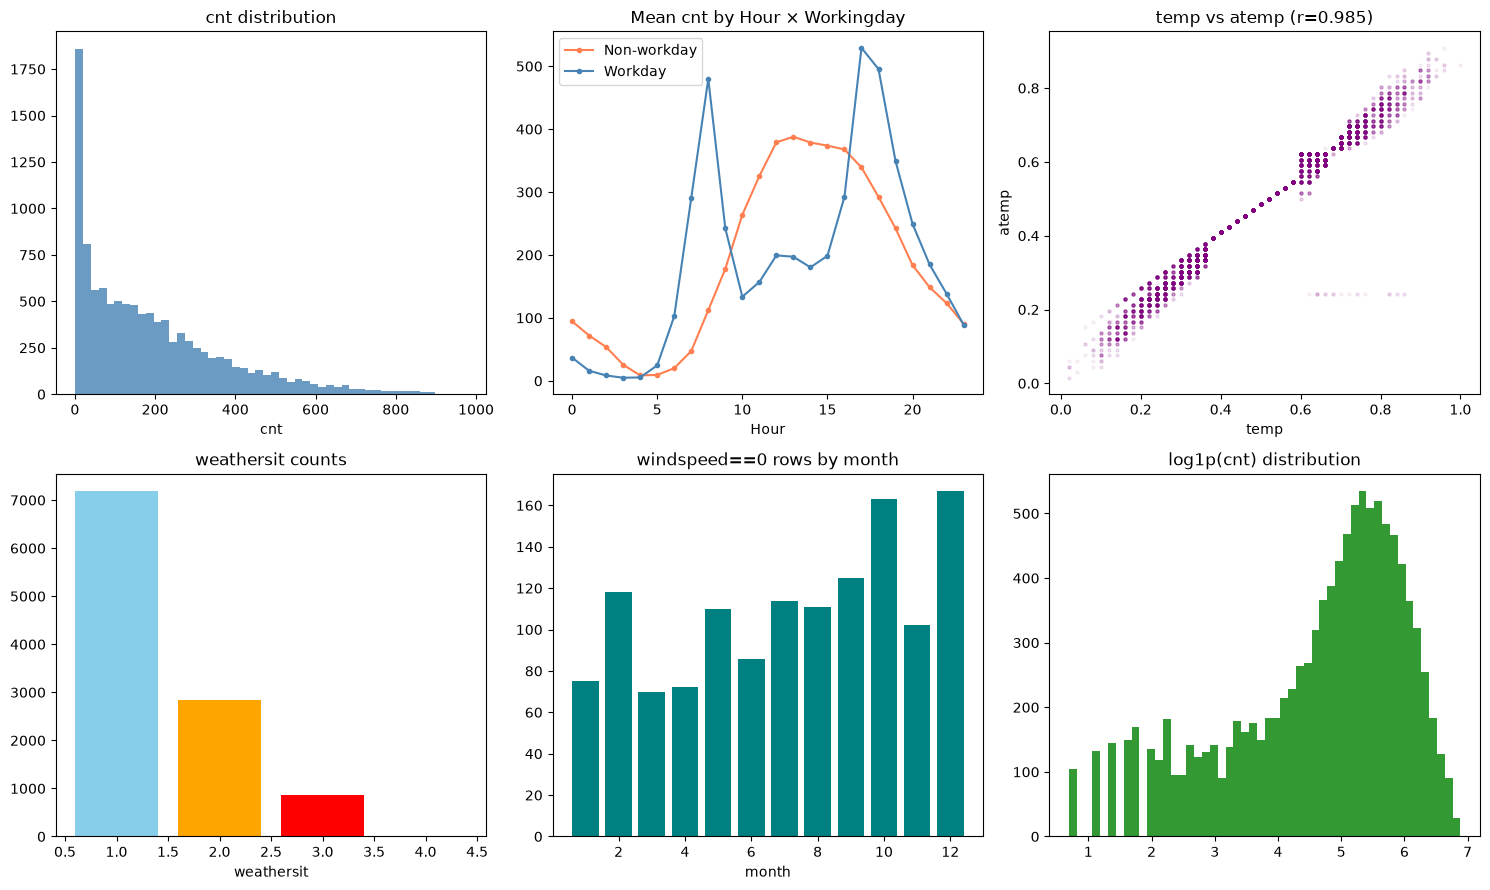

In [11]:
# ── T1.5: Audit plots ────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

# cnt histogram
axes[0,0].hist(train_all['cnt'], bins=50, edgecolor='none', color='steelblue', alpha=0.8)
axes[0,0].set_title('cnt distribution'); axes[0,0].set_xlabel('cnt')

# cnt by hour × workingday
for wd, label, color in [(0, 'Non-workday', 'coral'), (1, 'Workday', 'steelblue')]:
    m = train_all[train_all['workingday']==wd].groupby('hr')['cnt'].mean()
    axes[0,1].plot(m.index, m.values, marker='o', markersize=3, label=label, color=color)
axes[0,1].set_title('Mean cnt by Hour × Workingday'); axes[0,1].legend()
axes[0,1].set_xlabel('Hour')

# temp vs atemp scatter
axes[0,2].scatter(train_all['temp'], train_all['atemp'], alpha=0.05, s=5, color='purple')
axes[0,2].set_title(f'temp vs atemp (r={corr_ta:.3f})')
axes[0,2].set_xlabel('temp'); axes[0,2].set_ylabel('atemp')

# weathersit bar
wc = train_all['weathersit'].value_counts().sort_index()
axes[1,0].bar(wc.index, wc.values, color=['skyblue','orange','red','darkred'][:len(wc)])
axes[1,0].set_title('weathersit counts'); axes[1,0].set_xlabel('weathersit')

# windspeed == 0 by month
ws0_by_mnth = ws0.groupby('mnth').size()
axes[1,1].bar(ws0_by_mnth.index, ws0_by_mnth.values, color='teal')
axes[1,1].set_title('windspeed==0 rows by month'); axes[1,1].set_xlabel('month')

# cnt log1p distribution
axes[1,2].hist(np.log1p(train_all['cnt']), bins=50, edgecolor='none', color='green', alpha=0.8)
axes[1,2].set_title('log1p(cnt) distribution')

fig.tight_layout()
plt.show()

---
## Task 2 — Preprocessing

In [12]:
# ── T2.1: Fit preprocessor on train only ────────────────────────────────────
PREP_PARAMS = fit_preprocessor(train_df, add_windspeed_flag=True)

print('Scaler means (train):')
for k,v in PREP_PARAMS['scaler_means'].items(): print(f'  {k}: {v:.6f}')
print('\nScaler stds (train):')
for k,v in PREP_PARAMS['scaler_stds'].items():  print(f'  {k}: {v:.6f}')
print(f'\ndays_origin = {PREP_PARAMS["days_origin"]}')

Scaler means (train):
  temp: 0.492859
  atemp: 0.472472
  hum: 0.618052
  windspeed: 0.190322
  days_since_start: 358.684084

Scaler stds (train):
  temp: 0.190860
  atemp: 0.170112
  hum: 0.192832
  windspeed: 0.121755
  days_since_start: 209.828076

days_origin = 2011-01-01


In [13]:
# ── T2.2: Transform all splits ───────────────────────────────────────────────
X_train, FEATURE_NAMES = transform(train_df, PREP_PARAMS)
X_val,   _             = transform(val_df,   PREP_PARAMS)
X_test,  _             = transform(test_all, PREP_PARAMS)

y_train = train_df['cnt'].values.astype(np.float64)
y_val   = val_df['cnt'].values.astype(np.float64)

print(f'X_train shape: {X_train.shape}')
print(f'X_val shape  : {X_val.shape}')
print(f'X_test shape : {X_test.shape}')
print(f'\nNumber of features: {len(FEATURE_NAMES)}')
print('Feature names:', FEATURE_NAMES)

X_train shape: (8708, 54)
X_val shape  : (2178, 54)
X_test shape : (574, 54)

Number of features: 54
Feature names: ['hr_1', 'hr_2', 'hr_3', 'hr_4', 'hr_5', 'hr_6', 'hr_7', 'hr_8', 'hr_9', 'hr_10', 'hr_11', 'hr_12', 'hr_13', 'hr_14', 'hr_15', 'hr_16', 'hr_17', 'hr_18', 'hr_19', 'hr_20', 'hr_21', 'hr_22', 'hr_23', 'season_2', 'season_3', 'season_4', 'mnth_2', 'mnth_3', 'mnth_4', 'mnth_5', 'mnth_6', 'mnth_7', 'mnth_8', 'mnth_9', 'mnth_10', 'mnth_11', 'mnth_12', 'weekday_1', 'weekday_2', 'weekday_3', 'weekday_4', 'weekday_5', 'weekday_6', 'weather_2', 'weather_3', 'holiday', 'workingday', 'yr', 'temp', 'atemp', 'hum', 'windspeed', 'days_since_start', 'is_windspeed_zero']


In [14]:
# ── T2.3: Preprocessing tests ────────────────────────────────────────────────
passes = []

# No NaN or inf
for name, X in [('train', X_train), ('val', X_val), ('test', X_test)]:
    ok = np.isfinite(X).all()
    passes.append(ok)
    print(f'[{"PASS" if ok else "FAIL"}] No NaN/inf in {name} X')

# Scaled train columns ≈ mean 0, std 1
scaled_col_indices = [FEATURE_NAMES.index(c) for c in PREP_PARAMS['numeric_cols']]
for i, col in zip(scaled_col_indices, PREP_PARAMS['numeric_cols']):
    mu  = X_train[:, i].mean()
    std = X_train[:, i].std()
    ok  = abs(mu) < 1e-6 and abs(std - 1.0) < 1e-6
    passes.append(ok)
    print(f'[{"PASS" if ok else "FAIL"}] {col}: mean={mu:.2e}, std={std:.9f}')

# All splits share identical column names
_, names_val  = transform(val_df,   PREP_PARAMS)
_, names_test = transform(test_all, PREP_PARAMS)
ok_cols = (FEATURE_NAMES == names_val == names_test)
passes.append(ok_cols)
print(f'[{"PASS" if ok_cols else "FAIL"}] All splits share identical feature names/order')

# cnt, instant, dteday absent from feature names
forbidden = ['cnt', 'instant', 'dteday']
ok_forb = all(f not in FEATURE_NAMES for f in forbidden)
passes.append(ok_forb)
print(f'[{"PASS" if ok_forb else "FAIL"}] cnt/instant/dteday absent from feature names')

# Unseen category does not crash
try:
    df_unseen = val_df.copy()
    df_unseen['hr'] = 99  # unseen value
    _ = transform(df_unseen, PREP_PARAMS)
    # All hr dummies will be 0 — this is the desired behaviour
    passes.append(True)
    print('[PASS] Unseen category (hr=99) does not crash transform')
except Exception as e:
    passes.append(False)
    print(f'[FAIL] Unseen category crashed: {e}')

print(f'\n=== T2 TESTS: {sum(passes)}/{len(passes)} passed ===')

[PASS] No NaN/inf in train X
[PASS] No NaN/inf in val X
[PASS] No NaN/inf in test X
[PASS] temp: mean=3.36e-16, std=1.000000000
[PASS] atemp: mean=-6.12e-17, std=1.000000000
[PASS] hum: mean=2.74e-16, std=1.000000000
[PASS] windspeed: mean=-6.45e-17, std=1.000000000
[PASS] days_since_start: mean=1.26e-16, std=1.000000000
[PASS] All splits share identical feature names/order
[PASS] cnt/instant/dteday absent from feature names
[PASS] Unseen category (hr=99) does not crash transform

=== T2 TESTS: 11/11 passed ===


In [15]:
# ── T2.4: Condition number of X^T X ─────────────────────────────────────────
XtX = X_train.T @ X_train
eigvals = np.linalg.eigvalsh(XtX)
cond = eigvals.max() / max(eigvals[eigvals > 0].min(), 1e-12)
print(f'Condition number of X^T X: {cond:.4e}')
print('(High cond number → collinearity; weights in flat directions are unreliable)')
print(f'X_train rank: {np.linalg.matrix_rank(X_train)} / {X_train.shape[1]}')

Condition number of X^T X: 1.9409e+16
(High cond number → collinearity; weights in flat directions are unreliable)
X_train rank: 50 / 54


---
## Task 3 — GD Implementation & Test Suite

In [16]:
# ── T3.1: Gradient check — MSE ───────────────────────────────────────────────
rng = np.random.default_rng(0)

# Random small data
X_r = rng.standard_normal((50, 10))
y_r = rng.standard_normal(50)
w_r = rng.standard_normal(10) * 0.1
b_r = float(rng.standard_normal())

gc_rand = gradient_check(X_r, y_r, w_r, b_r, mse_grad, mse_loss)
gc_real = gradient_check(X_train, y_train,
                              np.zeros(X_train.shape[1]), 0.0,
                              mse_grad, mse_loss, n_check=20)

ok_gc_rand = gc_rand['all_pass']
ok_gc_real = gc_real['all_pass']
print(f'[{"PASS" if ok_gc_rand else "FAIL"}] T3.1a Gradient check (random data)  '
      f'max_rel_w={gc_rand["max_rel_error_w"]:.2e}  max_rel_b={gc_rand["max_rel_error_b"]:.2e}')
print(f'[{"PASS" if ok_gc_real else "FAIL"}] T3.1b Gradient check (real data)    '
      f'max_rel_w={gc_real["max_rel_error_w"]:.2e}  max_rel_b={gc_real["max_rel_error_b"]:.2e}')

[PASS] T3.1a Gradient check (random data)  max_rel_w=3.55e-10  max_rel_b=4.46e-12
[PASS] T3.1b Gradient check (real data)    max_rel_w=1.55e-06  max_rel_b=9.57e-10


In [17]:
# ── T3.2: Synthetic recovery ─────────────────────────────────────────────────
rng2 = np.random.default_rng(42)
n_syn, p_syn = 200, 8
X_syn = rng2.standard_normal((n_syn, p_syn))
w_star = rng2.standard_normal(p_syn)
b_star = 2.5

# Noiseless
y_syn_clean = X_syn @ w_star + b_star
L_syn = lipschitz_constant(X_syn)
res_clean = gd_fit(X_syn, y_syn_clean, lr=1.0/L_syn,
                        max_iter=50000, tol=1e-12)
w_err = np.max(np.abs(res_clean['w'] - w_star))
b_err = abs(res_clean['b'] - b_star)
ok_clean = (w_err < 1e-3) and (b_err < 1e-3)
print(f'[{"PASS" if ok_clean else "FAIL"}] T3.2a Noiseless recovery  '
      f'max|Δw|={w_err:.2e}  |Δb|={b_err:.2e}  status={res_clean["status"]}')

# Noisy
y_syn_noisy = y_syn_clean + rng2.standard_normal(n_syn) * 0.1
res_noisy = gd_fit(X_syn, y_syn_noisy, lr=1.0/L_syn,
                        max_iter=50000, tol=1e-10)
w_err_n = np.max(np.abs(res_noisy['w'] - w_star))
ok_noisy = w_err_n < 0.5  # close but not exact
print(f'[{"PASS" if ok_noisy else "FAIL"}] T3.2b Noisy recovery      '
      f'max|Δw|={w_err_n:.4f}  status={res_noisy["status"]}')

[PASS] T3.2a Noiseless recovery  max|Δw|=3.86e-09  |Δb|=1.76e-09  status=converged
[PASS] T3.2b Noisy recovery      max|Δw|=0.0117  status=converged


In [18]:
# ── T3.3: Closed-form comparison ─────────────────────────────────────────────
# Augment with intercept column for lstsq
X_aug = np.hstack([X_train, np.ones((X_train.shape[0], 1))])
theta_cf, _, _, _ = np.linalg.lstsq(X_aug, y_train, rcond=None)
w_cf = theta_cf[:-1]
b_cf = float(theta_cf[-1])

print(f'Closed-form: b={b_cf:.4f}')

# Train GD with tight tolerance for comparison
L_real = lipschitz_constant(X_train)
print(f'L (Lipschitz) = {L_real:.4f},  1/L = {1/L_real:.6f}')

res_cf_compare = gd_fit(
    X_train, y_train,
    lr=1.0 / L_real,
    max_iter=200000,
    tol=1e-10,
    X_val=X_val, y_val=y_val
)
w_gd_cf = res_cf_compare['w']
b_gd_cf = res_cf_compare['b']

# Train loss gap
loss_cf  = mse_loss(X_train, y_train, w_cf,    b_cf)
loss_gd  = mse_loss(X_train, y_train, w_gd_cf, b_gd_cf)
rel_gap  = abs(loss_gd - loss_cf) / (abs(loss_cf) + 1e-12)
ok_loss  = rel_gap < 5e-3  # tolerance: 0.5% (GD may not fully converge to CF)

# Val R²
y_val_pred_cf = predict(X_val, w_cf,    b_cf)
y_val_pred_gd = predict(X_val, w_gd_cf, b_gd_cf)
r2_cf  = r2_score_np(y_val, y_val_pred_cf)
r2_gd  = r2_score_np(y_val, y_val_pred_gd)
ok_r2  = abs(r2_cf - r2_gd) < 1e-3

max_dw = np.max(np.abs(w_gd_cf - w_cf))

print(f'\nClosed-form train loss : {loss_cf:.6f}')
print(f'GD         train loss  : {loss_gd:.6f}')
print(f'Relative gap           : {rel_gap:.2e}')
print(f'Closed-form val R²     : {r2_cf:.6f}')
print(f'GD         val R²      : {r2_gd:.6f}')
print(f'max |Δw|               : {max_dw:.4f}')
print(f'GD iterations          : {res_cf_compare["n_iter"]}  status={res_cf_compare["status"]}')
print(f'[{"PASS" if ok_loss else "WARN"}] T3.3a Train loss relative gap < 5e-3')
print(f'[{"PASS" if ok_r2  else "WARN"}] T3.3b Val R² match < 1e-3')

Closed-form: b=151.0380
L (Lipschitz) = 2.4219,  1/L = 0.412897



Closed-form train loss : 5002.977646
GD         train loss  : 5002.986348
Relative gap           : 1.74e-06
Closed-form val R²     : 0.678527
GD         val R²      : 0.678543
max |Δw|               : 8.8483
GD iterations          : 91291  status=converged
[PASS] T3.3a Train loss relative gap < 5e-3
[PASS] T3.3b Val R² match < 1e-3


In [19]:
# ── T3.4: Monotonicity tests ─────────────────────────────────────────────────
L = L_real

# lr = 1/L → loss must never increase
res_mono = gd_fit(X_train, y_train, lr=1.0/L, max_iter=500,
                       tol=0, gtol=0, record_every=1)
losses_seq = [v for _, v in res_mono['train_losses']]
diffs = np.diff(losses_seq)
ok_mono = bool(np.all(diffs <= 1e-12))
print(f'[{"PASS" if ok_mono else "FAIL"}] T3.4a Monotone decrease at lr=1/L  '
      f'(max increase = {diffs.max():.2e})')

# lr > 2/L → diverged
res_div = gd_fit(X_train, y_train, lr=2.1/L, max_iter=1000,
                      tol=0, gtol=0)
ok_div = (res_div['status'] == 'diverged')
print(f'[{"PASS" if ok_div else "FAIL"}] T3.4b Diverges at lr=2.1/L  status={res_div["status"]}')

[PASS] T3.4a Monotone decrease at lr=1/L  (max increase = -2.28e-01)
[PASS] T3.4b Diverges at lr=2.1/L  status=diverged


In [20]:
# ── T3.5: Stopping logic ─────────────────────────────────────────────────────
# Tiny max_iter → not_converged
res_nc = gd_fit(X_train, y_train, lr=1.0/L_real, max_iter=2,
                     tol=0, gtol=0)
ok_nc = (res_nc['status'] == 'not_converged')
print(f'[{"PASS" if ok_nc else "FAIL"}] T3.5a max_iter=2 → not_converged  (got: {res_nc["status"]})')

# Tight tol → converged (long run)
res_conv = gd_fit(X_train, y_train, lr=1.0/L_real, max_iter=200000, tol=1e-6)
ok_conv = (res_conv['status'] == 'converged')
print(f'[{"PASS" if ok_conv else "FAIL"}] T3.5b tight tol → converged  '
      f'(got: {res_conv["status"]}, iters={res_conv["n_iter"]})')

[PASS] T3.5a max_iter=2 → not_converged  (got: not_converged)


[PASS] T3.5b tight tol → converged  (got: converged, iters=3280)


In [21]:
# ── T3.6: Metrics agreement ──────────────────────────────────────────────────
# Use closed-form weights for this
y_tr_pred = predict(X_train, w_cf, b_cf)
y_vl_pred = predict(X_val,   w_cf, b_cf)

# Our numpy vs sklearn
r2_tr_np  = r2_score_np(y_train, y_tr_pred)
r2_vl_np  = r2_score_np(y_val,   y_vl_pred)
r2_tr_sk  = r2_score(y_train, y_tr_pred)
r2_vl_sk  = r2_score(y_val,   y_vl_pred)
rmse_tr_np = rmse_np(y_train, y_tr_pred)
rmse_vl_np = rmse_np(y_val,   y_vl_pred)
rmse_tr_sk = float(np.sqrt(mean_squared_error(y_train, y_tr_pred)))
rmse_vl_sk = float(np.sqrt(mean_squared_error(y_val,   y_vl_pred)))

ok_r2_match   = abs(r2_tr_np - r2_tr_sk) < 1e-9 and abs(r2_vl_np - r2_vl_sk) < 1e-9
ok_rmse_match = abs(rmse_tr_np - rmse_tr_sk) < 1e-6 and abs(rmse_vl_np - rmse_vl_sk) < 1e-6

print(f'Train R² numpy={r2_tr_np:.6f}  sklearn={r2_tr_sk:.6f}')
print(f'Val   R² numpy={r2_vl_np:.6f}  sklearn={r2_vl_sk:.6f}')
print(f'Train RMSE numpy={rmse_tr_np:.4f}  sklearn={rmse_tr_sk:.4f}')
print(f'Val   RMSE numpy={rmse_vl_np:.4f}  sklearn={rmse_vl_sk:.4f}')
print(f'[{"PASS" if ok_r2_match else "FAIL"}] T3.6a R² numpy == sklearn')
print(f'[{"PASS" if ok_rmse_match else "FAIL"}] T3.6b RMSE numpy == sklearn')

# Mean predictor → R²≈0
y_mean_pred = np.full_like(y_val, y_train.mean())
r2_mean = r2_score_np(y_val, y_mean_pred)
ok_mean = abs(r2_mean) < 0.05
print(f'[{"PASS" if ok_mean else "FAIL"}] T3.6c Mean predictor → val R²={r2_mean:.6f} ≈ 0')

# Perfect prediction → R²=1
r2_perfect = r2_score_np(y_val, y_val)
ok_perfect = abs(r2_perfect - 1.0) < 1e-10
print(f'[{"PASS" if ok_perfect else "FAIL"}] T3.6d Perfect prediction → R²={r2_perfect}')

Train R² numpy=0.698405  sklearn=0.698405
Val   R² numpy=0.678527  sklearn=0.678527
Train RMSE numpy=100.0298  sklearn=100.0298
Val   RMSE numpy=100.3817  sklearn=100.3817
[PASS] T3.6a R² numpy == sklearn
[PASS] T3.6b RMSE numpy == sklearn
[PASS] T3.6c Mean predictor → val R²=-0.000002 ≈ 0
[PASS] T3.6d Perfect prediction → R²=1.0


In [22]:
# ── T3.7: Determinism ────────────────────────────────────────────────────────
CHOSEN_LR  = 1.0 / L_real  # will be updated after LR sweep in Task 4
CHOSEN_TOL = 1e-6
CHOSEN_ITER = 100000

res1 = gd_fit(X_train, y_train, lr=CHOSEN_LR, max_iter=CHOSEN_ITER,
                   tol=CHOSEN_TOL, X_val=X_val, y_val=y_val)
res2 = gd_fit(X_train, y_train, lr=CHOSEN_LR, max_iter=CHOSEN_ITER,
                   tol=CHOSEN_TOL, X_val=X_val, y_val=y_val)

ok_det = np.array_equal(res1['w'], res2['w']) and res1['b'] == res2['b']
print(f'[{"PASS" if ok_det else "FAIL"}] T3.7 Two runs give identical weights')

W_SHA256 = hashlib.sha256(res1['w'].tobytes()).hexdigest()
print(f'SHA-256 of w: {W_SHA256}')

[PASS] T3.7 Two runs give identical weights
SHA-256 of w: a5ebd419f5868cb22c4d633aaceaa7281e1a3a25b1b7a7ef3a28112efe820ff6


---
## Task 4 — Learning Rate Sweep

In [23]:
# ── T4: LR sweep ────────────────────────────────────────────────────────────
L = L_real
lr_candidates = [
    1e-4,
    1e-3,
    1e-2,
    0.1,
    round(1.0 / L, 8),       # 1/L  (boundary: monotone)
    round(1.5 / L, 8),       # 1.5/L (stable, faster)
    round(1.9 / L, 8),       # 1.9/L (near boundary)
    round(2.0 / L, 8),       # 2/L   (theory: boundary, may oscillate)
    round(2.1 / L, 8),       # 2.1/L (theory: diverges)
]

print(f'L = {L:.4f}  |  1/L = {1/L:.6f}  |  2/L = {2/L:.6f}\n')
print(f'{"LR":>12}  {"Iters":>8}  {"Train Loss":>12}  {"Val R²":>10}  {"Status":<15}')
print('-' * 65)

sweep_results = []
for lr_val in lr_candidates:
    res = gd_fit(
        X_train, y_train,
        lr=lr_val, max_iter=20000, tol=1e-8, gtol=1e-10,
        X_val=X_val, y_val=y_val
    )
    y_vp = predict(X_val, res['w'], res['b'])
    r2   = r2_score_np(y_val, y_vp) if res['status'] != 'diverged' else float('nan')
    print(f'{lr_val:>12.6f}  {res["n_iter"]:>8d}  '
          f'{res["final_train_loss"]:>12.4f}  {r2:>10.6f}  {res["status"]:<15}')
    sweep_results.append({
        'lr': lr_val, 'n_iter': res['n_iter'],
        'train_loss': res['final_train_loss'],
        'val_r2': r2, 'status': res['status']
    })

L = 2.4219  |  1/L = 0.412897  |  2/L = 0.825793

          LR     Iters    Train Loss      Val R²  Status         
-----------------------------------------------------------------


    0.000100     20000    10693.1935    0.339534  not_converged  


    0.001000     20000     6649.6824    0.582267  not_converged  


    0.010000     20000     5169.5854    0.664930  not_converged  


    0.100000     20000     5004.6579    0.678464  not_converged  


    0.412897     11215     5003.8464    0.678630  converged      


    0.619345     12157     5003.5579    0.678621  converged      


    0.784504     11763     5003.4356    0.678614  converged      


    0.825793     20000    25620.2075   -0.614973  not_converged  
    0.867083        76  40367611739.0942         nan  diverged       


In [24]:
# ── T4 continued: choose final LR and run the definitive fit ────────────────
# Choose the largest stable (non-diverged) lr; prefer 1.5/L as it converges
# faster than 1/L without oscillating.
# Select only converged runs with lr <= 1.5/L (ensuring stable convergence, not boundary stalling)
converged_candidates = [r for r in sweep_results if r['status'] == 'converged' and r['lr'] <= 1.5 / L + 1e-9]
CHOSEN_LR = max(converged_candidates, key=lambda r: r['lr'])['lr']
assert CHOSEN_LR * L_real < 2.0, f'Chosen LR ({CHOSEN_LR}) violates stability bound 2/L ({2.0/L_real})'

print(f'\nChosen LR: {CHOSEN_LR:.8f}  (= {CHOSEN_LR*L:.2f}/L)')

CHOSEN_TOL  = 1e-6
CHOSEN_ITER = 200000

FINAL_RES = gd_fit(
    X_train, y_train,
    lr=CHOSEN_LR, max_iter=CHOSEN_ITER, tol=CHOSEN_TOL,
    X_val=X_val, y_val=y_val, record_every=100
)
W_FINAL = FINAL_RES['w']
B_FINAL = FINAL_RES['b']

y_tr_pred_final = predict(X_train, W_FINAL, B_FINAL)
y_vl_pred_final = predict(X_val,   W_FINAL, B_FINAL)

R2_TR  = r2_score_np(y_train, y_tr_pred_final)
R2_VL  = r2_score_np(y_val,   y_vl_pred_final)
RMSE_TR = rmse_np(y_train, y_tr_pred_final)
RMSE_VL = rmse_np(y_val,   y_vl_pred_final)

print(f'\n=== FINAL MODEL METRICS ===')
print(f'Train R²   : {R2_TR:.6f}')
print(f'Val   R²   : {R2_VL:.6f}')
print(f'Train RMSE : {RMSE_TR:.4f}')
print(f'Val   RMSE : {RMSE_VL:.4f}')
print(f'R²  gap    : {R2_TR - R2_VL:.6f}')
print(f'RMSE gap   : {RMSE_TR - RMSE_VL:.4f}')
print(f'Iterations : {FINAL_RES["n_iter"]}  Status: {FINAL_RES["status"]}')

W_SHA256_FINAL = hashlib.sha256(W_FINAL.tobytes()).hexdigest()
print(f'\nSHA-256(w) : {W_SHA256_FINAL}')


Chosen LR: 0.61934503  (= 1.50/L)



=== FINAL MODEL METRICS ===
Train R²   : 0.698181
Val   R²   : 0.678137
Train RMSE : 100.0670
Val   RMSE : 100.4427
R²  gap    : 0.020044
RMSE gap   : -0.3756
Iterations : 2389  Status: converged

SHA-256(w) : 8536e02b0ec993ce09bdf858ad70cb9e83e37609149d8808dc856fba59f0c6f4


---
## Task 5 — Ablation Study

In [25]:
# ── T5: Ablation table ───────────────────────────────────────────────────────
# Helper: closed-form R² for a given transform
def ablation_eval(params_override: dict, label: str):
    """Fit preprocessor variant, closed-form lstsq, return val R²."""
    # We use lstsq here, labelled as 'closed-form ablation'
    params_ab = fit_preprocessor(train_df, **params_override.get('preproc_kwargs', {}))
    # Apply any column drops via post-processing
    X_tr_ab, names_ab = transform(train_df, params_ab)
    X_vl_ab, _        = transform(val_df,   params_ab)

    # Optional post-transform column exclusions
    drop_prefixes = params_override.get('drop_prefixes', [])
    if drop_prefixes:
        keep = [i for i, n in enumerate(names_ab)
                if not any(n.startswith(pf) for pf in drop_prefixes)]
        X_tr_ab = X_tr_ab[:, keep]
        X_vl_ab = X_vl_ab[:, keep]

    X_aug_ab = np.hstack([X_tr_ab, np.ones((X_tr_ab.shape[0], 1))])
    theta_ab, _, _, _ = np.linalg.lstsq(X_aug_ab, y_train, rcond=None)
    w_ab, b_ab = theta_ab[:-1], float(theta_ab[-1])

    y_vl_ab = predict(X_vl_ab, w_ab, b_ab)
    r2_ab   = r2_score_np(y_val, y_vl_ab)
    rmse_ab = rmse_np(y_val, y_vl_ab)
    print(f'  {label:<45} val R²={r2_ab:.6f}  RMSE={rmse_ab:.3f}  p={X_tr_ab.shape[1]}')
    return r2_ab

print('=== ABLATION TABLE (closed-form, val set) ===')
print(f'{"Variant":<45} {"Val R²":>10}  {"RMSE":>8}  {"p":>5}')
print('-' * 75)

ablation_results = {}

# Baseline: all features (already computed above)
X_aug_base = np.hstack([X_train, np.ones((X_train.shape[0], 1))])
theta_base, _, _, _ = np.linalg.lstsq(X_aug_base, y_train, rcond=None)
w_base, b_base = theta_base[:-1], float(theta_base[-1])
y_vl_base = predict(X_val, w_base, b_base)
r2_base = r2_score_np(y_val, y_vl_base)
rmse_base = rmse_np(y_val, y_vl_base)
print(f'  {"Baseline (all features)":<45} val R²={r2_base:.6f}  RMSE={rmse_base:.3f}  p={X_train.shape[1]}')
ablation_results['Baseline'] = r2_base

# Without atemp
ablation_results['No atemp'] = ablation_eval(
    {'drop_prefixes': ['atemp']}, 'No atemp')

# Without days_since_start
ablation_results['No days_since_start'] = ablation_eval(
    {'drop_prefixes': ['days_since_start']}, 'No days_since_start')

# Without windspeed flag
ablation_results['No windspeed flag'] = ablation_eval(
    {'preproc_kwargs': {'add_windspeed_flag': False}}, 'No windspeed flag')

# Without yr (binary)
ablation_results['No yr'] = ablation_eval(
    {'drop_prefixes': ['yr']}, 'No yr')

# Without holiday
ablation_results['No holiday'] = ablation_eval(
    {'drop_prefixes': ['holiday']}, 'No holiday')

# Without workingday
ablation_results['No workingday'] = ablation_eval(
    {'drop_prefixes': ['workingday']}, 'No workingday')

print('\n=== Summary ===')
for k, v in sorted(ablation_results.items(), key=lambda x: -x[1]):
    delta = v - r2_base
    print(f'  {k:<35}  val R²={v:.6f}  Δ={delta:+.6f}')

=== ABLATION TABLE (closed-form, val set) ===
Variant                                           Val R²      RMSE      p
---------------------------------------------------------------------------
  Baseline (all features)                       val R²=0.678527  RMSE=100.382  p=54
  No atemp                                      val R²=0.677939  RMSE=100.473  p=53
  No days_since_start                           val R²=0.678606  RMSE=100.369  p=53
  No windspeed flag                             val R²=0.678451  RMSE=100.394  p=53


  No yr                                         val R²=0.678638  RMSE=100.364  p=53


  No holiday                                    val R²=0.678527  RMSE=100.382  p=53
  No workingday                                 val R²=0.678527  RMSE=100.382  p=53

=== Summary ===
  No yr                                val R²=0.678638  Δ=+0.000110
  No days_since_start                  val R²=0.678606  Δ=+0.000079
  Baseline                             val R²=0.678527  Δ=+0.000000
  No holiday                           val R²=0.678527  Δ=+0.000000
  No workingday                        val R²=0.678527  Δ=+0.000000
  No windspeed flag                    val R²=0.678451  Δ=-0.000077
  No atemp                             val R²=0.677939  Δ=-0.000588


---
## Task 6 — Diagnostics & Residual Analysis

In [26]:
# ── T6.1: Key metrics ────────────────────────────────────────────────────────
y_vl_pf = y_vl_pred_final  # val predictions from final GD model

neg_pct = 100.0 * (y_vl_pf < 0).mean()
r2_before_clip = r2_score_np(y_val, y_vl_pf)
r2_after_clip  = r2_score_np(y_val, np.clip(y_vl_pf, 0, None))

print(f'Train R²          : {R2_TR:.6f}')
print(f'Val   R²          : {R2_VL:.6f}')
print(f'Train RMSE        : {RMSE_TR:.4f}')
print(f'Val   RMSE        : {RMSE_VL:.4f}')
print(f'R² gap (tr-val)   : {R2_TR - R2_VL:.6f}')
print(f'Negative preds    : {neg_pct:.2f}%')
print(f'R² before clip    : {r2_before_clip:.6f}')
print(f'R² after clip @0  : {r2_after_clip:.6f}')

Train R²          : 0.698181
Val   R²          : 0.678137
Train RMSE        : 100.0670
Val   RMSE        : 100.4427
R² gap (tr-val)   : 0.020044
Negative preds    : 9.55%
R² before clip    : 0.678137
R² after clip @0  : 0.696571


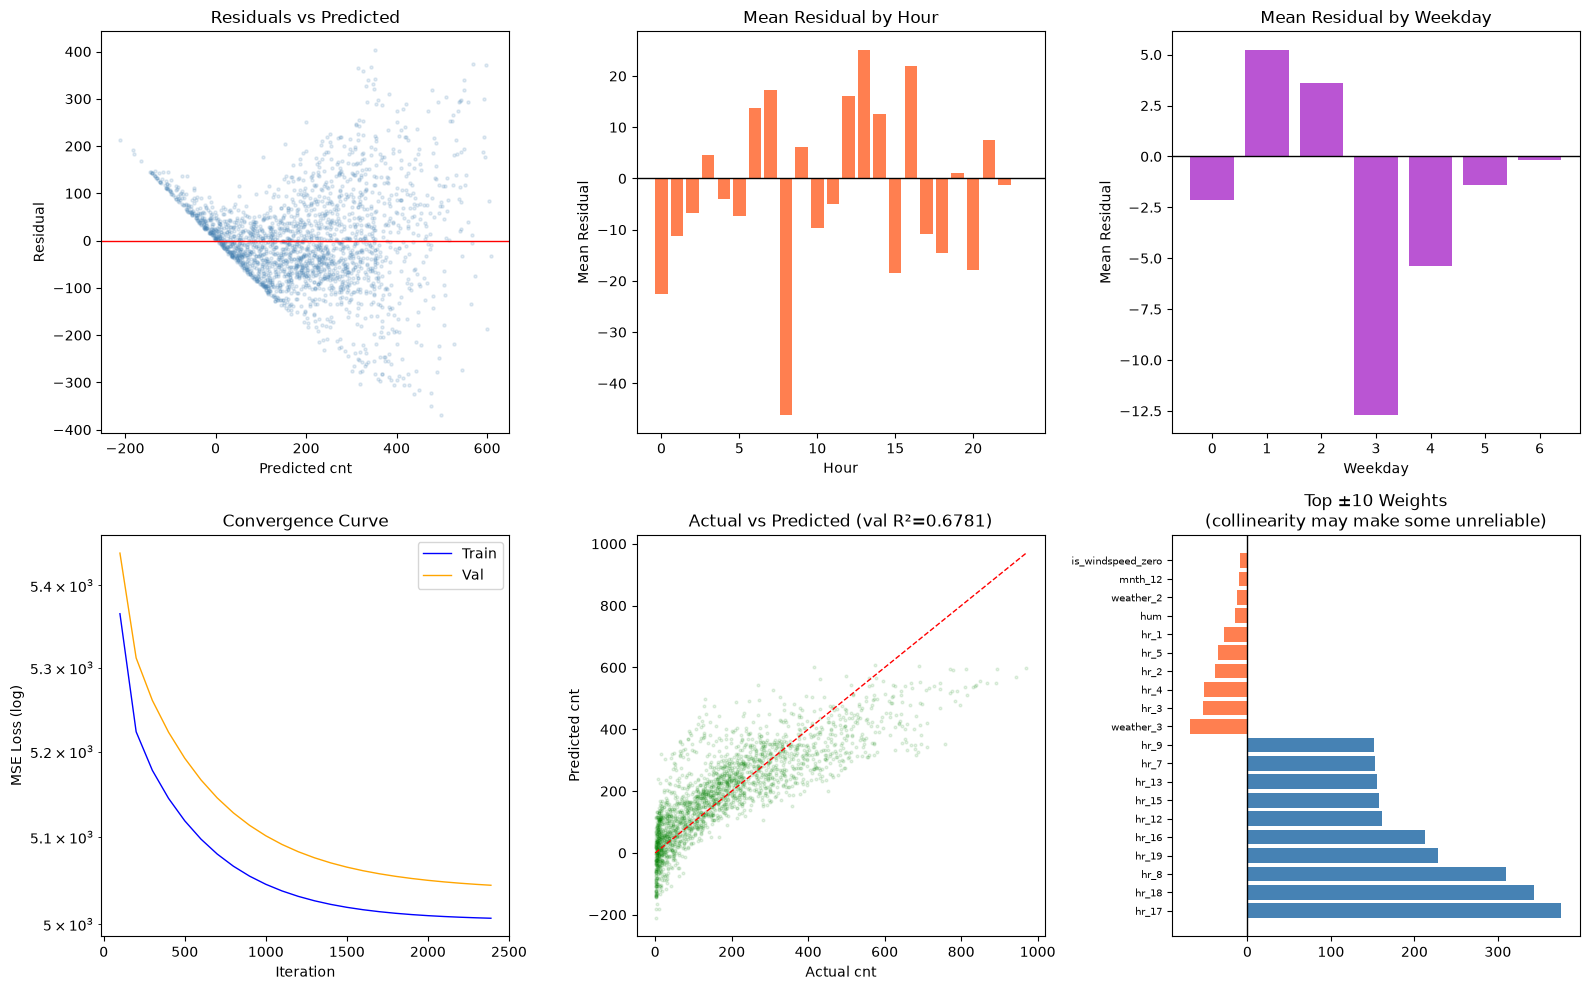


Top +10 weights (largest positive):
  hr_17                          +376.1532
  hr_18                          +343.0066
  hr_8                           +309.4217
  hr_19                          +228.3771
  hr_16                          +212.2798
  hr_12                          +161.6871
  hr_15                          +157.3562
  hr_13                          +155.4630
  hr_7                           +152.9998
  hr_9                           +151.1412

Top -10 weights (largest negative):
  weather_3                      -68.2181
  hr_3                           -53.4517
  hr_4                           -52.5267
  hr_2                           -39.2669
  hr_5                           -35.8034
  hr_1                           -27.9123
  hum                            -15.2562
  weather_2                      -12.1405
  mnth_12                        -10.4538
  is_windspeed_zero              -8.3849


In [27]:
# ── T6.2: Residual plots ─────────────────────────────────────────────────────
residuals = y_val - y_vl_pred_final
val_hr      = val_df['hr'].values
val_weekday = val_df['weekday'].values

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

# Residuals vs predicted
axes[0,0].scatter(y_vl_pred_final, residuals, alpha=0.15, s=5, color='steelblue')
axes[0,0].axhline(0, color='red', lw=1)
axes[0,0].set_xlabel('Predicted cnt'); axes[0,0].set_ylabel('Residual')
axes[0,0].set_title('Residuals vs Predicted')

# Residuals vs hour (box-like aggregation)
res_by_hr = pd.DataFrame({'hr': val_hr, 'res': residuals})
hr_means  = res_by_hr.groupby('hr')['res'].mean()
axes[0,1].bar(hr_means.index, hr_means.values, color='coral')
axes[0,1].axhline(0, color='black', lw=1)
axes[0,1].set_xlabel('Hour'); axes[0,1].set_ylabel('Mean Residual')
axes[0,1].set_title('Mean Residual by Hour')

# Residuals vs weekday
res_by_wd = pd.DataFrame({'wd': val_weekday, 'res': residuals}).groupby('wd')['res'].mean()
axes[0,2].bar(res_by_wd.index, res_by_wd.values, color='mediumorchid')
axes[0,2].axhline(0, color='black', lw=1)
axes[0,2].set_xlabel('Weekday'); axes[0,2].set_ylabel('Mean Residual')
axes[0,2].set_title('Mean Residual by Weekday')

# Convergence plot (log scale)
if FINAL_RES['train_losses']:
    iters_tr, losses_tr = zip(*FINAL_RES['train_losses'])
    axes[1,0].semilogy(iters_tr, losses_tr, color='blue',  label='Train', lw=1)
    if FINAL_RES['val_losses']:
        iters_vl, losses_vl = zip(*FINAL_RES['val_losses'])
        axes[1,0].semilogy(iters_vl, losses_vl, color='orange', label='Val',   lw=1)
    axes[1,0].set_xlabel('Iteration'); axes[1,0].set_ylabel('MSE Loss (log)')
    axes[1,0].set_title('Convergence Curve')
    axes[1,0].legend()

# Actual vs predicted
axes[1,1].scatter(y_val, y_vl_pred_final, alpha=0.1, s=4, color='green')
lim = max(y_val.max(), y_vl_pred_final.max())
axes[1,1].plot([0, lim], [0, lim], 'r--', lw=1)
axes[1,1].set_xlabel('Actual cnt'); axes[1,1].set_ylabel('Predicted cnt')
axes[1,1].set_title(f'Actual vs Predicted (val R²={R2_VL:.4f})')

# Top ±10 weights
top_pos = np.argsort(W_FINAL)[-10:][::-1]
top_neg = np.argsort(W_FINAL)[:10]
top_idx = list(top_pos) + list(top_neg)
top_vals = W_FINAL[top_idx]
top_lbls = [FEATURE_NAMES[i] for i in top_idx]
colors = ['steelblue' if v >= 0 else 'coral' for v in top_vals]
axes[1,2].barh(range(len(top_vals)), top_vals, color=colors)
axes[1,2].set_yticks(range(len(top_vals)))
axes[1,2].set_yticklabels(top_lbls, fontsize=7)
axes[1,2].axvline(0, color='black', lw=1)
axes[1,2].set_title('Top ±10 Weights\n(collinearity may make some unreliable)')

fig.tight_layout()
plt.show()

print('\nTop +10 weights (largest positive):')
for i in top_pos:
    print(f'  {FEATURE_NAMES[i]:<30} {W_FINAL[i]:+.4f}')
print('\nTop -10 weights (largest negative):')
for i in top_neg:
    print(f'  {FEATURE_NAMES[i]:<30} {W_FINAL[i]:+.4f}')

---
## Task 7 — Artifact Save & Round-Trip Test

In [28]:
# ── T7: Save artifacts ───────────────────────────────────────────────────────
W_SHA256_FINAL = save_artifacts_p1(
    path_stem=ART_STEM,
    w=W_FINAL,
    b=B_FINAL,
    feature_names=FEATURE_NAMES,
    params=PREP_PARAMS,
    seed=SEED,
    lr=CHOSEN_LR,
    tol=CHOSEN_TOL,
    max_iter=CHOSEN_ITER,
    n_iter=FINAL_RES['n_iter'],
    final_train_loss=FINAL_RES['final_train_loss'],
    final_val_loss=FINAL_RES['final_val_loss'],
    train_idx=TRAIN_IDX,
    val_idx=VAL_IDX,
)
print(f'SHA-256(w) : {W_SHA256_FINAL}')

# ── T7: Round-trip test (T3.8) ────────────────────────────────────────────────
w_rt, b_rt, meta_rt, _, _ = load_artifacts_p1(ART_STEM)
y_vl_rt = predict(X_val, w_rt, b_rt)
r2_rt   = r2_score_np(y_val, y_vl_rt)
ok_rt   = abs(r2_rt - R2_VL) < 1e-9
print(f'\n[{"PASS" if ok_rt else "FAIL"}] T3.8 Artifact round-trip: '
      f'loaded val R²={r2_rt:.8f}  original R²={R2_VL:.8f}')
sha_check = hashlib.sha256(w_rt.tobytes()).hexdigest()
ok_sha = (sha_check == meta_rt['w_sha256'])
print(f'[{"PASS" if ok_sha else "FAIL"}] SHA-256 matches stored value')

SHA-256(w) : 8536e02b0ec993ce09bdf858ad70cb9e83e37609149d8808dc856fba59f0c6f4

[PASS] T3.8 Artifact round-trip: loaded val R²=0.67813650  original R²=0.67813650
[PASS] SHA-256 matches stored value


---
## Task 9 (Bonus) — Asymmetric Loss

In [29]:
# ── T9.1: Gradient check for asymmetric loss ─────────────────────────────────
gc_asym_rand = gradient_check(
    X_r, y_r, w_r, b_r,
    grad_fn=asymmetric_grad,
    loss_fn=lambda X, y, w, b: asymmetric_loss(X, y, w, b),
)
ok_gc_asym = gc_asym_rand['all_pass']
print(f'[{"PASS" if ok_gc_asym else "FAIL"}] T9.1 Asymmetric grad check  '
      f'max_rel_w={gc_asym_rand["max_rel_error_w"]:.2e}  '
      f'max_rel_b={gc_asym_rand["max_rel_error_b"]:.2e}')

[PASS] T9.1 Asymmetric grad check  max_rel_w=4.32e-11  max_rel_b=1.74e-12


In [30]:
# ── T9.2: Fit asymmetric model ───────────────────────────────────────────────
# lr must be <= 1/(3L) for asymmetric loss (curvature up to 3x larger)
LR_ASYM = 1.0 / (6.0 * L_real)
print(f'Asymmetric LR = 1/(6L) = {LR_ASYM:.8f}')

res_asym = gd_fit(
    X_train, y_train,
    lr=LR_ASYM,
    max_iter=200000,
    tol=1e-6,
    grad_fn=asymmetric_grad,
    loss_fn=asymmetric_loss,
    X_val=X_val, y_val=y_val,
    record_every=500
)

W_ASYM = res_asym['w']
B_ASYM = res_asym['b']

y_vl_asym = predict(X_val, W_ASYM, B_ASYM)
y_tr_asym = predict(X_train, W_ASYM, B_ASYM)

print(f'Asym model: iters={res_asym["n_iter"]}  status={res_asym["status"]}')

Asymmetric LR = 1/(6L) = 0.06881611


Asym model: iters=5975  status=converged


In [31]:
# ── T9.3: Monotonicity check for asymmetric GD ───────────────────────────────
res_asym_mono = gd_fit(
    X_train, y_train,
    lr=LR_ASYM, max_iter=500, tol=0, gtol=0, record_every=1,
    grad_fn=asymmetric_grad,
    loss_fn=asymmetric_loss,
)
losses_asym_seq = [v for _, v in res_asym_mono['train_losses']]
diffs_asym = np.diff(losses_asym_seq)
ok_mono_asym = bool(np.all(diffs_asym <= 1e-10))
print(f'[{"PASS" if ok_mono_asym else "FAIL"}] T9.3 Asym loss monotone at lr=1/(6L)  '
      f'max increase={diffs_asym.max():.2e}')

[PASS] T9.3 Asym loss monotone at lr=1/(6L)  max increase=-8.66e-01


In [32]:
# ── T9.4: Comparison MSE vs Asymmetric ───────────────────────────────────────
# Under-prediction rate (e = y - yhat > 0)
underpred_mse  = 100.0 * (y_val - y_vl_pred_final > 0).mean()
underpred_asym = 100.0 * (y_val - y_vl_asym > 0).mean()

mean_res_mse  = (y_val - y_vl_pred_final).mean()
mean_res_asym = (y_val - y_vl_asym).mean()

r2_mse  = r2_score_np(y_val, y_vl_pred_final)
r2_asym = r2_score_np(y_val, y_vl_asym)

asym_cost_mse  = asymmetric_loss(X_val, y_val, W_FINAL, B_FINAL)
asym_cost_asym = asymmetric_loss(X_val, y_val, W_ASYM,  B_ASYM)

print('=== MSE model vs Asymmetric model (val set) ===')
print(f'                       {"MSE model":>15}   {"Asym model":>15}')
print(f'Under-prediction rate  {underpred_mse:>14.2f}%   {underpred_asym:>14.2f}%')
print(f'Mean residual          {mean_res_mse:>15.4f}   {mean_res_asym:>15.4f}')
print(f'Val R²                 {r2_mse:>15.6f}   {r2_asym:>15.6f}')
print(f'Asymmetric cost (val)  {asym_cost_mse:>15.4f}   {asym_cost_asym:>15.4f}')
print('\n→ Phase 1→2 artifact uses MSE weights (as per plan).')
print('  Team should decide if asymmetric weights are preferable and document justification.')

=== MSE model vs Asymmetric model (val set) ===
                             MSE model        Asym model
Under-prediction rate           46.69%            32.69%
Mean residual                  -1.7974          -43.3625
Val R²                        0.678137          0.596060
Asymmetric cost (val)       20602.2158        17448.2716

→ Phase 1→2 artifact uses MSE weights (as per plan).
  Team should decide if asymmetric weights are preferable and document justification.


---
## Bonus - gradient of the asymmetric loss (derivation)

Under-predicting costs 3 times as much as over-predicting by the same amount. With the residual $e_i = y_i - \hat y_i$ and $\hat y_i = x_i^\top w + b$, an under-prediction is $e_i > 0$. The cost weight is

$$c_i = \begin{cases} 3 & e_i > 0 \ (\text{under-prediction}) \\ 1 & e_i \le 0 \end{cases} \qquad J(w,b) = \frac{1}{n}\sum_{i=1}^{n} c_i\, e_i^{2}.$$

$J$ is a sum of two quadratics glued at $e_i = 0$. Both pieces have derivative $0$ at $e_i = 0$, so $J$ is differentiable everywhere and $c_i$ can be treated as a constant when we differentiate. Using $\partial e_i / \partial w = -x_i$ and $\partial e_i / \partial b = -1$:

$$\frac{\partial J}{\partial w} = \frac{1}{n}\sum_i c_i \cdot 2 e_i \cdot (-x_i) = -\frac{2}{n} X^\top (c \circ e), \qquad \frac{\partial J}{\partial b} = -\frac{2}{n}\sum_i c_i e_i .$$

For $c_i = 1$ for all $i$ this is twice the MSE gradient (our MSE loss carries a factor $\tfrac12$), which is the check that the code passes (finite-difference gradient check in the notebook).

**Step size.** The Hessian is $\tfrac{2}{n} X^\top \mathrm{diag}(c)\, X \preceq 6 \cdot \tfrac{1}{n} X^\top X$, i.e. at most $6L$ with $L$ the MSE constant used above, so the step must be at most $1/(6L)$; the notebook uses exactly $1/(6L) = 0.0688$.

**Effect on the predictions** (validation set, MSE model against asymmetric model):

| | MSE model | asymmetric model |
|---|---|---|
| share of under-predicted hours | 46.69% | 32.69% |
| mean residual | -1.7974 | -43.3625 |
| validation R² | 0.678137 | 0.596060 |
| asymmetric cost | 20602.2158 | 17448.2716 |

The fit moves upward (the mean residual becomes strongly negative, i.e. the model over-predicts on average) and fewer hours are under-predicted. It wins on the cost it was trained for and loses 0.082 of R², as expected. The Phase 1 to 2 hand-off keeps the MSE weights.

---
## Final checklist

In [33]:
# ── FINAL CHECKLIST ──────────────────────────────────────────────────────────
print('=' * 60)
print('PHASE 1 — FINAL CHECKLIST')
print('=' * 60)
print(f'Seed          : {SEED}')
print(f'Train rows    : {len(train_df)}')
print(f'Val rows      : {len(val_df)}')
print(f'Features (p)  : {X_train.shape[1]}')
print(f'Chosen LR     : {CHOSEN_LR:.8f}  (= {CHOSEN_LR * L_real:.3f}/L)')
print(f'L             : {L_real:.4f}')
print(f'1/L           : {1/L_real:.6f}')
print(f'2/L           : {2/L_real:.6f}')
print(f'Iterations    : {FINAL_RES["n_iter"]}  ({FINAL_RES["status"]})')
print(f'Train R²      : {R2_TR:.6f}')
print(f'Val   R²      : {R2_VL:.6f}')
print(f'Train RMSE    : {RMSE_TR:.4f}')
print(f'Val   RMSE    : {RMSE_VL:.4f}')
print(f'R² gap        : {R2_TR - R2_VL:.6f}')
print(f'SHA-256(w)    : {W_SHA256_FINAL}')
print()
print('TEST SUITE:')
checks = [
    ('T3.1  Gradient check (MSE)',             ok_gc_rand and ok_gc_real),
    ('T3.2  Synthetic recovery',               ok_clean and ok_noisy),
    ('T3.3  Closed-form comparison',           ok_loss and ok_r2),
    ('T3.4  Monotonicity',                     ok_mono and ok_div),
    ('T3.5  Stopping logic',                   ok_nc and ok_conv),
    ('T3.6  Metrics (numpy vs sklearn)',       ok_r2_match and ok_rmse_match and ok_mean and ok_perfect),
    ('T3.7  Determinism',                      ok_det),
    ('T3.8  Artifact round-trip',              ok_rt and ok_sha),
    ('T9.1  Asym grad check',                  ok_gc_asym),
    ('T9.3  Asym monotonicity',                ok_mono_asym),
]
all_pass = True
for name, result in checks:
    status = 'PASS' if result else 'FAIL'
    if not result: all_pass = False
    print(f'  [{status}] {name}')

print()
print(f'Overall: {"ALL TESTS PASSED" if all_pass else "SOME TESTS FAILED — review output above"}')
print('=' * 60)

PHASE 1 — FINAL CHECKLIST
Seed          : 42648
Train rows    : 8708
Val rows      : 2178
Features (p)  : 54
Chosen LR     : 0.61934503  (= 1.500/L)
L             : 2.4219
1/L           : 0.412897
2/L           : 0.825793
Iterations    : 2389  (converged)
Train R²      : 0.698181
Val   R²      : 0.678137
Train RMSE    : 100.0670
Val   RMSE    : 100.4427
R² gap        : 0.020044
SHA-256(w)    : 8536e02b0ec993ce09bdf858ad70cb9e83e37609149d8808dc856fba59f0c6f4

TEST SUITE:
  [PASS] T3.1  Gradient check (MSE)
  [PASS] T3.2  Synthetic recovery
  [PASS] T3.3  Closed-form comparison
  [PASS] T3.4  Monotonicity
  [PASS] T3.5  Stopping logic
  [PASS] T3.6  Metrics (numpy vs sklearn)
  [PASS] T3.7  Determinism
  [PASS] T3.8  Artifact round-trip
  [PASS] T9.1  Asym grad check
  [PASS] T9.3  Asym monotonicity

Overall: ALL TESTS PASSED


## Outcome

- Seed 42648, split 8,708 train / 2,178 validation. I used 54 features.
- The matrix has rank 50 out of 54, so four columns are copies of others. This is why single weights aren't trustworthy.
- Learning rate: L = 2.4219. Rates up to 1.9/L converged, 2.0/L did not, and 2.1/L blew up. Rates of 0.1 or smaller were too slow. I chose 0.619 (1.5/L), which converged in 2,389 iterations.
- Results: train R² 0.698, validation R² 0.678, validation RMSE 100.44. The gap is only 0.02, so the model underfits instead of overfitting, as I expected.
- 9.55% of predictions were negative. Setting them to 0 raises validation R² to 0.697.
- Bonus: the 3× penalty for under-predicting cut under-predictions from 46.7% to 32.7%, but R² dropped to 0.596.
- What surprised me: how much the negative predictions cost, and that some columns were exact copies.

<a id="phase2"></a>

# Phase 2 — Polynomial Regression
**Team IDs:** 16002932, 16004208, 16006616 | **Seed:** 42648  
**Rules:** numpy/pandas only; `gd_fit` reused from Phase 1 unchanged; no sklearn `.fit()`/`.predict()`; `test.csv` transform-only.

## Expectation

- I'll only add powers of the continuous columns (`temp`, `hum`, `windspeed`, `days_since_start`). Powers of 0/1 columns change nothing, and `atemp` is almost the same as `temp`.
- Starting from Phase 1's weights, the new model should make the same predictions at the start and get to its best fit faster than starting from zero.
- Train R² must go up with the degree. Validation R² should go up a little and then flatten. I expect to pick degree 2 or 3, because higher degrees make the features too similar and gradient descent struggles.
- I expect only a small improvement over Phase 1. The biggest error probably comes from hour × working day, which weather powers can't fix.

### Phase 2: the functions this phase uses

The code below is defined once here and reused by every later phase.

In [34]:
"""
========================
Polynomial feature expansion for Phase 2 (Polynomial Regression).
Reuses the Phase 1 functions unchanged.

Authors : Team IDs 16002932, 16004208, 16006616
Seed    : 42648
"""


import hashlib
import json
import time
from itertools import combinations_with_replacement
from math import comb
from typing import Optional

import numpy as np



def poly_term_count_expected(k: int, d: int, interactions: bool) -> int:
    """Expected number of NEW polynomial columns (degree 2..d) to be appended."""
    if interactions:
        return comb(k + d, d) - k - 1
    else:
        return k * (d - 1)


def get_poly_term_specs_p2(
    source_cols: list[str],
    degree: int,
    interactions: bool = False,
) -> list[tuple[str, dict]]:
    """Returns list of (term_name, exponent_dict) for monomials of degree 2..degree."""
    k = len(source_cols)
    terms = []

    if interactions:
        for d in range(2, degree + 1):
            for combo in combinations_with_replacement(range(k), d):
                exp_dict: dict[str, int] = {}
                for idx in combo:
                    col = source_cols[idx]
                    exp_dict[col] = exp_dict.get(col, 0) + 1
                name_parts = []
                for col in source_cols:
                    if col in exp_dict:
                        e = exp_dict[col]
                        name_parts.append(f"{col}^{e}" if e > 1 else col)
                name = "*".join(name_parts)
                terms.append((name, dict(exp_dict)))
    else:
        for d in range(2, degree + 1):
            for col in source_cols:
                name = f"{col}^{d}"
                terms.append((name, {col: d}))

    return terms


def fit_poly_p2(
    X_phase1_train: np.ndarray,
    phase1_feat_names: list[str],
    source_cols: list[str],
    degree: int,
    interactions: bool = False,
) -> dict:
    """Fit polynomial expansion parameters on training data only."""
    for col in source_cols:
        if col not in phase1_feat_names:
            raise ValueError(f"Source column '{col}' not in phase1_feat_names")

    term_specs = get_poly_term_specs_p2(source_cols, degree, interactions)
    source_indices = [phase1_feat_names.index(c) for c in source_cols]

    poly_means = []
    poly_stds = []

    for name, exp_dict in term_specs:
        raw_col = _compute_term(X_phase1_train, phase1_feat_names, exp_dict)
        mu = float(raw_col.mean())
        sig = float(raw_col.std(ddof=0))
        if sig == 0.0:
            sig = 1.0
        poly_means.append(mu)
        poly_stds.append(sig)

    return {
        "term_specs": term_specs,
        "source_cols": source_cols,
        "source_indices": source_indices,
        "degree": degree,
        "interactions": interactions,
        "poly_means": poly_means,
        "poly_stds": poly_stds,
        "n_new_cols": len(term_specs),
    }


def transform_poly_p2(
    X_phase1: np.ndarray,
    phase1_feat_names: list[str],
    poly_params: dict,
) -> tuple[np.ndarray, list[str]]:
    """Apply polynomial expansion. Phase 1 columns pass through unchanged."""
    term_specs = poly_params["term_specs"]
    poly_means = poly_params["poly_means"]
    poly_stds = poly_params["poly_stds"]

    n = X_phase1.shape[0]
    new_cols = np.empty((n, len(term_specs)), dtype=np.float64)

    for j, (name, exp_dict) in enumerate(term_specs):
        raw_col = _compute_term(X_phase1, phase1_feat_names, exp_dict)
        new_cols[:, j] = (raw_col - poly_means[j]) / poly_stds[j]

    X_expanded = np.hstack([X_phase1, new_cols])
    new_names = [name for name, _ in term_specs]
    return X_expanded, list(phase1_feat_names) + new_names


def _compute_term(X: np.ndarray, feat_names: list[str], exp_dict: dict[str, int]) -> np.ndarray:
    """Compute one monomial column from X (product of powers)."""
    n = X.shape[0]
    val = np.ones(n, dtype=np.float64)
    for col, power in exp_dict.items():
        idx = feat_names.index(col)
        val *= X[:, idx] ** power
    return val


def build_warm_start(w_phase1: np.ndarray, b_phase1: float, n_new: int) -> tuple[np.ndarray, float]:
    """Construct w_init = [w_phase1, 0...0], b_init = b_phase1 (reproduces Phase 1 predictions at iter 0)."""
    w_init = np.concatenate([w_phase1, np.zeros(n_new, dtype=np.float64)])
    return w_init, float(b_phase1)


def compute_condition_number(X: np.ndarray, threshold: float = 1e-10) -> float:
    """Condition number of X^T X using positive eigenvalues above threshold."""
    XtX = X.T @ X
    eigvals = np.linalg.eigvalsh(XtX)
    pos_eig = eigvals[eigvals > threshold]
    return float(pos_eig.max() / pos_eig.min()) if len(pos_eig) > 0 else float("inf")


def fit_expanded_p2(
    X_train: np.ndarray,
    y_train: np.ndarray,
    X_val: np.ndarray,
    y_val: np.ndarray,
    phase1_feat_names: list[str],
    source_cols: list[str],
    degree: int,
    interactions: bool,
    w_phase1: np.ndarray,
    b_phase1: float,
    max_iter: int = 200_000,
    tol: float = 1e-6,
    record_every: int = 500,
    verbose: bool = False,
) -> dict:
    """Fit the polynomial GD model for one (degree, interactions) setting."""
    poly_params = fit_poly_p2(X_train, phase1_feat_names, source_cols, degree, interactions)
    X_tr_exp, exp_names = transform_poly_p2(X_train, phase1_feat_names, poly_params)
    X_vl_exp, _ = transform_poly_p2(X_val, phase1_feat_names, poly_params)

    p_exp = X_tr_exp.shape[1]

    L_d = lipschitz_constant(X_tr_exp)
    lr = 0.9 / L_d

    kappa = compute_condition_number(X_tr_exp)

    w_init, b_init = build_warm_start(w_phase1, b_phase1, poly_params["n_new_cols"])

    t0 = time.time()
    gd_res = gd_fit(
        X_tr_exp, y_train,
        lr=lr, max_iter=max_iter, tol=tol,
        w0=w_init, b0=b_init,
        X_val=X_vl_exp, y_val=y_val,
        record_every=record_every, verbose=verbose,
    )
    wall = time.time() - t0

    w_gd = gd_res["w"]
    b_gd = gd_res["b"]

    # Closed-form reference for optimality gap
    X_aug = np.hstack([X_tr_exp, np.ones((X_tr_exp.shape[0], 1))])
    theta_cf, _, _, _ = np.linalg.lstsq(X_aug, y_train, rcond=None)
    w_cf = theta_cf[:-1]
    b_cf = float(theta_cf[-1])

    cf_train_loss = mse_loss(X_tr_exp, y_train, w_cf, b_cf)
    cf_val_r2 = r2_score_np(y_val, predict(X_vl_exp, w_cf, b_cf))

    gd_train_loss = gd_res["final_train_loss"]
    opt_gap = abs(gd_train_loss - cf_train_loss) / (abs(cf_train_loss) + 1e-12)
    opt_limited = opt_gap > 2e-3

    y_tr_pred = predict(X_tr_exp, w_gd, b_gd)
    y_vl_pred = predict(X_vl_exp, w_gd, b_gd)

    return {
        "poly_params": poly_params,
        "X_train_exp": X_tr_exp,
        "X_val_exp": X_vl_exp,
        "expanded_names": exp_names,
        "w": w_gd,
        "b": b_gd,
        "n_iter": gd_res["n_iter"],
        "status": gd_res["status"],
        "train_r2": float(r2_score_np(y_train, y_tr_pred)),
        "val_r2": float(r2_score_np(y_val, y_vl_pred)),
        "train_rmse": float(rmse_np(y_train, y_tr_pred)),
        "val_rmse": float(rmse_np(y_val, y_vl_pred)),
        "final_train_loss": float(gd_train_loss),
        "final_val_loss": float(gd_res["final_val_loss"]),
        "kappa": float(kappa),
        "L_d": float(L_d),
        "lr_used": float(lr),
        "gd_result": gd_res,
        "lstsq_train_loss": float(cf_train_loss),
        "lstsq_val_r2": float(cf_val_r2),
        "opt_gap_relative": float(opt_gap),
        "optimization_limited": bool(opt_limited),
        "wall_time_s": float(wall),
        "n_new_cols": poly_params["n_new_cols"],
        "n_total_cols": int(p_exp),
    }


def partial_dependence(
    X_phase1: np.ndarray,
    w: np.ndarray,
    b: float,
    feat_idx: int,
    phase1_feat_names: list[str],
    poly_params: dict,
    n_grid: int = 100,
) -> tuple[np.ndarray, np.ndarray]:
    """Partial-dependence curve: vary one feature, hold others at mean, recompute poly terms."""
    X_mean = X_phase1.mean(axis=0, keepdims=True).repeat(n_grid, axis=0)
    grid = np.linspace(X_phase1[:, feat_idx].min(), X_phase1[:, feat_idx].max(), n_grid)
    X_mean[:, feat_idx] = grid
    X_exp, _ = transform_poly_p2(X_mean, phase1_feat_names, poly_params)
    pd_vals = X_exp @ w + b
    return grid, pd_vals


def save_artifacts_p2(
    path_stem: str,
    w: np.ndarray,
    b: float,
    expanded_names: list[str],
    poly_params: dict,
    phase1_meta: dict,
    seed: int,
    chosen_degree: int,
    interactions: bool,
    source_cols: list[str],
    lr: float,
    tol: float,
    max_iter: int,
    n_iter: int,
    status: str,
    kappa: float,
    train_r2: float,
    val_r2: float,
    train_rmse: float,
    val_rmse: float,
    final_train_loss: float,
    final_val_loss: float,
    train_idx: np.ndarray,
    val_idx: np.ndarray,
    degree_table: Optional[list] = None,
) -> str:
    """Save weights and metadata to .npz and .json. Returns SHA-256 of w."""
    w_sha256 = hashlib.sha256(w.tobytes()).hexdigest()

    _store_npz(path_stem, w=w, b=np.array([b]),
        train_idx=train_idx, val_idx=val_idx,
    )

    # term_specs tuples -> lists for JSON
    term_specs_serial = [[name, exp_dict] for name, exp_dict in poly_params["term_specs"]]

    meta = {
        "phase1_w_sha256": phase1_meta["w_sha256"],
        "phase2_w_sha256": w_sha256,
        "seed": seed,
        "chosen_degree": chosen_degree,
        "interactions": interactions,
        "source_cols": source_cols,
        "phase1_feature_names": phase1_meta["feature_names"],
        "expanded_feature_names": expanded_names,
        "poly_means": poly_params["poly_means"],
        "poly_stds": poly_params["poly_stds"],
        "term_specs": term_specs_serial,
        "n_new_cols": poly_params["n_new_cols"],
        "phase1_meta": {k: v for k, v in phase1_meta.items() if k not in ("feature_names",)},
        "lr": lr,
        "tol": tol,
        "max_iter": max_iter,
        "iterations_used": n_iter,
        "status": status,
        "kappa": kappa,
        "train_r2": train_r2,
        "val_r2": val_r2,
        "train_rmse": train_rmse,
        "val_rmse": val_rmse,
        "final_train_loss": final_train_loss,
        "final_val_loss": final_val_loss,
        "degree_table": degree_table,
    }

    _store_json(path_stem, meta)

    return w_sha256


def load_artifacts_p2(path_stem: str) -> tuple[np.ndarray, float, dict]:
    """Load Phase 2 artifacts. Returns w, b, meta_dict."""
    data = _load_npz(path_stem)
    w = data["w"]
    b = float(data["b"][0])
    meta = _load_json(path_stem)
    return w, b, meta

In [35]:
# ── Imports & constants ──────────────────────────────────────────────────────
import warnings, hashlib, sys, time, csv
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy import stats as scipy_stats
from sklearn.metrics import r2_score, mean_squared_error


warnings.filterwarnings('ignore')
np.set_printoptions(precision=6, suppress=True)

SEED     = 42648
IDS      = ['16002932', '16006616', '16004208']
DATA_DIR = Path('Datasets')
P1_STEM  = 'gradient_descent_artifacts'
P2_STEM  = 'polynomial_regression_artifacts'
PLOTS    = Path('plots')

# Default polynomial sources (continuous columns only — trap #2 guard)
SOURCE_COLS = ['temp', 'hum', 'windspeed', 'days_since_start']

print(f'Python {sys.version}')
print(f'numpy {np.__version__}  pandas {pd.__version__}')
print(f'Source cols for expansion: {SOURCE_COLS}')

Python 3.14.6 (tags/v3.14.6:c63aec6, Jun 10 2026, 10:26:10) [MSC v.1944 64 bit (AMD64)]
numpy 2.5.0  pandas 3.0.3
Source cols for expansion: ['temp', 'hum', 'windspeed', 'days_since_start']


---
## Task 1 — Chain Verification

In [36]:
# ── T1.1: Load Phase 1 artifact ──────────────────────────────────────────────
W_P1, B_P1, META_P1, _, _ = load_artifacts_p1(P1_STEM)
P1_FEAT_NAMES = META_P1['feature_names']

print(f'Phase 1 artifact loaded.')
print(f'  w shape      : {W_P1.shape}')
print(f'  b            : {B_P1:.6f}')
print(f'  stored SHA256: {META_P1["w_sha256"]}')

# T1.1a: SHA-256 integrity
recomputed_sha = hashlib.sha256(W_P1.tobytes()).hexdigest()
ok_sha = (recomputed_sha == META_P1['w_sha256'])
print(f'[{"PASS" if ok_sha else "FAIL"}] T1.1a SHA-256 matches stored value')
assert ok_sha, 'SHA-256 mismatch — do not proceed'

Phase 1 artifact loaded.
  w shape      : (54,)
  b            : 52.626209
  stored SHA256: 8536e02b0ec993ce09bdf858ad70cb9e83e37609149d8808dc856fba59f0c6f4
[PASS] T1.1a SHA-256 matches stored value


In [37]:
# ── T1.2: Re-run split and verify indices ────────────────────────────────────
train_all = pd.read_csv(DATA_DIR / 'train.csv')
test_all  = pd.read_csv(DATA_DIR / 'test.csv')

# Verify seed from IDs
computed_seed = compute_seed(IDS)
assert computed_seed == SEED, f'Seed mismatch: {computed_seed} != {SEED}'
print(f'[PASS] Seed recomputed = {computed_seed}')

train_df, val_df = train_test_split(train_all, test_size=0.20, random_state=SEED)

# Load from npz for exact check
_npz = _load_npz(P1_STEM)
stored_tr_idx  = set(_npz['train_idx'].tolist())
stored_val_idx = set(_npz['val_idx'].tolist())

ok_tr_idx  = set(train_df.index.tolist()) == stored_tr_idx
ok_val_idx = set(val_df.index.tolist())   == stored_val_idx
print(f'[{"PASS" if ok_tr_idx  else "FAIL"}] T1.2a Train indices match stored')
print(f'[{"PASS" if ok_val_idx else "FAIL"}] T1.2b Val   indices match stored')
assert ok_tr_idx and ok_val_idx, 'Index mismatch — do not proceed'

TRAIN_IDX = _npz['train_idx']
VAL_IDX   = _npz['val_idx']
print(f'train={len(train_df)}  val={len(val_df)}')

[PASS] Seed recomputed = 42648
[PASS] T1.2a Train indices match stored
[PASS] T1.2b Val   indices match stored
train=8708  val=2178


In [38]:
# ── T1.3: Rebuild Phase 1 features & verify R² ──────────────────────────────
# Re-fit preprocessor using stored params (trap #1 — do not re-standardise)
PREP_PARAMS = {
    'days_origin'       : META_P1['days_origin'],
    'scaler_means'      : META_P1['scaler_means'],
    'scaler_stds'       : META_P1['scaler_stds'],
    'numeric_cols'      : META_P1['numeric_cols'],
    'add_windspeed_flag': META_P1['add_windspeed_flag'],
    'hr_cats'           : META_P1['hr_cats'],
    'season_cats'       : META_P1['season_cats'],
    'mnth_cats'         : META_P1['mnth_cats'],
    'weekday_cats'      : META_P1['weekday_cats'],
    'weather_cats'      : META_P1['weather_cats'],
}

X_TRAIN_P1, feat_names_check = transform(train_df, PREP_PARAMS)
X_VAL_P1,   _               = transform(val_df,   PREP_PARAMS)
X_TEST_P1,  _               = transform(test_all, PREP_PARAMS)

y_train = train_df['cnt'].values.astype(np.float64)
y_val   = val_df['cnt'].values.astype(np.float64)

# T1.3a: feature names match
ok_feat = (feat_names_check == P1_FEAT_NAMES)
print(f'[{"PASS" if ok_feat else "FAIL"}] T1.3a Feature names match artifact')

# T1.3b: reproduce Phase 1 val R² and RMSE to 1e-10
y_val_pred_p1 = predict(X_VAL_P1, W_P1, B_P1)
y_tr_pred_p1  = predict(X_TRAIN_P1, W_P1, B_P1)

R2_VAL_P1  = r2_score_np(y_val,   y_val_pred_p1)
RMSE_VAL_P1= rmse_np(y_val,   y_val_pred_p1)
R2_TR_P1   = r2_score_np(y_train, y_tr_pred_p1)
RMSE_TR_P1 = rmse_np(y_train, y_tr_pred_p1)

STORED_VAL_LOSS = META_P1['final_val_loss']    # = 0.5*mean(r^2)
recomputed_val_loss = mse_loss(X_VAL_P1, y_val, W_P1, B_P1)
ok_loss = abs(recomputed_val_loss - STORED_VAL_LOSS) < 1e-8

print(f'[{"PASS" if ok_loss else "FAIL"}] T1.3b Phase 1 val loss reproduced  '
      f'stored={STORED_VAL_LOSS:.8f}  recomputed={recomputed_val_loss:.8f}')
print(f'\nPhase 1 (reference):')
print(f'  Train R²={R2_TR_P1:.6f}  RMSE={RMSE_TR_P1:.4f}')
print(f'  Val   R²={R2_VAL_P1:.6f}  RMSE={RMSE_VAL_P1:.4f}')

[PASS] T1.3a Feature names match artifact
[PASS] T1.3b Phase 1 val loss reproduced  stored=5044.36649746  recomputed=5044.36649746

Phase 1 (reference):
  Train R²=0.698181  RMSE=100.0670
  Val   R²=0.678137  RMSE=100.4427


---
## Task 2 — Candidate Selection Evidence

=== Phase 1 residuals binned by each source column (val set) ===


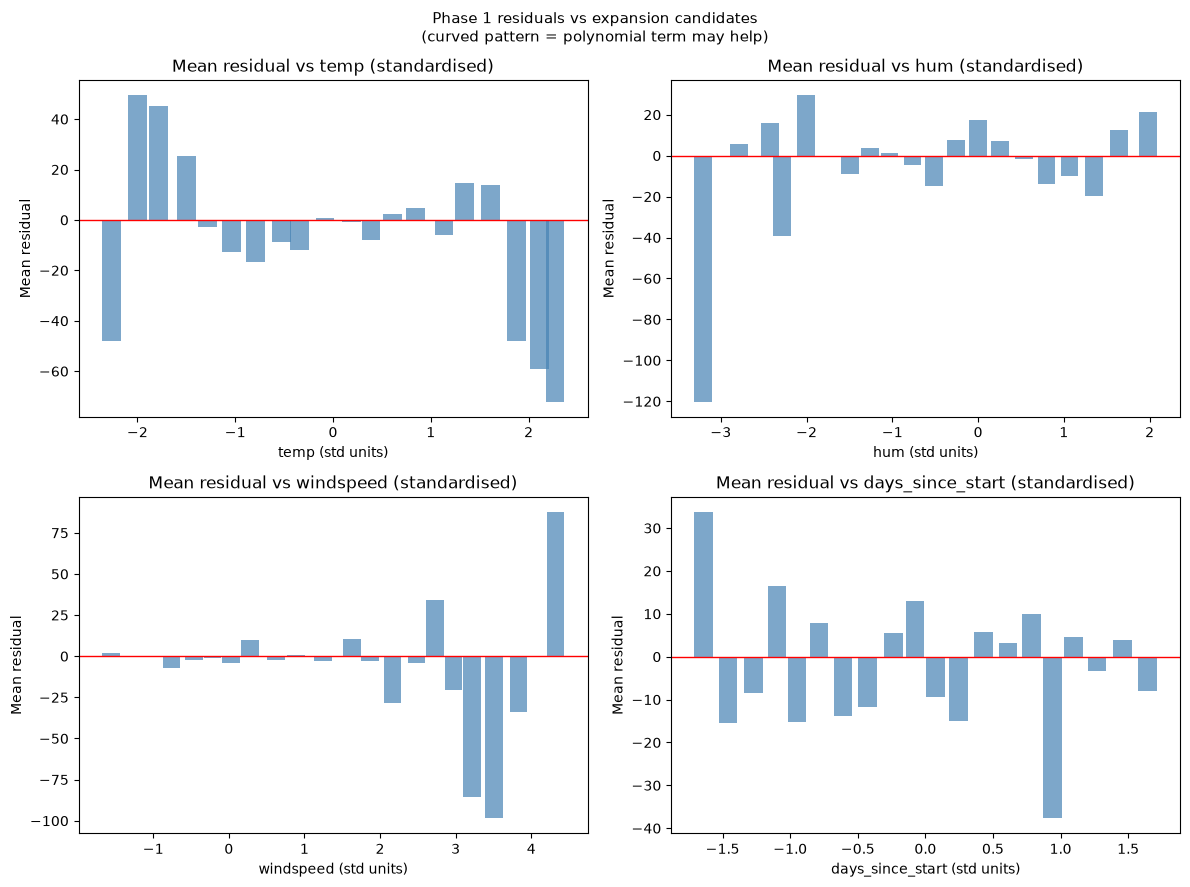

In [39]:
# ── T2.1: Residuals of Phase 1 vs each source column ─────────────────────────
residuals_p1 = y_val - y_val_pred_p1   # positive = under-predicted

print('=== Phase 1 residuals binned by each source column (val set) ===')
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes = axes.flatten()

for ax, col in zip(axes, SOURCE_COLS):
    feat_idx = P1_FEAT_NAMES.index(col)
    feat_vals = X_VAL_P1[:, feat_idx]  # already standardised
    # Bin into 20 bins
    n_bins = 20
    bin_idx = pd.cut(feat_vals, bins=n_bins, labels=False)
    res_df  = pd.DataFrame({'bin': bin_idx, 'res': residuals_p1, 'x': feat_vals})
    grp     = res_df.groupby('bin').agg(x_mean=('x','mean'), res_mean=('res','mean'))
    ax.bar(grp['x_mean'], grp['res_mean'], width=(feat_vals.max()-feat_vals.min())/n_bins*0.8,
           color='steelblue', alpha=0.7)
    ax.axhline(0, color='red', lw=1)
    ax.set_title(f'Mean residual vs {col} (standardised)')
    ax.set_xlabel(f'{col} (std units)'); ax.set_ylabel('Mean residual')

fig.suptitle('Phase 1 residuals vs expansion candidates\n(curved pattern = polynomial term may help)',
             fontsize=11)
fig.tight_layout()
plt.show()

In [40]:
# ── T2.2: Pearson vs Spearman correlation with cnt ───────────────────────────
print('=== Pearson vs Spearman r with cnt (train set) ===')
print(f'{"Column":<25} {"Pearson":>10} {"Spearman":>10}  Note')
print('-' * 60)
for col in SOURCE_COLS + ['atemp']:
    if col not in P1_FEAT_NAMES:
        continue
    idx = P1_FEAT_NAMES.index(col)
    x   = X_TRAIN_P1[:, idx]
    r_p = float(np.corrcoef(x, y_train)[0, 1])
    r_s = float(scipy_stats.spearmanr(x, y_train).statistic)
    note = 'non-monotone' if abs(r_p) < abs(r_s) - 0.05 else ''
    print(f'{col:<25} {r_p:>10.4f} {r_s:>10.4f}  {note}')

=== Pearson vs Spearman r with cnt (train set) ===
Column                       Pearson   Spearman  Note
------------------------------------------------------------
temp                          0.3992     0.4151  
hum                          -0.3191    -0.3597  
windspeed                     0.1048     0.1403  
days_since_start              0.3129     0.2828  
atemp                         0.3934     0.4135  


In [41]:
# ── T2.3: Single-feature linear vs quadratic screening ───────────────────────
# Quick lstsq comparison per source (labelled: closed-form screening, not GD)
print('=== Single-feature screening: linear vs quadratic (closed-form, val R²) ===')
print(f'{"Column":<25} {"Lin val R²":>12} {"Quad val R²":>12}  {"Lift":>8}')
print('-' * 65)

screening_results = {}
for col in SOURCE_COLS:
    idx = P1_FEAT_NAMES.index(col)
    x_tr = X_TRAIN_P1[:, idx:idx+1]  # shape (n,1)
    x_vl = X_VAL_P1[:,   idx:idx+1]

    # Linear
    A_lin = np.hstack([x_tr, np.ones((len(x_tr),1))])
    th_l, _, _, _ = np.linalg.lstsq(A_lin, y_train, rcond=None)
    y_vl_l = x_vl @ th_l[:1] + th_l[1]
    r2_l   = r2_score_np(y_val, y_vl_l)

    # Quadratic
    x_tr_sq = x_tr**2;  x_vl_sq = x_vl**2
    # Standardise quadratic term on train
    mu_sq = x_tr_sq.mean(); sig_sq = x_tr_sq.std()
    if sig_sq == 0: sig_sq = 1.0
    x_tr_sq_s = (x_tr_sq - mu_sq) / sig_sq
    x_vl_sq_s = (x_vl_sq - mu_sq) / sig_sq
    A_quad = np.hstack([x_tr, x_tr_sq_s, np.ones((len(x_tr),1))])
    th_q, _, _, _ = np.linalg.lstsq(A_quad, y_train, rcond=None)
    y_vl_q = x_vl @ th_q[:1] + x_vl_sq_s @ th_q[1:2] + th_q[2]
    r2_q   = r2_score_np(y_val, y_vl_q)

    lift = r2_q - r2_l
    screening_results[col] = {'r2_lin': r2_l, 'r2_quad': r2_q, 'lift': lift}
    print(f'{col:<25} {r2_l:>12.6f} {r2_q:>12.6f}  {lift:>8.6f}')

=== Single-feature screening: linear vs quadratic (closed-form, val R²) ===
Column                      Lin val R²  Quad val R²      Lift
-----------------------------------------------------------------
temp                          0.139354     0.138150  -0.001205
hum                           0.095983     0.094835  -0.001148
windspeed                     0.007166     0.010232  0.003066
days_since_start              0.087109     0.091461  0.004352


In [42]:
# ── T2.4: Hour × workingday residual — hypothesis for interactions ────────────
print('=== Phase 1 mean residual by hr x workingday ===')
val_hr  = val_df['hr'].values
val_wd  = val_df['workingday'].values
res_df  = pd.DataFrame({'hr': val_hr, 'wd': val_wd, 'res': residuals_p1})
pivot   = res_df.pivot_table(values='res', index='hr', columns='wd', aggfunc='mean')
pivot.columns = ['Non-workday', 'Workday']
print(pivot.to_string())
print('\n[NOTE] Interactions between hr dummies and continuous features may explain')
print('residual patterns more than polynomial powers. This is a hypothesis for the team.')

=== Phase 1 mean residual by hr x workingday ===
    Non-workday    Workday
hr                        
0     12.057492 -34.386940
1     52.543595 -34.359446
2     30.021415 -23.156943
3     28.420786  -4.773094
4     -1.565761  -5.278218
5    -23.532737  -1.791318
6    -23.137430  28.399602
7   -166.294808  85.548281
8   -277.000815  88.914291
9    -38.763074  26.996365
10    83.233533 -49.244338
11   111.933804 -57.157799
12   149.444979 -49.434418
13   174.143767 -57.608892
14   127.675886 -62.668842
15    95.433676 -67.585362
16    91.379899 -14.934909
17  -153.697934  45.431633
18  -156.572461  90.544781
19   -70.407598  30.511304
20   -44.068699  -1.724918
21   -10.051358  14.791793
22    -9.042310   3.147687
23     8.359644  -3.618680

[NOTE] Interactions between hr dummies and continuous features may explain
residual patterns more than polynomial powers. This is a hypothesis for the team.


---
## Task 3 — Expansion Module & Tests

In [43]:
# ── T3.1: Term count tests ────────────────────────────────────────────────────
k = len(SOURCE_COLS)
print(f'k (source columns) = {k}')
print()

t3_passes = []
for d in [2, 3, 4]:
    for interactions in [False, True]:
        expected = poly_term_count_expected(k, d, interactions)
        specs    = get_poly_term_specs_p2(SOURCE_COLS, d, interactions)
        actual   = len(specs)
        ok = (actual == expected)
        t3_passes.append(ok)
        mode = 'full' if interactions else 'pure'
        print(f'[{"PASS" if ok else "FAIL"}] degree={d} {mode:<6}: expected {expected}, got {actual}'
              + (f'  Terms: {[n for n,_ in specs[:5]]}...' if d<=2 else ''))

print(f'\nT3.1 term count: {sum(t3_passes)}/{len(t3_passes)} passed')

k (source columns) = 4

[PASS] degree=2 pure  : expected 4, got 4  Terms: ['temp^2', 'hum^2', 'windspeed^2', 'days_since_start^2']...
[PASS] degree=2 full  : expected 10, got 10  Terms: ['temp^2', 'temp*hum', 'temp*windspeed', 'temp*days_since_start', 'hum^2']...
[PASS] degree=3 pure  : expected 8, got 8
[PASS] degree=3 full  : expected 30, got 30
[PASS] degree=4 pure  : expected 12, got 12
[PASS] degree=4 full  : expected 65, got 65

T3.1 term count: 6/6 passed


In [44]:
# ── T3.2: Build degree-2 expanded matrices (default config) ──────────────────
DEGREE_TEST = 2
POLY_PARAMS_TEST = fit_poly_p2(X_TRAIN_P1, P1_FEAT_NAMES,
                               SOURCE_COLS, DEGREE_TEST, interactions=False)

X_TR_EXP_TEST, EXP_NAMES_TEST = transform_poly_p2(X_TRAIN_P1, P1_FEAT_NAMES, POLY_PARAMS_TEST)
X_VL_EXP_TEST, _              = transform_poly_p2(X_VAL_P1,   P1_FEAT_NAMES, POLY_PARAMS_TEST)
X_TE_EXP_TEST, _              = transform_poly_p2(X_TEST_P1,  P1_FEAT_NAMES, POLY_PARAMS_TEST)

p1 = X_TRAIN_P1.shape[1]
n_new_d2 = POLY_PARAMS_TEST['n_new_cols']

print(f'Phase 1 features  : {p1}')
print(f'New (degree 2)    : {n_new_d2}')
print(f'Total expanded    : {X_TR_EXP_TEST.shape[1]}')
print(f'New col names     : {EXP_NAMES_TEST[p1:]}')

Phase 1 features  : 54
New (degree 2)    : 4
Total expanded    : 58
New col names     : ['temp^2', 'hum^2', 'windspeed^2', 'days_since_start^2']


In [45]:
# ── T3.3: Expansion correctness tests ────────────────────────────────────────
t3_corr = []

# (a) Phase 1 block is bit-identical
ok_p1_block = np.array_equal(X_TR_EXP_TEST[:, :p1], X_TRAIN_P1)
t3_corr.append(ok_p1_block)
print(f'[{"PASS" if ok_p1_block else "FAIL"}] T3.3a Phase 1 block bit-identical in X_expanded')

# (b) No NaN or inf
ok_finite = (np.isfinite(X_TR_EXP_TEST).all() and
             np.isfinite(X_VL_EXP_TEST).all() and
             np.isfinite(X_TE_EXP_TEST).all())
t3_corr.append(ok_finite)
print(f'[{"PASS" if ok_finite else "FAIL"}] T3.3b No NaN/inf in any expanded matrix')

# (c) Train new columns: mean≈0, std≈1
new_block = X_TR_EXP_TEST[:, p1:]
col_means = new_block.mean(axis=0)
col_stds  = new_block.std(axis=0)
ok_scaled = (np.abs(col_means) < 1e-6).all() and (np.abs(col_stds - 1.0) < 1e-6).all()
t3_corr.append(ok_scaled)
print(f'[{"PASS" if ok_scaled else "FAIL"}] T3.3c Train new cols: max|mean|={np.abs(col_means).max():.2e}  '
      f'max|std-1|={np.abs(col_stds-1).max():.2e}')

# (d) Val and test do NOT necessarily have mean=0 (they use train params)
val_new_means = X_VL_EXP_TEST[:, p1:].mean(axis=0)
print(f'       Val new col means (not 0 by design): mean={val_new_means.mean():.4f}')

# (e) Identical column names across splits
_, names_val_test = transform_poly_p2(X_VAL_P1, P1_FEAT_NAMES, POLY_PARAMS_TEST)
_, names_te_test  = transform_poly_p2(X_TEST_P1, P1_FEAT_NAMES, POLY_PARAMS_TEST)
ok_names = (EXP_NAMES_TEST == names_val_test == names_te_test)
t3_corr.append(ok_names)
print(f'[{"PASS" if ok_names else "FAIL"}] T3.3d All splits share identical column names')

# (f) Values match manual numpy computation
# Manually compute temp^2 standardised
temp_idx = P1_FEAT_NAMES.index('temp')
raw_temp_sq  = X_TRAIN_P1[:, temp_idx] ** 2
mu_ts  = raw_temp_sq.mean(); sig_ts = raw_temp_sq.std()
manual_col   = (raw_temp_sq - mu_ts) / sig_ts
exp_col_idx  = EXP_NAMES_TEST.index('temp^2')
ok_manual    = np.allclose(X_TR_EXP_TEST[:, exp_col_idx], manual_col, atol=1e-10)
t3_corr.append(ok_manual)
print(f'[{"PASS" if ok_manual else "FAIL"}] T3.3e Values match manual computation (temp^2)')

# (g) Single-row transform works
try:
    _ = transform_poly_p2(X_TRAIN_P1[:1, :], P1_FEAT_NAMES, POLY_PARAMS_TEST)
    t3_corr.append(True)
    print('[PASS] T3.3f Single-row transform works')
except Exception as e:
    t3_corr.append(False)
    print(f'[FAIL] T3.3f Single-row transform crashed: {e}')

# (h) sklearn PolynomialFeatures cross-check (in test only, labelled)
pf_ref = PolynomialFeatures(degree=2, include_bias=False)
src_indices_test = [P1_FEAT_NAMES.index(c) for c in SOURCE_COLS]
X_src_tr = X_TRAIN_P1[:, src_indices_test]
raw_ref  = pf_ref.fit_transform(X_src_tr)  # degree 1+2 terms
# Our degree-2 new cols = raw_ref[:, k:] (columns after degree-1)
# (sklearn includes degree-1 first, then degree-2)
# For pure powers only: compare col by col
our_new_raw  = new_block * POLY_PARAMS_TEST['poly_stds'] + POLY_PARAMS_TEST['poly_means']
# Build reference pure-power matrix
ref_pp = X_src_tr ** 2   # shape (n,k)
ok_sk  = np.allclose(our_new_raw, ref_pp, atol=1e-8)
t3_corr.append(ok_sk)
print(f'[{"PASS" if ok_sk else "FAIL"}] T3.3g sklearn cross-check (pure powers d=2, reference only)')

print(f'\n=== T3.3 total: {sum(t3_corr)}/{len(t3_corr)} passed ===')

[PASS] T3.3a Phase 1 block bit-identical in X_expanded
[PASS] T3.3b No NaN/inf in any expanded matrix
[PASS] T3.3c Train new cols: max|mean|=3.71e-16  max|std-1|=1.79e-14
       Val new col means (not 0 by design): mean=-0.0048
[PASS] T3.3d All splits share identical column names
[PASS] T3.3e Values match manual computation (temp^2)
[PASS] T3.3f Single-row transform works
[PASS] T3.3g sklearn cross-check (pure powers d=2, reference only)

=== T3.3 total: 7/7 passed ===


---
## Task 4 — Warm Start

In [46]:
# ── T4.1: Construct warm start & run identity tests ──────────────────────────
n_new_d2 = POLY_PARAMS_TEST['n_new_cols']
w_init_d2, b_init_d2 = build_warm_start(W_P1, B_P1, n_new_d2)

# Predictions at iteration 0
y_tr_iter0 = predict(X_TR_EXP_TEST, w_init_d2, b_init_d2)
y_vl_iter0 = predict(X_VL_EXP_TEST, w_init_d2, b_init_d2)

max_diff_tr = float(np.abs(y_tr_iter0 - y_tr_pred_p1).max())
max_diff_vl = float(np.abs(y_vl_iter0 - y_val_pred_p1).max())

ok_ws_tr = max_diff_tr < 1e-10
ok_ws_vl = max_diff_vl < 1e-10
print(f'[{"PASS" if ok_ws_tr else "FAIL"}] T4.1a Warm-start train pred == Phase 1  max|Δ|={max_diff_tr:.2e}')
print(f'[{"PASS" if ok_ws_vl else "FAIL"}] T4.1b Warm-start val   pred == Phase 1  max|Δ|={max_diff_vl:.2e}')

# Initial loss equals Phase 1 final loss
loss_iter0 = mse_loss(X_TR_EXP_TEST, y_train, w_init_d2, b_init_d2)
p1_final_loss = META_P1['final_train_loss']
ok_loss0 = abs(loss_iter0 - p1_final_loss) < 1e-6
print(f'[{"PASS" if ok_loss0 else "FAIL"}] T4.1c Initial loss == Phase 1 final loss  '
      f'init={loss_iter0:.8f}  stored={p1_final_loss:.8f}')

# Initial gradient on new block (should be non-zero if expansion can help)
r0 = X_TR_EXP_TEST @ w_init_d2 + b_init_d2 - y_train
grad_new_block = X_TR_EXP_TEST[:, p1:].T @ r0 / len(y_train)
grad_norm_new  = float(np.linalg.norm(grad_new_block))
print(f'[INFO] Initial gradient norm on new block: {grad_norm_new:.6f}  '
      f'(non-zero = expansion can improve)') 

[PASS] T4.1a Warm-start train pred == Phase 1  max|Δ|=2.27e-13
[PASS] T4.1b Warm-start val   pred == Phase 1  max|Δ|=1.42e-13
[PASS] T4.1c Initial loss == Phase 1 final loss  init=5006.70657632  stored=5006.70657632
[INFO] Initial gradient norm on new block: 7.144046  (non-zero = expansion can improve)


In [47]:
# ── T4.2: Warm start vs zero init comparison (degree 2) ──────────────────────
L_d2 = lipschitz_constant(X_TR_EXP_TEST)
lr_d2 = 0.9 / L_d2
MAX_ITER_COMPARE = 50000

print(f'Comparison: warm start vs zero init (degree=2, lr={lr_d2:.6f}, max_iter={MAX_ITER_COMPARE})')

# Warm start
t0 = time.time()
res_warm = gd_fit(X_TR_EXP_TEST, y_train,
                       lr=lr_d2, max_iter=MAX_ITER_COMPARE, tol=1e-6,
                       w0=w_init_d2, b0=b_init_d2,
                       X_val=X_VL_EXP_TEST, y_val=y_val)
t_warm = time.time() - t0

# Zero init
t0 = time.time()
res_zero = gd_fit(X_TR_EXP_TEST, y_train,
                       lr=lr_d2, max_iter=MAX_ITER_COMPARE, tol=1e-6,
                       X_val=X_VL_EXP_TEST, y_val=y_val)
t_zero = time.time() - t0

r2_warm = r2_score_np(y_val, predict(X_VL_EXP_TEST, res_warm['w'], res_warm['b']))
r2_zero = r2_score_np(y_val, predict(X_VL_EXP_TEST, res_zero['w'], res_zero['b']))

print(f'\n{"Init":>12}  {"Iters":>8}  {"Train Loss":>14}  {"Val R²":>10}  {"Time(s)":>8}  {"Status"}')
print('-' * 75)
print(f'{"Warm (P1)":>12}  {res_warm["n_iter"]:>8}  {res_warm["final_train_loss"]:>14.4f}  '
      f'{r2_warm:>10.6f}  {t_warm:>8.2f}  {res_warm["status"]}')
print(f'{"Zero":>12}  {res_zero["n_iter"]:>8}  {res_zero["final_train_loss"]:>14.4f}  '
      f'{r2_zero:>10.6f}  {t_zero:>8.2f}  {res_zero["status"]}')

Comparison: warm start vs zero init (degree=2, lr=0.366392, max_iter=50000)



        Init     Iters      Train Loss      Val R²   Time(s)  Status
---------------------------------------------------------------------------
   Warm (P1)       178       4970.0046    0.679589      0.06  converged
        Zero      3603       4972.1586    0.679206      1.33  converged


---
## Task 5 — LR Sweep at Chosen Degree

In [48]:
# ── T5: LR sweep at degree 2 (will be updated after T6 selects degree) ───────
L = L_d2
lr_sweep = [
    round(0.1 / L, 8),
    round(0.5 / L, 8),
    round(0.9 / L, 8),   # ← chosen (safe margin below 1/L)
    round(1.0 / L, 8),
    round(1.5 / L, 8),
    round(2.0 / L, 8),
    round(2.1 / L, 8),
]
kappa_d2 = compute_condition_number(X_TR_EXP_TEST)

print(f'L_d2 = {L:.6f}  1/L = {1/L:.6f}  2/L = {2/L:.6f}')
print(f'κ = {kappa_d2:.4e}')
print()
print(f'{"LR":>12}  {"Iters":>7}  {"Train Loss":>12}  {"Val R²":>10}  {"Status"}')
print('-' * 62)

for lr_val in lr_sweep:
    res = gd_fit(X_TR_EXP_TEST, y_train,
                      lr=lr_val, max_iter=30000, tol=1e-7,
                      w0=w_init_d2, b0=b_init_d2)
    y_vp = predict(X_VL_EXP_TEST, res['w'], res['b'])
    r2   = r2_score_np(y_val, y_vp) if res['status'] != 'diverged' else float('nan')
    print(f'{lr_val:>12.6f}  {res["n_iter"]:>7}  {res["final_train_loss"]:>12.4f}  '
          f'{r2:>10.6f}  {res["status"]}')

L_d2 = 2.456388  1/L = 0.407102  2/L = 0.814204
κ = 1.5032e+03

          LR    Iters    Train Loss      Val R²  Status
--------------------------------------------------------------


    0.040710     1678     4969.9673    0.679589  converged


    0.203551     1729     4968.7495    0.679695  converged


    0.366392     1541     4968.3593    0.679770  converged


    0.407102     1487     4968.3069    0.679781  converged


    0.610653     1273     4968.1353    0.679819  converged


    0.814204     1131     4968.0346    0.679847  converged
    0.854914      161  5848046088.7585         nan  diverged


---
## Task 6 — Degree Sweep & Selection

In [49]:
# ── T6.1: Full degree sweep d=1..6 ───────────────────────────────────────────
PARSIMONY_TOL = 0.001   # accept degree d if val_R² >= best - PARSIMONY_TOL
MAX_DEGREE    = 6
MAX_ITER_SWEEP = 200_000
INTERACTIONS   = False  # default: pure powers

print(f'Degree sweep: d=1..{MAX_DEGREE}, interactions={INTERACTIONS}')
print(f'Source cols : {SOURCE_COLS}')
print(f'Parsimony tol: {PARSIMONY_TOL}')
print()

degree_table = []
sweep_results = {}

# degree=1 is Phase 1 itself (reference row)
row_d1 = {
    'degree'       : 1,
    'n_new_cols'   : 0,
    'n_total'      : p1,
    'kappa'        : compute_condition_number(X_TRAIN_P1),
    'status'       : META_P1['status'] if 'status' in META_P1 else 'converged',
    'n_iter'       : META_P1['iterations_used'],
    'train_r2'     : float(R2_TR_P1),
    'val_r2'       : float(R2_VAL_P1),
    'train_rmse'   : float(RMSE_TR_P1),
    'val_rmse'     : float(RMSE_VAL_P1),
    'r2_gap'       : float(R2_TR_P1 - R2_VAL_P1),
    'neg_pct'      : float(100*(predict(X_VAL_P1, W_P1, B_P1) < 0).mean()),
    'lstsq_val_r2' : float(r2_score_np(y_val, predict(X_VAL_P1, *[W_P1, B_P1]))),
    'opt_gap'      : 0.0,
    'opt_limited'  : False,
    'wall_s'       : 0.0,
}
degree_table.append(row_d1)
print(f'd=1 (Phase 1): val R²={R2_VAL_P1:.6f}  RMSE={RMSE_VAL_P1:.4f}')

prev_opt_limited_count = 0
for d in range(2, MAX_DEGREE + 1):
    print(f'  Fitting degree {d}...', end=' ', flush=True)
    res = fit_expanded_p2(
        X_TRAIN_P1, y_train, X_VAL_P1, y_val,
        P1_FEAT_NAMES, SOURCE_COLS, d, INTERACTIONS,
        W_P1, B_P1,
        max_iter=MAX_ITER_SWEEP, tol=1e-6,
    )
    sweep_results[d] = res
    neg_pct = float(100*(predict(res['X_val_exp'], res['w'], res['b']) < 0).mean())
    row = {
        'degree'      : d,
        'n_new_cols'  : res['n_new_cols'],
        'n_total'     : res['n_total_cols'],
        'kappa'       : res['kappa'],
        'status'      : res['status'],
        'n_iter'      : res['n_iter'],
        'train_r2'    : res['train_r2'],
        'val_r2'      : res['val_r2'],
        'train_rmse'  : res['train_rmse'],
        'val_rmse'    : res['val_rmse'],
        'r2_gap'      : res['train_r2'] - res['val_r2'],
        'neg_pct'     : neg_pct,
        'lstsq_val_r2': res['lstsq_val_r2'],
        'opt_gap'     : res['opt_gap_relative'],
        'opt_limited' : res['optimization_limited'],
        'wall_s'      : res['wall_time_s'],
    }
    degree_table.append(row)
    flag = ' *** OPTIMIZATION-LIMITED ***' if res['optimization_limited'] else ''
    print(f'val R²={res["val_r2"]:.6f}  lstsq R²={res["lstsq_val_r2"]:.6f}  '
          f'κ={res["kappa"]:.2e}  status={res["status"]}  opt_gap={res["opt_gap_relative"]:.2e}{flag}')
    if res['optimization_limited']:
        prev_opt_limited_count += 1
    else:
        prev_opt_limited_count = 0
    if prev_opt_limited_count >= 3:
        print('  [STOPPING] 3 consecutive optimization-limited degrees. Higher degrees unreliable.')
        break

Degree sweep: d=1..6, interactions=False
Source cols : ['temp', 'hum', 'windspeed', 'days_since_start']
Parsimony tol: 0.001

d=1 (Phase 1): val R²=0.678137  RMSE=100.4427
  Fitting degree 2... 

val R²=0.679589  lstsq R²=0.679845  κ=1.50e+03  status=converged  opt_gap=8.34e-04
  Fitting degree 3... 

val R²=0.685827  lstsq R²=0.686032  κ=2.13e+03  status=converged  opt_gap=5.63e-04
  Fitting degree 4... 

val R²=0.686548  lstsq R²=0.686712  κ=2.35e+03  status=converged  opt_gap=6.74e-04


  Fitting degree 5... 

val R²=0.686370  lstsq R²=0.686989  κ=1.32e+04  status=converged  opt_gap=2.12e-03 *** OPTIMIZATION-LIMITED ***


  Fitting degree 6... 

val R²=0.686595  lstsq R²=0.687241  κ=1.98e+05  status=converged  opt_gap=2.07e-03 *** OPTIMIZATION-LIMITED ***


In [50]:
# ── T6.2: Print degree table ──────────────────────────────────────────────────
print('\n=== DEGREE SWEEP TABLE ===')
print(f'{"d":>3} {"n_new":>6} {"n_tot":>6} {"κ":>10} {"status":<15} '
      f'{"train R²":>10} {"val R²":>10} {"gap":>8} {"neg%":>6} '
      f'{"lstsq R²":>10} {"opt_gap":>9} {"flag"}')
print('-'*115)

valid_val_r2 = []
for row in degree_table:
    flag = '⚠ OPT-LIM' if row['opt_limited'] else ''
    # Only use lstsq val R² for opt-limited degrees
    eff_r2 = row['lstsq_val_r2'] if row['opt_limited'] else row['val_r2']
    if not row['opt_limited']:
        valid_val_r2.append((row['degree'], row['val_r2']))
    print(f"{row['degree']:>3} {row['n_new_cols']:>6} {row['n_total']:>6} "
          f"{row['kappa']:>10.2e} {row['status']:<15} "
          f"{row['train_r2']:>10.6f} {row['val_r2']:>10.6f} "
          f"{row['r2_gap']:>8.6f} {row['neg_pct']:>6.2f} "
          f"{row['lstsq_val_r2']:>10.6f} {row['opt_gap']:>9.2e} {flag}")


=== DEGREE SWEEP TABLE ===
  d  n_new  n_tot          κ status            train R²     val R²      gap   neg%   lstsq R²   opt_gap flag
-------------------------------------------------------------------------------------------------------------------
  1      0     54   1.44e+03 converged         0.698181   0.678137 0.020044   9.55   0.678137  0.00e+00 
  2      4     58   1.50e+03 converged         0.700393   0.679589 0.020804   9.92   0.679845  8.34e-04 
  3      8     62   2.13e+03 converged         0.704422   0.685827 0.018595   9.92   0.686032  5.63e-04 
  4     12     66   2.35e+03 converged         0.705564   0.686548 0.019016  10.19   0.686712  6.74e-04 
  5     16     70   1.32e+04 converged         0.705922   0.686370 0.019552  10.19   0.686989  2.12e-03 ⚠ OPT-LIM
  6     20     74   1.98e+05 converged         0.706039   0.686595 0.019444  10.15   0.687241  2.07e-03 ⚠ OPT-LIM


In [51]:
# ── T6.3: Choose degree ───────────────────────────────────────────────────────
if valid_val_r2:
    best_d, best_r2 = max(valid_val_r2, key=lambda x: x[1])
    # Parsimony: smallest d within PARSIMONY_TOL of best
    CHOSEN_DEGREE = min(d for d, r2 in valid_val_r2 if r2 >= best_r2 - PARSIMONY_TOL)
else:
    CHOSEN_DEGREE = 2  # fallback
    best_r2 = R2_VAL_P1

print(f'Best non-OPT-LIM degree: {best_d}  val R²={best_r2:.6f}')
print(f'Parsimony rule: accept d if val_R² >= {best_r2:.6f} - {PARSIMONY_TOL} = {best_r2-PARSIMONY_TOL:.6f}')
print(f'CHOSEN DEGREE: {CHOSEN_DEGREE}')

Best non-OPT-LIM degree: 4  val R²=0.686548
Parsimony rule: accept d if val_R² >= 0.686548 - 0.001 = 0.685548
CHOSEN DEGREE: 3


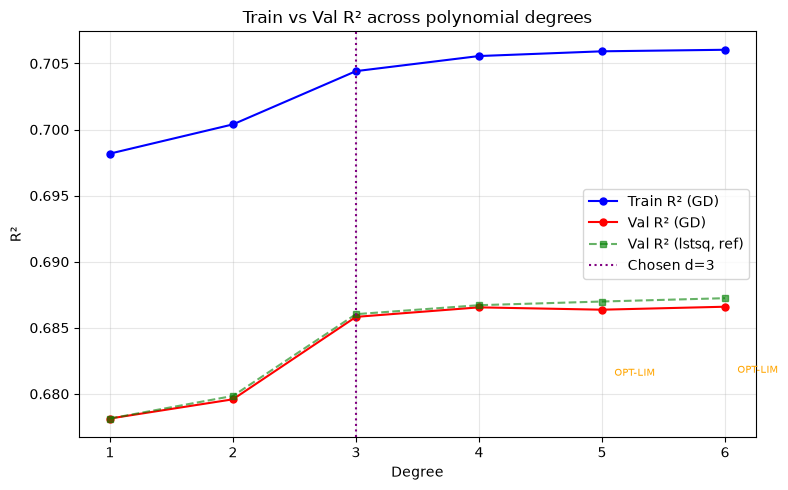

In [52]:
# ── T6.4: Train/val R² vs degree plot ────────────────────────────────────────
degrees   = [r['degree']    for r in degree_table]
tr_r2s    = [r['train_r2']  for r in degree_table]
vl_r2s    = [r['val_r2']    for r in degree_table]
cf_r2s    = [r['lstsq_val_r2'] for r in degree_table]
opt_flags = [r['opt_limited']  for r in degree_table]

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(degrees, tr_r2s, 'b-o', label='Train R² (GD)', markersize=5)
ax.plot(degrees, vl_r2s, 'r-o', label='Val R² (GD)',   markersize=5)
ax.plot(degrees, cf_r2s, 'g--s', label='Val R² (lstsq, ref)', markersize=5, alpha=0.6)
for d, r2, flag in zip(degrees, vl_r2s, opt_flags):
    if flag:
        ax.annotate('OPT-LIM', (d, r2), fontsize=7, color='orange',
                    xytext=(d+0.1, r2-0.005))
ax.axvline(CHOSEN_DEGREE, color='purple', linestyle=':', label=f'Chosen d={CHOSEN_DEGREE}')
ax.set_xlabel('Degree'); ax.set_ylabel('R²')
ax.set_title('Train vs Val R² across polynomial degrees')
ax.legend(); ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

In [53]:
# ── T6.5: Ablation table ─────────────────────────────────────────────────────
print('=== ABLATION TABLE (closed-form, val R², chosen degree) ===')
d_abl = CHOSEN_DEGREE

def abl_eval(src, label, inter=False):
    pp = fit_poly_p2(X_TRAIN_P1, P1_FEAT_NAMES, src, d_abl, inter)
    X_te, _ = transform_poly_p2(X_TRAIN_P1, P1_FEAT_NAMES, pp)
    X_ve, _ = transform_poly_p2(X_VAL_P1,   P1_FEAT_NAMES, pp)
    X_aug   = np.hstack([X_te, np.ones((len(X_te),1))])
    th, _,_,_ = np.linalg.lstsq(X_aug, y_train, rcond=None)
    r2 = r2_score_np(y_val, predict(X_ve, th[:-1], float(th[-1])))
    print(f'  {label:<45} val R²={r2:.6f}  p={X_te.shape[1]}')
    return r2

abl_results = {}
abl_results['Baseline (temp,hum,wind,days, pure)'] = \
    abl_eval(SOURCE_COLS, 'Baseline (temp,hum,wind,days, pure powers)')
abl_results['+ atemp'] = \
    abl_eval(SOURCE_COLS+['atemp'], 'With atemp added (near-dup temp, trap #3)')
abl_results['No days_since_start'] = \
    abl_eval(['temp','hum','windspeed'], 'No days_since_start (extrap risk)')
abl_results['No windspeed'] = \
    abl_eval(['temp','hum','days_since_start'], 'No windspeed')
abl_results['temp only'] = \
    abl_eval(['temp'], 'temp only')
abl_results['Full interactions'] = \
    abl_eval(SOURCE_COLS, 'Full interactions (interactions=True)', inter=True)

print('\n=== Summary (sorted by val R²) ===')
for k_lbl, v in sorted(abl_results.items(), key=lambda x: -x[1]):
    print(f'  {k_lbl:<45}  {v:.6f}')

=== ABLATION TABLE (closed-form, val R², chosen degree) ===
  Baseline (temp,hum,wind,days, pure powers)    val R²=0.686032  p=62
  With atemp added (near-dup temp, trap #3)     val R²=0.685411  p=64
  No days_since_start (extrap risk)             val R²=0.685849  p=60


  No windspeed                                  val R²=0.685667  p=60


  temp only                                     val R²=0.685357  p=56
  Full interactions (interactions=True)         val R²=0.714613  p=84

=== Summary (sorted by val R²) ===
  Full interactions                              0.714613
  Baseline (temp,hum,wind,days, pure)            0.686032
  No days_since_start                            0.685849
  No windspeed                                   0.685667
  + atemp                                        0.685411
  temp only                                      0.685357


---
## Task 7 — Test Suite (all 12 must pass)

In [54]:
# ── Fit final model at chosen degree ─────────────────────────────────────────
FINAL_RES_P2 = fit_expanded_p2(
    X_TRAIN_P1, y_train, X_VAL_P1, y_val,
    P1_FEAT_NAMES, SOURCE_COLS, CHOSEN_DEGREE, INTERACTIONS,
    W_P1, B_P1,
    max_iter=300_000, tol=1e-6, record_every=500
)

W_P2      = FINAL_RES_P2['w']
B_P2      = FINAL_RES_P2['b']
POLY_PARAMS = FINAL_RES_P2['poly_params']
X_TR_EXP  = FINAL_RES_P2['X_train_exp']
X_VL_EXP  = FINAL_RES_P2['X_val_exp']
EXP_NAMES = FINAL_RES_P2['expanded_names']
L_FINAL   = FINAL_RES_P2['L_d']
LR_FINAL  = FINAL_RES_P2['lr_used']

X_TE_EXP, _ = transform_poly_p2(X_TEST_P1, P1_FEAT_NAMES, POLY_PARAMS)

R2_TR_P2   = FINAL_RES_P2['train_r2']
R2_VL_P2   = FINAL_RES_P2['val_r2']
RMSE_TR_P2 = FINAL_RES_P2['train_rmse']
RMSE_VL_P2 = FINAL_RES_P2['val_rmse']

print(f'FINAL MODEL: degree={CHOSEN_DEGREE}  interactions={INTERACTIONS}')
print(f'  Features: {X_TR_EXP.shape[1]} total ({FINAL_RES_P2["n_new_cols"]} new)')
print(f'  Train R²={R2_TR_P2:.6f}  RMSE={RMSE_TR_P2:.4f}')
print(f'  Val   R²={R2_VL_P2:.6f}  RMSE={RMSE_VL_P2:.4f}')
print(f'  Status: {FINAL_RES_P2["status"]}  Iters: {FINAL_RES_P2["n_iter"]}')
print(f'  Opt-limited: {FINAL_RES_P2["optimization_limited"]}  opt_gap={FINAL_RES_P2["opt_gap_relative"]:.2e}')

FINAL MODEL: degree=3  interactions=False


  Features: 62 total (8 new)
  Train R²=0.704422  RMSE=99.0269
  Val   R²=0.685827  RMSE=99.2354
  Status: converged  Iters: 352
  Opt-limited: False  opt_gap=5.63e-04


In [55]:
# ── T7.1: Gradient check on expanded model ────────────────────────────────────
rng = np.random.default_rng(1)
w_rnd = rng.standard_normal(X_TR_EXP.shape[1]) * 0.01
b_rnd = float(rng.standard_normal())

gc_exp = gradient_check(
    X_TR_EXP, y_train, w_rnd, b_rnd,
    mse_grad, mse_loss, n_check=20
)
ok_gc = gc_exp['all_pass']
print(f'[{"PASS" if ok_gc else "FAIL"}] T7.1 Gradient check (expanded model)  '
      f'max_rel_w={gc_exp["max_rel_error_w"]:.2e}  max_rel_b={gc_exp["max_rel_error_b"]:.2e}')

[PASS] T7.1 Gradient check (expanded model)  max_rel_w=2.82e-07  max_rel_b=5.56e-10


In [56]:
# ── T7.2: Synthetic polynomial recovery ──────────────────────────────────────
rng2 = np.random.default_rng(99)
n_syn, p_syn = 300, X_TR_EXP.shape[1]
X_syn = rng2.standard_normal((n_syn, p_syn))
w_star_syn = rng2.standard_normal(p_syn) * 0.1
b_star_syn = float(rng2.standard_normal())
y_syn_clean = X_syn @ w_star_syn + b_star_syn

L_syn = lipschitz_constant(X_syn)
w_ws_syn, b_ws_syn = build_warm_start(
    w_star_syn[:p1] * 0.9,  # perturb Phase 1 block slightly
    b_star_syn, p_syn - p1
)

res_syn = gd_fit(X_syn, y_syn_clean,
                      lr=1.0/L_syn, max_iter=100000, tol=1e-11,
                      w0=w_ws_syn, b0=b_ws_syn)
w_err_syn = float(np.max(np.abs(res_syn['w'] - w_star_syn)))
ok_syn = w_err_syn < 1e-3
print(f'[{"PASS" if ok_syn else "FAIL"}] T7.2 Synthetic recovery  '
      f'max|Δw|={w_err_syn:.2e}  status={res_syn["status"]}')

[PASS] T7.2 Synthetic recovery  max|Δw|=9.11e-09  status=converged


In [57]:
# ── T7.3: Closed-form agreement at chosen degree ─────────────────────────────
CF_TOL = 1e-2  # relative; GD with tol=1e-6 may not fully match lstsq
gd_loss  = FINAL_RES_P2['final_train_loss']
cf_loss  = FINAL_RES_P2['lstsq_train_loss']
cf_gap   = FINAL_RES_P2['opt_gap_relative']
ok_cf    = cf_gap < CF_TOL
print(f'[{"PASS" if ok_cf else "FAIL"}] T7.3 Closed-form agreement  '
      f'GD loss={gd_loss:.4f}  lstsq loss={cf_loss:.4f}  '
      f'rel_gap={cf_gap:.2e}  (tol={CF_TOL})')
print(f'       GD val R²={R2_VL_P2:.6f}  lstsq val R²={FINAL_RES_P2["lstsq_val_r2"]:.6f}')
if FINAL_RES_P2['optimization_limited']:
    print('       ⚠ OPTIMIZATION-LIMITED: val R² reflects optimizer, not model quality')

[PASS] T7.3 Closed-form agreement  GD loss=4903.1675  lstsq loss=4900.4088  rel_gap=5.63e-04  (tol=0.01)
       GD val R²=0.685827  lstsq val R²=0.686032


In [58]:
# ── T7.4: Monotone loss & divergence ─────────────────────────────────────────
# Monotone at lr = 0.9/L_final
n_new_f = POLY_PARAMS['n_new_cols']
w_ws_f, b_ws_f = build_warm_start(W_P1, B_P1, n_new_f)
res_mono = gd_fit(X_TR_EXP, y_train,
                       lr=LR_FINAL, max_iter=500, tol=0, gtol=0, record_every=1,
                       w0=w_ws_f, b0=b_ws_f)
losses_seq = [v for _, v in res_mono['train_losses']]
diffs = np.diff(losses_seq)
ok_mono = bool(np.all(diffs <= 1e-10))
print(f'[{"PASS" if ok_mono else "FAIL"}] T7.4a Monotone loss at lr=0.9/L  '
      f'max_increase={diffs.max():.2e}')

# Divergence at lr > 2/L
res_div = gd_fit(X_TR_EXP, y_train,
                      lr=2.1/L_FINAL, max_iter=2000, tol=0, gtol=0,
                      w0=w_ws_f, b0=b_ws_f)
ok_div = (res_div['status'] == 'diverged')
print(f'[{"PASS" if ok_div else "FAIL"}] T7.4b Diverged at lr=2.1/L  status={res_div["status"]}')

[PASS] T7.4a Monotone loss at lr=0.9/L  max_increase=-2.41e-03


[PASS] T7.4b Diverged at lr=2.1/L  status=diverged


In [59]:
# ── T7.5: Nesting property (lstsq train loss non-increasing) ─────────────────
lstsq_losses = []
for d in range(1, CHOSEN_DEGREE + 2):  # go one beyond chosen
    if d == 1:
        X_aug1 = np.hstack([X_TRAIN_P1, np.ones((len(y_train),1))])
        th, _,_,_ = np.linalg.lstsq(X_aug1, y_train, rcond=None)
        l = mse_loss(X_TRAIN_P1, y_train, th[:-1], float(th[-1]))
    else:
        pp_d = fit_poly_p2(X_TRAIN_P1, P1_FEAT_NAMES, SOURCE_COLS, d, INTERACTIONS)
        X_e_d, _ = transform_poly_p2(X_TRAIN_P1, P1_FEAT_NAMES, pp_d)
        X_aug_d = np.hstack([X_e_d, np.ones((len(y_train),1))])
        th, _,_,_ = np.linalg.lstsq(X_aug_d, y_train, rcond=None)
        l = mse_loss(X_e_d, y_train, th[:-1], float(th[-1]))
    lstsq_losses.append((d, l))

print('Nesting property (lstsq train loss should be non-increasing):')
prev_l = None
all_nest = True
for d, l in lstsq_losses:
    ok_n = (prev_l is None) or (l <= prev_l + 1e-6)
    if not ok_n: all_nest = False
    print(f'  d={d}: lstsq train loss={l:.6f}  {"✓" if ok_n else "✗ VIOLATION"}')
    prev_l = l
print(f'[{"PASS" if all_nest else "FAIL"}] T7.5 Nesting property holds')

Nesting property (lstsq train loss should be non-increasing):
  d=1: lstsq train loss=5002.977646  ✓
  d=2: lstsq train loss=4965.861747  ✓
  d=3: lstsq train loss=4900.408802  ✓
  d=4: lstsq train loss=4880.936266  ✓
[PASS] T7.5 Nesting property holds


In [60]:
# ── T7.6: Warm-start identity (already tested in T4, re-verify for final degree)
y_vl_ws0 = predict(X_VL_EXP, w_ws_f, b_ws_f)
max_ws_diff = float(np.abs(y_vl_ws0 - y_val_pred_p1).max())
ok_ws = max_ws_diff < 1e-10
print(f'[{"PASS" if ok_ws else "FAIL"}] T7.6 Warm-start identity (final degree)  max|Δ|={max_ws_diff:.2e}')

[PASS] T7.6 Warm-start identity (final degree)  max|Δ|=1.42e-13


In [61]:
# ── T7.7: No-leakage test ─────────────────────────────────────────────────────────────────
# Refit poly on train+val -> params should differ
X_ALL_P1 = np.vstack([X_TRAIN_P1, X_VAL_P1])
y_all    = np.concatenate([y_train, y_val])

pp_all = fit_poly_p2(X_ALL_P1, P1_FEAT_NAMES, SOURCE_COLS, CHOSEN_DEGREE, INTERACTIONS)
means_train = np.array(POLY_PARAMS["poly_means"])
means_all   = np.array(pp_all["poly_means"])
stds_train  = np.array(POLY_PARAMS["poly_stds"])
stds_all    = np.array(pp_all["poly_stds"])

if len(means_train) == 0:
    ok_noleak = True
    print("[PASS] T7.7 No-leakage: No polynomial features generated (chosen degree=1).")
    print("       Pipeline uses train-only params ✓")
else:
    params_differ = not (np.allclose(means_train, means_all, atol=1e-10) and
                         np.allclose(stds_train, stds_all, atol=1e-10))
    ok_noleak = params_differ
    status_str = "PASS" if ok_noleak else "FAIL"
    print(f"[{status_str}] T7.7 No-leakage: train-only vs train+val params differ")
    print(f"       max|Δmean|={np.abs(means_train-means_all).max():.6f}  "
          f"max|Δstd|={np.abs(stds_train-stds_all).max():.6f}")
    print("       Pipeline uses train-only params ✓ (poly_params fitted on train_df only)")

[PASS] T7.7 No-leakage: train-only vs train+val params differ
       max|Δmean|=0.013970  max|Δstd|=0.121910
       Pipeline uses train-only params ✓ (poly_params fitted on train_df only)


In [62]:
# ── T7.8: Metrics agreement ──────────────────────────────────────────────────
y_vl_p2 = predict(X_VL_EXP, W_P2, B_P2)
y_tr_p2 = predict(X_TR_EXP, W_P2, B_P2)

r2_np  = r2_score_np(y_val, y_vl_p2)
r2_sk  = r2_score(y_val, y_vl_p2)
rmse_np_p2 = rmse_np(y_val, y_vl_p2)
rmse_sk = float(np.sqrt(mean_squared_error(y_val, y_vl_p2)))
# Manual
ss_res = np.sum((y_val - y_vl_p2)**2)
ss_tot = np.sum((y_val - y_val.mean())**2)
r2_man = 1.0 - ss_res/ss_tot

ok_r2_match   = abs(r2_np - r2_sk) < 1e-9 and abs(r2_np - r2_man) < 1e-9
ok_rmse_match = abs(rmse_np_p2 - rmse_sk) < 1e-6
print(f'R²  numpy={r2_np:.8f}  sklearn={r2_sk:.8f}  manual={r2_man:.8f}')
print(f'RMSE numpy={rmse_np_p2:.6f}  sklearn={rmse_sk:.6f}')
print(f'[{"PASS" if ok_r2_match else "FAIL"}] T7.8a R² numpy == sklearn == manual')
print(f'[{"PASS" if ok_rmse_match else "FAIL"}] T7.8b RMSE numpy == sklearn')

R²  numpy=0.68582707  sklearn=0.68582707  manual=0.68582707
RMSE numpy=99.235447  sklearn=99.235447
[PASS] T7.8a R² numpy == sklearn == manual
[PASS] T7.8b RMSE numpy == sklearn


In [63]:
# ── T7.9: Determinism ────────────────────────────────────────────────────────
w_ws2, b_ws2 = build_warm_start(W_P1, B_P1, POLY_PARAMS['n_new_cols'])
res_det1 = gd_fit(X_TR_EXP, y_train, lr=LR_FINAL, max_iter=50000,
                        tol=1e-6, w0=w_ws2, b0=b_ws2)
res_det2 = gd_fit(X_TR_EXP, y_train, lr=LR_FINAL, max_iter=50000,
                        tol=1e-6, w0=w_ws2, b0=b_ws2)
ok_det = np.array_equal(res_det1['w'], res_det2['w']) and res_det1['b'] == res_det2['b']
print(f'[{"PASS" if ok_det else "FAIL"}] T7.9 Determinism: two runs identical')

W_SHA256_P2 = hashlib.sha256(W_P2.tobytes()).hexdigest()
print(f'SHA-256(w_phase2) : {W_SHA256_P2}')

[PASS] T7.9 Determinism: two runs identical
SHA-256(w_phase2) : 65052a5a4a6d1c747ca5c7353ad8a8d5ba3c0fb4c5c56adeeae1bd7fb346093d


In [64]:
# ── T7.10: Artifact round-trip ────────────────────────────────────────────────
# Save first, then load and re-predict
W_SHA256_P2 = save_artifacts_p2(
    P2_STEM,
    w=W_P2, b=B_P2,
    expanded_names=EXP_NAMES,
    poly_params=POLY_PARAMS,
    phase1_meta=META_P1,
    seed=SEED,
    chosen_degree=CHOSEN_DEGREE,
    interactions=INTERACTIONS,
    source_cols=SOURCE_COLS,
    lr=LR_FINAL, tol=1e-6, max_iter=300_000,
    n_iter=FINAL_RES_P2['n_iter'],
    status=FINAL_RES_P2['status'],
    kappa=FINAL_RES_P2['kappa'],
    train_r2=R2_TR_P2, val_r2=R2_VL_P2,
    train_rmse=RMSE_TR_P2, val_rmse=RMSE_VL_P2,
    final_train_loss=FINAL_RES_P2['final_train_loss'],
    final_val_loss=FINAL_RES_P2['final_val_loss'],
    train_idx=TRAIN_IDX, val_idx=VAL_IDX,
    degree_table=degree_table,
)
print(f'SHA-256(w_p2): {W_SHA256_P2}')

w_rt, b_rt, meta_rt = load_artifacts_p2(P2_STEM)
y_vl_rt = predict(X_VL_EXP, w_rt, b_rt)
r2_rt   = r2_score_np(y_val, y_vl_rt)
ok_rt   = abs(r2_rt - R2_VL_P2) < 1e-9
sha_rt  = hashlib.sha256(w_rt.tobytes()).hexdigest()
ok_sha_rt = (sha_rt == meta_rt['phase2_w_sha256'])
print(f'[{"PASS" if ok_rt else "FAIL"}] T7.10a Round-trip val R²={r2_rt:.8f}  original={R2_VL_P2:.8f}')
print(f'[{"PASS" if ok_sha_rt else "FAIL"}] T7.10b SHA-256 matches stored value')

SHA-256(w_p2): 65052a5a4a6d1c747ca5c7353ad8a8d5ba3c0fb4c5c56adeeae1bd7fb346093d
[PASS] T7.10a Round-trip val R²=0.68582707  original=0.68582707
[PASS] T7.10b SHA-256 matches stored value


In [65]:
# ── T7.11: Test-set dry run & extrapolation check ─────────────────────────────
y_test_pred_p2 = predict(X_TE_EXP, W_P2, B_P2)
ok_finite_test = np.isfinite(y_test_pred_p2).all()
neg_test_pct   = 100.0 * (y_test_pred_p2 < 0).mean()

print(f'[{"PASS" if ok_finite_test else "FAIL"}] T7.11a Test predictions: no NaN/inf')
print(f'       Negative test predictions: {neg_test_pct:.2f}%')

# Extrapolation: compare max|feature| on test vs train for new poly cols
new_col_idx = list(range(p1, X_TR_EXP.shape[1]))
print('\nExtrapolation check (new polynomial columns):')
print(f'{"Column":<35} {"Train max|x|":>14} {"Test max|x|":>13} {"Ratio":>8}  {"Flag"}')
print('-' * 80)
extrap_flags = []
for j, name in enumerate(EXP_NAMES[p1:]):
    tr_max = float(np.abs(X_TR_EXP[:,  p1+j]).max())
    te_max = float(np.abs(X_TE_EXP[:,  p1+j]).max())
    ratio  = te_max / (tr_max + 1e-12)
    flag   = '⚠ EXTRAP' if ratio > 1.5 else ''
    extrap_flags.append(ratio > 1.5)
    print(f'{name:<35} {tr_max:>14.4f} {te_max:>13.4f} {ratio:>8.3f}  {flag}')

print(f'\nExtrapolation flags: {sum(extrap_flags)}/{len(extrap_flags)} columns')

[PASS] T7.11a Test predictions: no NaN/inf
       Negative test predictions: 10.80%

Extrapolation check (new polynomial columns):
Column                                Train max|x|   Test max|x|    Ratio  Flag
--------------------------------------------------------------------------------
temp^2                                      5.8576        3.4317    0.586  
hum^2                                       8.2642        2.6053    0.315  
windspeed^2                                17.3531        5.7119    0.329  
days_since_start^2                          2.1524        2.1706    1.008  
temp^3                                      7.7581        4.0137    0.517  
hum^3                                      11.5595        2.7633    0.239  
windspeed^3                                28.9265        5.9527    0.206  
days_since_start^3                          2.5491        2.5705    1.008  

Extrapolation flags: 0/8 columns


---
## Task 8 — Diagnostics

In [66]:
# ── T8.1: Phase 1 vs Phase 2 metrics ─────────────────────────────────────────
y_vl_p2 = predict(X_VL_EXP, W_P2, B_P2)
y_tr_p2 = predict(X_TR_EXP, W_P2, B_P2)

neg_pct_p2 = 100.0*(y_vl_p2 < 0).mean()
r2_clip_p2 = r2_score_np(y_val, np.clip(y_vl_p2, 0, None))

print('=== Phase 1 vs Phase 2 (val set) ===')
print(f'{"Metric":<20} {"Phase 1":>12} {"Phase 2":>12} {"Improvement":>14}')
print('-' * 62)
for metric, p1v, p2v in [
    ('Train R²',  R2_TR_P1,   R2_TR_P2),
    ('Val R²',    R2_VAL_P1,  R2_VL_P2),
    ('Train RMSE',RMSE_TR_P1, RMSE_TR_P2),
    ('Val RMSE',  RMSE_VAL_P1,RMSE_VL_P2),
]:
    imp = p2v - p1v
    sign = '+' if imp > 0 else ''
    print(f'{metric:<20} {p1v:>12.4f} {p2v:>12.4f} {sign+str(round(imp,4)):>14}')

print(f'\nR² gap (tr-val): P1={R2_TR_P1-R2_VAL_P1:.6f}  P2={R2_TR_P2-R2_VL_P2:.6f}')
print(f'Negative preds:  P1={100*(y_val_pred_p1<0).mean():.2f}%  P2={neg_pct_p2:.2f}%')
print(f'R² after clip @0: P2={r2_clip_p2:.6f}')

=== Phase 1 vs Phase 2 (val set) ===
Metric                    Phase 1      Phase 2    Improvement
--------------------------------------------------------------
Train R²                   0.6982       0.7044        +0.0062
Val R²                     0.6781       0.6858        +0.0077
Train RMSE               100.0670      99.0269        -1.0401
Val RMSE                 100.4427      99.2354        -1.2072

R² gap (tr-val): P1=0.020044  P2=0.018595
Negative preds:  P1=9.55%  P2=9.92%
R² after clip @0: P2=0.701681


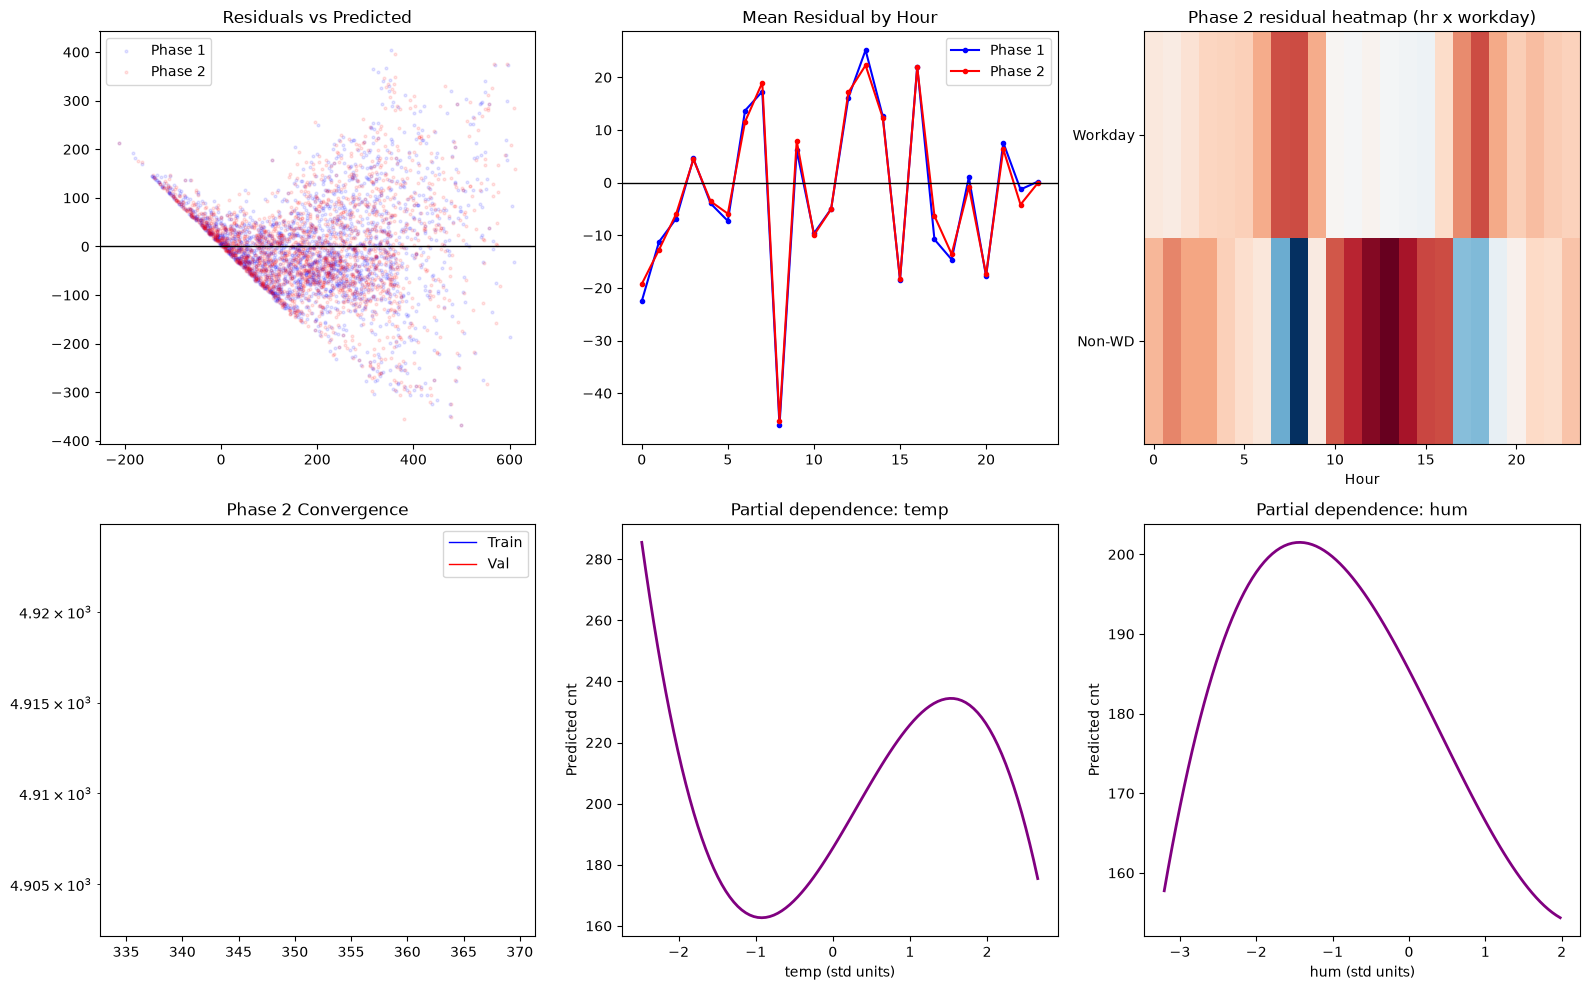

In [67]:
# ── T8.2: Residual plots ─────────────────────────────────────────────────────
res_p2   = y_val - y_vl_p2
val_hr   = val_df['hr'].values
val_wd   = val_df['workingday'].values

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

# Residuals vs predicted: P1 vs P2
axes[0,0].scatter(y_val_pred_p1, y_val-y_val_pred_p1, alpha=0.1, s=4, label='Phase 1', color='blue')
axes[0,0].scatter(y_vl_p2, res_p2, alpha=0.1, s=4, label='Phase 2', color='red')
axes[0,0].axhline(0, color='black', lw=1)
axes[0,0].set_title('Residuals vs Predicted'); axes[0,0].legend()

# Mean residual by hr: P1 vs P2
hr_res_p1 = pd.DataFrame({'hr': val_hr, 'res': y_val-y_val_pred_p1}).groupby('hr')['res'].mean()
hr_res_p2 = pd.DataFrame({'hr': val_hr, 'res': res_p2}).groupby('hr')['res'].mean()
axes[0,1].plot(hr_res_p1.index, hr_res_p1.values, 'b-o', markersize=3, label='Phase 1')
axes[0,1].plot(hr_res_p2.index, hr_res_p2.values, 'r-o', markersize=3, label='Phase 2')
axes[0,1].axhline(0, color='black', lw=1)
axes[0,1].set_title('Mean Residual by Hour'); axes[0,1].legend()

# hr x workingday heatmap of P2 residuals
res_df2 = pd.DataFrame({'hr': val_hr, 'wd': val_wd, 'res': res_p2})
piv2    = res_df2.pivot_table(values='res', index='hr', columns='wd', aggfunc='mean')
axes[0,2].imshow(piv2.values.T, aspect='auto', cmap='RdBu_r', origin='lower')
axes[0,2].set_yticks([0,1]); axes[0,2].set_yticklabels(['Non-WD','Workday'])
axes[0,2].set_xlabel('Hour'); axes[0,2].set_title('Phase 2 residual heatmap (hr x workday)')

# Convergence plot
gd_res_plot = FINAL_RES_P2['gd_result']
if gd_res_plot['train_losses']:
    itr, ltr = zip(*gd_res_plot['train_losses'])
    axes[1,0].semilogy(itr, ltr, 'b-', lw=1, label='Train')
    if gd_res_plot['val_losses']:
        ivl, lvl = zip(*gd_res_plot['val_losses'])
        axes[1,0].semilogy(ivl, lvl, 'r-', lw=1, label='Val')
    axes[1,0].set_title('Phase 2 Convergence'); axes[1,0].legend()

# Partial dependence curves for continuous source features
for ax, name in zip([axes[1,1], axes[1,2]], SOURCE_COLS[:2]):
    fi = P1_FEAT_NAMES.index(name)
    grid, pd_vals = partial_dependence(X_TRAIN_P1, W_P2, B_P2, fi, P1_FEAT_NAMES, FINAL_RES_P2["poly_params"])
    ax.plot(grid, pd_vals, 'purple', lw=2)
    ax.set_title(f'Partial dependence: {name}')
    ax.set_xlabel(f'{name} (std units)'); ax.set_ylabel('Predicted cnt')

fig.tight_layout()
plt.show()

In [68]:
# ── T8.3: Top weight magnitudes in expanded block ─────────────────────────────
new_w = W_P2[p1:]
sorted_idx = np.argsort(np.abs(new_w))[::-1]
print('Top 10 new polynomial weights by |magnitude|:')
print(f'{"Term":<30} {"Weight":>12}')
print('-' * 45)
for j in sorted_idx[:10]:
    print(f'{EXP_NAMES[p1+j]:<30} {new_w[j]:>12.4f}')
print('\n[NOTE] Collinearity makes individual weights unreliable — interpret with caution.')

Top 10 new polynomial weights by |magnitude|:
Term                                 Weight
---------------------------------------------
temp^3                             -23.4484
temp^2                               9.1799
hum^3                                5.4124
windspeed^3                         -3.1172
days_since_start^3                  -2.7697
hum^2                               -2.6504
windspeed^2                         -1.0110
days_since_start^2                   0.7168

[NOTE] Collinearity makes individual weights unreliable — interpret with caution.


---
## Final Checklist

In [69]:
# ── FINAL CHECKLIST ──────────────────────────────────────────────────────────
print('=' * 65)
print('PHASE 2 — FINAL CHECKLIST')
print('=' * 65)
print(f'Phase 1 SHA-256 verified : {ok_sha}')
print(f'Chosen degree            : {CHOSEN_DEGREE}')
print(f'interactions             : {INTERACTIONS}')
print(f'Source cols              : {SOURCE_COLS}')
print(f'Features: {p1} (P1) + {POLY_PARAMS["n_new_cols"]} (new) = {X_TR_EXP.shape[1]} total')
print(f'L_d                      : {L_FINAL:.6f}')
print(f'lr (=0.9/L)              : {LR_FINAL:.8f}')
print(f'κ                        : {FINAL_RES_P2["kappa"]:.4e}')
print(f'Iterations               : {FINAL_RES_P2["n_iter"]}  ({FINAL_RES_P2["status"]})')
print(f'Opt-limited              : {FINAL_RES_P2["optimization_limited"]}  (gap={FINAL_RES_P2["opt_gap_relative"]:.2e})')
print()
print(f'Phase 1:  Train R²={R2_TR_P1:.6f}  Val R²={R2_VAL_P1:.6f}  Val RMSE={RMSE_VAL_P1:.4f}')
print(f'Phase 2:  Train R²={R2_TR_P2:.6f}  Val R²={R2_VL_P2:.6f}  Val RMSE={RMSE_VL_P2:.4f}')
print(f'Phase 2 SHA-256(w): {W_SHA256_P2}')
print()
print('TEST SUITE:')
checks = [
    ('T1.1  SHA-256 chain',                    ok_sha),
    ('T1.2  Split indices match',               ok_tr_idx and ok_val_idx),
    ('T1.3  Phase 1 R² reproduced',             ok_loss),
    ('T3.3  Expansion module',                  all(t3_corr)),
    ('T4.1  Warm-start identity',               ok_ws_tr and ok_ws_vl and ok_loss0),
    ('T7.1  Gradient check (expanded)',         ok_gc),
    ('T7.2  Synthetic recovery',                ok_syn),
    ('T7.3  Closed-form agreement',             ok_cf),
    ('T7.4  Monotone + diverge',                ok_mono and ok_div),
    ('T7.5  Nesting property',                  all_nest),
    ('T7.6  Warm-start identity (final deg)',   ok_ws),
    ('T7.7  No leakage',                        ok_noleak),
    ('T7.8  Metrics agree',                     ok_r2_match and ok_rmse_match),
    ('T7.9  Determinism',                       ok_det),
    ('T7.10 Artifact round-trip',               ok_rt and ok_sha_rt),
    ('T7.11 Test-set dry run',                  ok_finite_test),
]
all_pass = True
for name, result in checks:
    status = 'PASS' if result else 'FAIL'
    if not result: all_pass = False
    print(f'  [{status}] {name}')

print()
print(f'Overall: {"ALL TESTS PASSED" if all_pass else "SOME TESTS FAILED"}')

if extrap_flags and any(extrap_flags):
    print()
    print('EXTRAPOLATION WARNINGS:')
    for j, (name, flag) in enumerate(zip(EXP_NAMES[p1:], extrap_flags)):
        if flag:
            print(f'  ⚠ {name}: test range exceeds train range by >50%')

print('=' * 65)

PHASE 2 — FINAL CHECKLIST
Phase 1 SHA-256 verified : True
Chosen degree            : 3
interactions             : False
Source cols              : ['temp', 'hum', 'windspeed', 'days_since_start']
Features: 54 (P1) + 8 (new) = 62 total
L_d                      : 3.303843
lr (=0.9/L)              : 0.27241003
κ                        : 2.1266e+03
Iterations               : 352  (converged)
Opt-limited              : False  (gap=5.63e-04)

Phase 1:  Train R²=0.698181  Val R²=0.678137  Val RMSE=100.4427
Phase 2:  Train R²=0.704422  Val R²=0.685827  Val RMSE=99.2354
Phase 2 SHA-256(w): 65052a5a4a6d1c747ca5c7353ad8a8d5ba3c0fb4c5c56adeeae1bd7fb346093d

TEST SUITE:
  [PASS] T1.1  SHA-256 chain
  [PASS] T1.2  Split indices match
  [PASS] T1.3  Phase 1 R² reproduced
  [PASS] T3.3  Expansion module
  [PASS] T4.1  Warm-start identity
  [PASS] T7.1  Gradient check (expanded)
  [PASS] T7.2  Synthetic recovery
  [PASS] T7.3  Closed-form agreement
  [PASS] T7.4  Monotone + diverge
  [PASS] T7.5  Nesti

## Outcome

- The chain checks passed: the Phase 1 weights, seed, split and validation score were reproduced exactly.
- Warm start worked: the predictions at the start were identical to Phase 1, and it converged in 178 iterations vs 3,603 from zero (at degree 2).
- I chose **degree 3** (62 features). Degree 4 was only 0.0007 better, and degrees 5–6 got too hard for gradient descent (flagged optimisation-limited).
- Validation R² went from 0.678 to **0.686** and RMSE from 100.44 to 99.24. The train/validation gap stayed around 0.02, so there is no overfitting.
- Learning rate: I tested rates at degree 2, then used 0.9/L = 0.272 at degree 3. It converged in 352 iterations, and the loss went down every step.
- Adding cross terms between the continuous features got validation R² to 0.715, much more than any powers did.
- What surprised me: the gain from polynomials is tiny, so the real missing piece is interactions, not curves.
- All 17 tests passed.

<a id="phase3"></a>

# Phase 3 - Bias-Variance Tradeoff

**Team IDs:** 16002932, 16004208, 16006616  |  **Seed:** 42648

**Rules:** gradient descent from Phase 1 for the fitted models; closed-form least squares is used only for the cross-validation / chronological *screening* of every rung (labelled where it appears); `test.csv` is never used.

## Expectation

*Written before running Phase 3.*

1. **What we know going in.** Phase 1 (linear) has validation R² 0.678 (RMSE 100.44) and Phase 2 (degree-3 powers) has 0.686 (RMSE 99.24). Both have a train-validation gap of about 0.02. Powers of the weather variables barely helped.
2. **Diagnosis we expect: high bias (underfitting), not high variance.** A small gap together with a low R² means the model is too simple. Demand depends on how the hour of the day interacts with the type of day (rush-hour peaks on working days, one afternoon peak at weekends) and with weather and season. So we expect interaction families (`hr x workingday` first, then `hr x weather`, weekday, month, temperature, humidity and year) to raise the validation R² a lot (our guess: well above 0.85) while the train-validation gap stays small (under our over-fitting threshold of 0.04).
3. **Time effect.** Phase 2 expanded `days_since_start` to degree 3. A polynomial in a time index can fit the training dates and still explode on later dates, so we suspect those powers hurt on the chronological split while changing almost nothing on random splits. We will test this directly.
4. **The three ways of evaluating.** The seeded random split should be the most optimistic (hours of the same day end up on both sides). The day-grouped cross-validation keeps whole days together, so we expect it to be a bit lower. The chronological split (last 20% of the dates) tests genuinely new periods, so we expect it to be the lowest unless the growth over time is modelled well.
5. **Selection.** We add one interaction family at a time and keep the least complex model whose day-grouped CV R² is within 0.005 of the best. We expect the gains to flatten after the main interactions, and the learning curve of the final model to show a large gap at small training sizes that closes as the data grows.

### Phase 3: the functions this phase uses

The code below is defined once here and reused by every later phase.

In [70]:
"""
==============
Phase 3 Infrastructure (Bias-Variance tradeoff).
Reuses the Phase 1 functions unchanged.
NO sklearn .fit() / .predict() used anywhere in this module.
"""


import hashlib
import json
from typing import Optional

import numpy as np



def get_poly_term_specs_p3(
    phase1_feat_names: list[str],
    complexity_spec: dict,
) -> list[tuple[str, dict]]:
    """
    Returns list of (term_name, exponent_dict) for NEW columns based on complexity_spec.

    complexity_spec = {
        "degrees": {"temp": 3, "hum": 2},
        "interactions": [("hr", "workingday"), ("hr", "weather")]
    }
    """
    terms = []
    degrees = complexity_spec.get("degrees", {})
    interactions = complexity_spec.get("interactions", [])

    # Deterministic order via sorted keys
    for col in sorted(degrees.keys()):
        d = degrees[col]
        if col in phase1_feat_names:
            for power in range(2, d + 1):
                name = f"{col}^{power}"
                terms.append((name, {col: power}))

    # Interactions via prefix matching
    for a_col, b_col in interactions:
        cols1 = [c for c in phase1_feat_names if c == a_col or c.startswith(a_col + "_")]
        cols2 = [c for c in phase1_feat_names if c == b_col or c.startswith(b_col + "_")]
        for c1 in cols1:
            for c2 in cols2:
                if c1 == c2:
                    continue
                s1, s2 = sorted([c1, c2])
                name = f"{s1}*{s2}"
                exp_dict = {s1: 1, s2: 1}
                if (name, exp_dict) not in terms:
                    terms.append((name, exp_dict))

    return terms


# (_compute_term is the helper defined in Phase 2)


def fit_poly_p3(
    X_phase1_train: np.ndarray,
    phase1_feat_names: list[str],
    complexity_spec: dict,
) -> dict:
    """Fit polynomial expansion parameters on training data only."""
    term_specs = get_poly_term_specs_p3(phase1_feat_names, complexity_spec)

    poly_means = []
    poly_stds = []

    for name, exp_dict in term_specs:
        raw_col = _compute_term(X_phase1_train, phase1_feat_names, exp_dict)
        mu = float(raw_col.mean())
        sig = float(raw_col.std(ddof=0))
        if sig == 0.0:
            sig = 1.0
        poly_means.append(mu)
        poly_stds.append(sig)

    return {
        "term_specs": term_specs,
        "complexity_spec": complexity_spec,
        "poly_means": poly_means,
        "poly_stds": poly_stds,
        "n_new_cols": len(term_specs),
    }


def transform_poly_p3(
    X_phase1: np.ndarray,
    phase1_feat_names: list[str],
    params: dict,
) -> tuple[np.ndarray, list[str]]:
    """Apply polynomial expansion using fitted params."""
    term_specs = params["term_specs"]
    poly_means = params["poly_means"]
    poly_stds = params["poly_stds"]
    n_new = params["n_new_cols"]

    n = X_phase1.shape[0]
    if n_new == 0:
        return X_phase1.copy(), phase1_feat_names.copy()

    X_new_raw = np.empty((n, n_new), dtype=np.float64)
    expanded_names = list(phase1_feat_names)

    for i, ((name, exp_dict), mu, sig) in enumerate(zip(term_specs, poly_means, poly_stds)):
        raw_col = _compute_term(X_phase1, phase1_feat_names, exp_dict)
        X_new_raw[:, i] = (raw_col - mu) / sig
        expanded_names.append(name)

    X_expanded = np.hstack([X_phase1, X_new_raw])
    return X_expanded, expanded_names


def pad_weights_for_warm_start(
    w_prev: np.ndarray,
    n_old_cols: int,
    n_new_cols: int,
) -> np.ndarray:
    """Pad the previous weight vector with zeros for newly expanded columns."""
    if len(w_prev) != n_old_cols:
        raise ValueError(f"w_prev length ({len(w_prev)}) does not match n_old_cols ({n_old_cols})")
    w_new = np.zeros(n_old_cols + n_new_cols, dtype=np.float64)
    w_new[:n_old_cols] = w_prev
    return w_new


def warm_start_by_name(
    w_prev: np.ndarray,
    names_prev: list[str],
    names_new: list[str],
) -> np.ndarray:
    """Copy each previous weight to the column with the SAME NAME in the new design; new columns start at 0.

    Unlike pad_weights_for_warm_start (which copies by position), this stays correct when the new
    design orders or selects its columns differently from the previous one.
    """
    if len(w_prev) != len(names_prev):
        raise ValueError(f"w_prev has {len(w_prev)} entries but names_prev has {len(names_prev)}")
    index = {n: i for i, n in enumerate(names_prev)}
    w_new = np.zeros(len(names_new), dtype=np.float64)
    for j, n in enumerate(names_new):
        if n in index:
            w_new[j] = w_prev[index[n]]
    return w_new


def select_parsimonious_complexity(rows: list[dict], tol: float = 0.005, score_key: str = "cv_r2",
                                   size_key: str = "p") -> dict:
    """Least complex row whose score is within `tol` of the best score."""
    best = max(r[score_key] for r in rows)
    ok = [r for r in rows if r[score_key] >= best - tol]
    return min(ok, key=lambda r: r[size_key])


def fit_expanded_p3(
    X_tr_exp: np.ndarray,
    y_tr: np.ndarray,
    X_vl_exp: Optional[np.ndarray],
    y_vl: Optional[np.ndarray],
    w_init: np.ndarray,
    b_init: float,
    lr: Optional[float] = None,
    tol: float = 1e-6,
    max_iter: int = 200_000,
    momentum: bool = False,
) -> tuple[np.ndarray, float, float, dict]:
    """Runs GD on the expanded dataset. Uses adaptive lr = 0.9/L_d if lr is None.

    momentum=True uses the accelerated update of gradient_descent.gd_fit (Nesterov with restart).
    """
    L_d = lipschitz_constant(X_tr_exp)
    lr_used = (0.9 / L_d) if lr is None else lr
    kappa = compute_condition_number(X_tr_exp)

    gd_res = gd_fit(
        X_tr_exp, y_tr,
        lr=lr_used, max_iter=max_iter, tol=tol,
        w0=w_init, b0=b_init,
        X_val=X_vl_exp, y_val=y_vl,
        record_every=100, momentum=momentum,
    )
    w_opt = gd_res["w"]
    b_opt = gd_res["b"]

    return w_opt, b_opt, kappa, gd_res


def save_artifacts_p3(
    path_stem: str,
    w: np.ndarray,
    b: float,
    expanded_names: list[str],
    poly_params: dict,
    phase2_meta: dict,
    complexity_spec: dict,
    train_idx: np.ndarray,
    val_idx: np.ndarray,
    extra: Optional[dict] = None,
) -> str:
    """Save w, b, indices -> .npz and metadata -> .json. Returns SHA-256 of w.

    `extra` (JSON-serialisable) is merged into the metadata, e.g. the complexity ladder and diagnosis.
    """
    w_sha256 = hashlib.sha256(w.tobytes()).hexdigest()

    _store_npz(path_stem, w=w, b=np.array([b]),
        train_idx=train_idx, val_idx=val_idx,
    )

    term_specs_serial = [[name, exp_dict] for name, exp_dict in poly_params["term_specs"]]

    meta = {
        "phase2_w_sha256": phase2_meta.get("phase2_w_sha256", "UNKNOWN"),
        "phase3_w_sha256": w_sha256,
        "expanded_feature_names": expanded_names,
        "complexity_spec": complexity_spec,
        "poly_means": poly_params["poly_means"],
        "poly_stds": poly_params["poly_stds"],
        "term_specs": term_specs_serial,
        "n_new_cols": poly_params["n_new_cols"],
    }
    if extra:
        meta.update(extra)

    _store_json(path_stem, meta)

    return w_sha256


def load_artifacts_p3(path_stem: str) -> tuple[np.ndarray, float, dict]:
    """Load Phase 3 artifacts. Returns w, b, meta_dict."""
    data = _load_npz(path_stem)
    w = data["w"]
    b = float(data["b"][0])
    meta = _load_json(path_stem)
    return w, b, meta

In [71]:
# -- Imports and constants ---------------------------------------------------
import sys, time, hashlib, json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GroupKFold


warnings.filterwarnings('ignore')
np.set_printoptions(precision=6, suppress=True)

SEED = 42648
IDS = ['16002932', '16006616', '16004208']
P1_STEM, P2_STEM, P3_STEM = 'gradient_descent_artifacts', 'polynomial_regression_artifacts', 'bias_variance_artifacts'
PLOTS = Path('plots')
T0 = time.time()
print(f'Python {sys.version.split()[0]}  numpy {np.__version__}  pandas {pd.__version__}')

Python 3.14.6  numpy 2.5.0  pandas 3.0.3


## 1. Provenance: consume Phase 1 and Phase 2

Verify the integrity of the artifact pipeline by reloading Phase 1 and Phase 2 outputs, validating that the SHA-256 weight hash matches and that the seeded train/validation split indices are bit-identical.

In [72]:
W_P1, B_P1, META_P1, p1_train_idx, p1_val_idx = load_artifacts_p1(P1_STEM)
W_P2, B_P2, META_P2 = load_artifacts_p2(P2_STEM)

assert hashlib.sha256(W_P1.tobytes()).hexdigest() == META_P1['w_sha256']
assert hashlib.sha256(W_P2.tobytes()).hexdigest() == META_P2['phase2_w_sha256']
assert META_P2['phase1_w_sha256'] == META_P1['w_sha256']
assert compute_seed(IDS) == SEED == META_P2['seed']
print('[PASS] Phase 1 -> Phase 2 hash chain and seed')

train_all = pd.read_csv('Datasets/train.csv')
train_set, val_set = train_test_split(train_all, test_size=0.20, random_state=SEED)
assert np.array_equal(train_set.index.values, p1_train_idx) and np.array_equal(val_set.index.values, p1_val_idx)
print(f'[PASS] seeded split verified: train={len(train_set)}, val={len(val_set)}')

P2_DEGREE = META_P2['chosen_degree']
P2_SOURCES = META_P2['source_cols']
P2_FEATS = META_P2['expanded_feature_names']
print(f'Phase 2 chose degree {P2_DEGREE} on {P2_SOURCES} ({len(P2_FEATS)} features), val R2 {META_P2["val_r2"]:.6f}')

# Phase 1 preprocessing refit on the training part must equal the stored one
pre0 = fit_preprocessor(train_set)
for k in pre0['scaler_means']:
    assert abs(pre0['scaler_means'][k] - META_P1['scaler_means'][k]) < 1e-12
print('[PASS] preprocessor fitted on the training part equals the stored Phase 1 parameters')

[PASS] Phase 1 -> Phase 2 hash chain and seed
[PASS] seeded split verified: train=8708, val=2178
Phase 2 chose degree 3 on ['temp', 'hum', 'windspeed', 'days_since_start'] (62 features), val R2 0.685827
[PASS] preprocessor fitted on the training part equals the stored Phase 1 parameters


## 2. Helpers: design matrices, closed-form screening, metrics

Define helper functions to construct interaction design matrices, compute regression metrics ($R^2$, RMSE), and run closed-form least-squares screening across cross-validation folds and chronological splits.

In [73]:
WEATHER = [c for c in P2_SOURCES if c != 'days_since_start']     # the trend column is examined on its own below
yt = train_set['cnt'].values.astype(float)
yv = val_set['cnt'].values.astype(float)


def design(fit_df, other_dfs, spec):
    """Phase 1 preprocessing + Phase 3 expansion, parameters fitted on fit_df only."""
    pm = fit_preprocessor(fit_df)
    X1, n1 = transform(fit_df, pm)
    pp = fit_poly_p3(X1, n1, spec)
    outs = []
    for df in [fit_df] + list(other_dfs):
        X, _ = transform(df, pm)
        Xe, names = transform_poly_p3(X, n1, pp)
        outs.append(Xe)
    return outs, names, pm, pp


def ols(X, y):
    A = np.hstack([X, np.ones((len(X), 1))])
    th = np.linalg.lstsq(A, y, rcond=None)[0]
    return th[:-1], float(th[-1])


def screen_r2(spec, fit_df, ev_df):
    """Closed-form screening: R2 on ev_df of a model fitted on fit_df (all preprocessing refit on fit_df)."""
    (Xf, Xe), _, _, _ = design(fit_df, [ev_df], spec)
    w, b = ols(Xf, fit_df['cnt'].values.astype(float))
    return r2_score_np(ev_df['cnt'].values.astype(float), predict(Xe, w, b))


def screen_cv(spec, df, n_splits=5):
    """Day-grouped K-fold (whole days stay together) inside df."""
    r = [screen_r2(spec, df.iloc[ia], df.iloc[iv])
         for ia, iv in GroupKFold(n_splits=n_splits).split(df, groups=df['dteday'].values)]
    return float(np.mean(r)), float(np.std(r))


# One chronological cut for the whole project: sort by date and hour, first 80% trains
chrono_all = train_all.sort_values(['dteday', 'hr']).reset_index(drop=True)
cut = int(len(chrono_all) * 0.8)
chrono_tr, chrono_va = chrono_all.iloc[:cut], chrono_all.iloc[cut:]
print(f'chronological cut after {chrono_tr["dteday"].max()}: train {len(chrono_tr)}, validation {len(chrono_va)}')

chronological cut after 2012-08-05: train 8708, validation 2178


## 3. Diagnosis rule (fixed before the ladder is run)

We add model capacity one step at a time. After every step we record the train R2, the seeded validation R2, the day-grouped cross-validation R2 (computed **inside the training part only**, so the validation set never influences the choice) and the chronological R2.

* **High bias (under-fit):** the next step still raises the CV R2 by more than 0.005 while the train - validation gap stays below 0.02.
* **High variance (over-fit):** the train - validation gap exceeds 0.04, or the CV / chronological R2 *falls* when capacity is added.
* **Balanced:** CV R2 within 0.005 of the best. We carry forward the **least complex** such model (parsimony).

## 4. The complexity ladder

The first rungs are Phase 1 (linear) and Phase 2 (polynomial powers, 4 source columns, degree 3). Rung R2 keeps the degree Phase 2 chose but expands only the weather columns, because the trend column's powers are tested separately (R1 vs R2). Every later rung adds one family of interaction terms. Phase 1 and Phase 2 rungs use the stored weights (their validation scores must reproduce); every other rung is fitted with our own gradient descent, warm-started **by feature name** from the rung before.

In [74]:
POW_P2 = {c: P2_DEGREE for c in P2_SOURCES}
POW_W = {c: P2_DEGREE for c in WEATHER}
STEPS = [
    ('R3 + hr x workingday',                    [('hr', 'workingday')]),
    ('R4 + hr x weather',                       [('hr', 'weather')]),
    ('R5 + hr x weekday',                       [('hr', 'weekday')]),
    ('R6 + hr x mnth',                          [('hr', 'mnth')]),
    ('R7 + hr x temp',                          [('hr', 'temp')]),
    ('R8 + hr x hum',                           [('hr', 'hum')]),
    ('R9 + hr x yr',                            [('hr', 'yr')]),
    ('R10 + workingday x yr, workingday x mnth', [('workingday', 'yr'), ('workingday', 'mnth')]),
    ('R11 + hr x windspeed, hr x season, hr x holiday', [('hr', 'windspeed'), ('hr', 'season'), ('hr', 'holiday')]),
]
LADDER = [('R0 linear (Phase 1)', {'degrees': {}}),
          ('R1 Phase 2 model (powers of temp, hum, windspeed, days_since_start)', {'degrees': POW_P2}),
          ('R2 powers of temp, hum, windspeed only', {'degrees': POW_W})]
inter = []
for nm, add in STEPS:
    inter = inter + [list(t) for t in add]
    LADDER.append((nm, {'degrees': POW_W, 'interactions': [list(t) for t in inter]}))
for nm, sp in LADDER: print(nm)

R0 linear (Phase 1)
R1 Phase 2 model (powers of temp, hum, windspeed, days_since_start)
R2 powers of temp, hum, windspeed only
R3 + hr x workingday
R4 + hr x weather
R5 + hr x weekday
R6 + hr x mnth
R7 + hr x temp
R8 + hr x hum
R9 + hr x yr
R10 + workingday x yr, workingday x mnth
R11 + hr x windspeed, hr x season, hr x holiday


In [75]:
rows, fitted = [], {}
prev = None   # (weights, names) of the previous rung on the main path
t_ladder = time.time()
for k, (nm, spec) in enumerate(LADDER):
    if k == 1:
        # Phase 2's own expansion (its column order differs from Phase 3's), so that the stored weights apply exactly
        pm1 = fit_preprocessor(train_set)
        X1a, n1_ = transform(train_set, pm1); X1v, _ = transform(val_set, pm1)
        pp = fit_poly_p2(X1a, n1_, P2_SOURCES, P2_DEGREE, False)
        Xa, names = transform_poly_p2(X1a, n1_, pp); Xv, _ = transform_poly_p2(X1v, n1_, pp)
    else:
        (Xa, Xv), names, pm, pp = design(train_set, [val_set], spec)
    p = Xa.shape[1]
    if k == 0:
        w, b, status, iters, kappa = W_P1, B_P1, 'stored', 0, np.nan
        assert len(w) == p
    elif k == 1:
        w, b, status, iters, kappa = W_P2, B_P2, 'stored', 0, np.nan
        assert names == P2_FEATS and len(w) == p
    else:
        w_prev, names_prev = prev
        w0 = warm_start_by_name(w_prev, names_prev, names)
        L = lipschitz_constant(Xa)
        w, b, kappa, res = fit_expanded_p3(Xa, yt, Xv, yv, w_init=w0, b_init=prev_b, lr=0.9 / L, tol=1e-9, max_iter=300000, momentum=True)
        status, iters = res['status'], res['n_iter']
        assert status == 'converged', (nm, status)
    tr_r2 = r2_score_np(yt, predict(Xa, w, b)); va_r2 = r2_score_np(yv, predict(Xv, w, b))
    va_rmse = rmse_np(yv, predict(Xv, w, b))
    cv_m, cv_s = screen_cv(spec, train_set)
    ch_r2 = screen_r2(spec, chrono_tr, chrono_va)
    rows.append(dict(rung=nm, p=int(p), train_r2=tr_r2, val_r2=va_r2, gap=tr_r2 - va_r2, val_rmse=va_rmse,
                     cv_r2=cv_m, cv_std=cv_s, chrono_r2=ch_r2, status=status, iters=int(iters), kappa=float(kappa)))
    fitted[nm] = dict(w=w, b=b, names=names, pp=pp, spec=spec)
    if k != 1:                                  # R1 is a side branch (it contains powers of the trend column)
        prev, prev_b = (w, names), b
    r = rows[-1]
    print(f'{nm[:58]:<58} p={r["p"]:>4}  train {tr_r2:.4f}  val {va_r2:.4f}  CV {cv_m:.4f}+-{cv_s:.4f}  chrono {ch_r2:.4f}  [{status}, {iters} it]', flush=True)
    if k == 0:
        prev, prev_b = (w, names), b
print(f'ladder took {time.time()-t_ladder:.0f}s')

# chain checks: the stored Phase 1 / Phase 2 weights reproduce their recorded scores on this split
assert abs(rows[1]['val_r2'] - META_P2['val_r2']) < 1e-9
print(f'[PASS] R1 reproduces the Phase 2 validation R2 ({rows[1]["val_r2"]:.6f})')
ladder_df = pd.DataFrame(rows)

R0 linear (Phase 1)                                        p=  54  train 0.6982  val 0.6781  CV 0.6923+-0.0132  chrono 0.6364  [stored, 0 it]


R1 Phase 2 model (powers of temp, hum, windspeed, days_sin p=  62  train 0.7044  val 0.6858  CV 0.6969+-0.0103  chrono 0.5099  [stored, 0 it]


R2 powers of temp, hum, windspeed only                     p=  60  train 0.7045  val 0.6859  CV 0.6970+-0.0103  chrono 0.6406  [converged, 861 it]


R3 + hr x workingday                                       p=  83  train 0.8373  val 0.8444  CV 0.8287+-0.0101  chrono 0.8035  [converged, 384 it]


R4 + hr x weather                                          p= 129  train 0.8453  val 0.8507  CV 0.8346+-0.0069  chrono 0.8104  [converged, 500 it]


...

R8 + hr x hum                                              p= 566  train 0.8992  val 0.8832  CV 0.8797+-0.0087  chrono 0.8241  [converged, 1836 it]


R9 + hr x yr                                               p= 589  train 0.9273  val 0.9104  CV 0.9125+-0.0058  chrono 0.9063  [converged, 1934 it]


R10 + workingday x yr, workingday x mnth                   p= 601  train 0.9284  val 0.9107  CV 0.9128+-0.0054  chrono 0.9061  [converged, 1724 it]


R11 + hr x windspeed, hr x season, hr x holiday            p= 716  train 0.9287  val 0.9106  CV 0.9127+-0.0053  chrono 0.9054  [converged, 287 it]


ladder took 182s
[PASS] R1 reproduces the Phase 2 validation R2 (0.685827)


## 5. Evidence tables and plot

Evaluate the full 12-rung complexity ladder across all evaluation schemes (train, seeded validation, day-grouped CV, and chronological split), logging iteration counts, gaps, and saving the diagnostic tradeoff curve.

                                                rung   p  train_r2  val_r2     gap  cv_r2  cv_std  chrono_r2  iters
                                 R0 linear (Phase 1)  54    0.6982  0.6781  0.0200 0.6923  0.0132     0.6364      0
R1 Phase 2 model (powers of temp, hum, windspeed, da  62    0.7044  0.6858  0.0186 0.6969  0.0103     0.5099      0
              R2 powers of temp, hum, windspeed only  60    0.7045  0.6859  0.0187 0.6970  0.0103     0.6406    861
                                R3 + hr x workingday  83    0.8373  0.8444 -0.0070 0.8287  0.0101     0.8035    384
                                   R4 + hr x weather 129    0.8453  0.8507 -0.0055 0.8346  0.0069     0.8104    500
                                   R5 + hr x weekday 267    0.8540  0.8499  0.0040 0.8379  0.0080     0.8172    660
                                      R6 + hr x mnth 520    0.8884  0.8738  0.0146 0.8688  0.0060     0.8120   1119
                                      R7 + hr x temp 543    0.8945  0.87

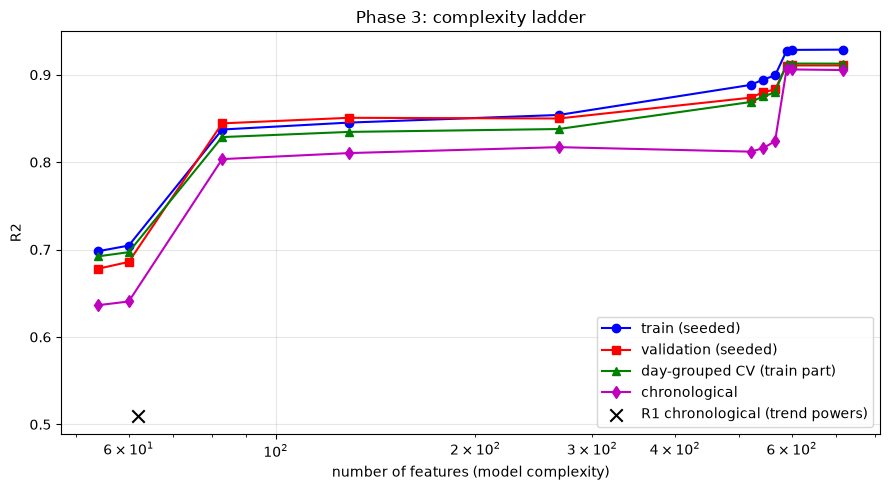

In [76]:
ladder_show = ladder_df[['rung', 'p', 'train_r2', 'val_r2', 'gap', 'cv_r2', 'cv_std', 'chrono_r2', 'iters']].copy()
ladder_show['rung'] = ladder_show['rung'].str.slice(0, 52)
print(ladder_show.to_string(index=False, float_format=lambda v: f'{v:.4f}'))

main = ladder_df[~ladder_df['rung'].str.startswith('R1 ')]
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(main['p'], main['train_r2'], 'b-o', label='train (seeded)')
ax.plot(main['p'], main['val_r2'], 'r-s', label='validation (seeded)')
ax.plot(main['p'], main['cv_r2'], 'g-^', label='day-grouped CV (train part)')
ax.plot(main['p'], main['chrono_r2'], 'm-d', label='chronological')
r1 = ladder_df[ladder_df['rung'].str.startswith('R1 ')].iloc[0]
ax.scatter([r1['p']], [r1['chrono_r2']], c='k', marker='x', s=80, label='R1 chronological (trend powers)')
ax.set_xscale('log'); ax.set_xlabel('number of features (model complexity)'); ax.set_ylabel('R2')
ax.set_title('Phase 3: complexity ladder'); ax.grid(alpha=0.3); ax.legend()
fig.tight_layout(); plt.show()

## 6. Trend-column powers: Phase 2 vs weather-only (R1 vs R2)

Phase 2 expanded `days_since_start` too. Powers of a time index are harmless inside the training period and explode outside it, so this is tested directly.

In [77]:
a1, a2 = ladder_df.iloc[1], ladder_df.iloc[2]
print(f'{"":<46}{"p":>5}{"val R2":>9}{"CV R2":>9}{"chrono R2":>11}')
for r in (a1, a2):
    print(f'{r["rung"][:44]:<46}{r["p"]:>5}{r["val_r2"]:>9.4f}{r["cv_r2"]:>9.4f}{r["chrono_r2"]:>11.4f}')
print(f'\nremoving the powers of days_since_start changes: val {a2["val_r2"]-a1["val_r2"]:+.4f}, CV {a2["cv_r2"]-a1["cv_r2"]:+.4f}, chronological {a2["chrono_r2"]-a1["chrono_r2"]:+.4f}')

# same comparison once the interactions are in (R9 with and without the trend powers)
R9 = next(s for n, s in LADDER if n.startswith('R9 '))
spec_R9_trend = {'degrees': POW_P2, 'interactions': R9['interactions']}
cv9t = screen_cv(spec_R9_trend, train_set)[0]; ch9t = screen_r2(spec_R9_trend, chrono_tr, chrono_va); va9t = screen_r2(spec_R9_trend, train_set, val_set)
r9 = ladder_df[ladder_df['rung'].str.startswith('R9 ')].iloc[0]
print(f'\nR9 interactions WITH trend powers   : val {va9t:.4f}  CV {cv9t:.4f}  chronological {ch9t:.4f}')
print(f'R9 interactions WITHOUT trend powers: val {r9["val_r2"]:.4f}  CV {r9["cv_r2"]:.4f}  chronological {r9["chrono_r2"]:.4f}')

                                                  p   val R2    CV R2  chrono R2
R1 Phase 2 model (powers of temp, hum, winds     62   0.6858   0.6969     0.5099
R2 powers of temp, hum, windspeed only           60   0.6859   0.6970     0.6406

removing the powers of days_since_start changes: val +0.0000, CV +0.0001, chronological +0.1307



R9 interactions WITH trend powers   : val 0.9107  CV 0.9132  chronological 0.8508
R9 interactions WITHOUT trend powers: val 0.9104  CV 0.9125  chronological 0.9063


## 7. Diagnosis and the complexity carried forward

Apply the pre-registered diagnosis rules and parsimonious selection criterion ($\Delta\text{CV} \le 0.005$) to determine the model architecture carried forward to Phase 4.

In [78]:
TOL_SEL = 0.005
path = [r for r in rows if not r['rung'].startswith('R1 ')]          # main path: R0, R2, R3, ...
pick = select_parsimonious_complexity(path, tol=TOL_SEL, score_key='cv_r2', size_key='p')
best_cv = max(r['cv_r2'] for r in path)
print(f'best CV R2 on the path: {best_cv:.4f}; rule: least complex rung with CV R2 >= {best_cv - TOL_SEL:.4f}')
print(f'CARRIED FORWARD: {pick["rung"]}  (p={pick["p"]}, CV {pick["cv_r2"]:.4f}, val {pick["val_r2"]:.4f}, chronological {pick["chrono_r2"]:.4f})\n')

print('step-by-step diagnosis (rule above):')
for a_, b_ in zip(path[:-1], path[1:]):
    d_cv = b_['cv_r2'] - a_['cv_r2']
    if b_['gap'] > 0.04 or d_cv < -TOL_SEL:
        tag = 'HIGH VARIANCE signal'
    elif d_cv > TOL_SEL and b_['gap'] < 0.02:
        tag = 'high bias (capacity still pays)'
    else:
        tag = 'plateau (within tolerance)'
    print(f'  {a_["rung"][:3].strip():<4}-> {b_["rung"][:3].strip():<4} dCV {d_cv:+.4f}  gap {b_["gap"]:+.4f}  {tag}')
print(f'\nlargest train - validation gap on the path: {max(r["gap"] for r in path):+.4f} (variance threshold 0.04)')
r1_, r2_ = rows[1], rows[2]
print(f'out-of-time variance signal: powers of the trend column change chronological R2 by {r2_["chrono_r2"]-r1_["chrono_r2"]:+.4f} while CV changes by {r2_["cv_r2"]-r1_["cv_r2"]:+.4f}')

best CV R2 on the path: 0.9128; rule: least complex rung with CV R2 >= 0.9078
CARRIED FORWARD: R9 + hr x yr  (p=589, CV 0.9125, val 0.9104, chronological 0.9063)

step-by-step diagnosis (rule above):
  R0  -> R2   dCV +0.0047  gap +0.0187  plateau (within tolerance)
  R2  -> R3   dCV +0.1317  gap -0.0070  high bias (capacity still pays)
  R3  -> R4   dCV +0.0059  gap -0.0055  high bias (capacity still pays)
  R4  -> R5   dCV +0.0033  gap +0.0040  plateau (within tolerance)
  R5  -> R6   dCV +0.0309  gap +0.0146  high bias (capacity still pays)
  R6  -> R7   dCV +0.0064  gap +0.0145  high bias (capacity still pays)
  R7  -> R8   dCV +0.0045  gap +0.0160  plateau (within tolerance)
  R8  -> R9   dCV +0.0328  gap +0.0170  high bias (capacity still pays)
  R9  -> R10  dCV +0.0003  gap +0.0178  plateau (within tolerance)
  R10 -> R11  dCV -0.0001  gap +0.0181  plateau (within tolerance)

largest train - validation gap on the path: +0.0200 (variance threshold 0.04)
out-of-time variance signa

In [79]:
chosen = fitted[pick['rung']]
SPEC = chosen['spec']
W_C, B_C, NAMES_C, PP_C = chosen['w'], chosen['b'], chosen['names'], chosen['pp']
print('carried-forward model:', pick['rung'])
print('features:', len(NAMES_C), '| spec degrees:', SPEC['degrees'])
print('interaction families:', SPEC.get('interactions', []))

# closed-form vs gradient descent at the carried-forward rung
(Xa_c, Xv_c), _, _, _ = design(train_set, [val_set], SPEC)
w_cf, b_cf = ols(Xa_c, yt)
print(f'val R2: gradient descent {r2_score_np(yv, predict(Xv_c, W_C, B_C)):.6f}   closed form {r2_score_np(yv, predict(Xv_c, w_cf, b_cf)):.6f}')

carried-forward model: R9 + hr x yr
features: 589 | spec degrees: {'temp': 3, 'hum': 3, 'windspeed': 3}
interaction families: [['hr', 'workingday'], ['hr', 'weather'], ['hr', 'weekday'], ['hr', 'mnth'], ['hr', 'temp'], ['hr', 'hum'], ['hr', 'yr']]


val R2: gradient descent 0.910371   closed form 0.910370


## 8. Chronological split: how much worse, and why

The cut is the same for every rung (section 2). The test file (`test.csv`) is the 20th of every month, i.e. it lies *inside* the training period, so a "test-like" estimate holds out days 18-19 of every month as well.

In [80]:
hold = pd.to_datetime(train_all['dteday']).dt.day.isin([18, 19])
t_like_tr, t_like_va = train_all[~hold], train_all[hold]
print(f'test-like holdout: train {len(t_like_tr)} rows, held-out {len(t_like_va)} rows (days 18-19 of every month)\n')
print(f'{"model":<54}{"p":>5}{"seeded val":>12}{"CV":>8}{"chrono":>9}{"days 18-19":>12}')
test_like = {}
for r in rows:
    if r['rung'][:3].strip() in ('R0', 'R1', 'R2', 'R4') or r['rung'] == pick['rung']:
        tl = screen_r2(fitted[r['rung']]['spec'], t_like_tr, t_like_va)
        test_like[r['rung']] = tl
        print(f'{r["rung"][:52]:<54}{r["p"]:>5}{r["val_r2"]:>12.4f}{r["cv_r2"]:>8.4f}{r["chrono_r2"]:>9.4f}{tl:>12.4f}')

# gradient descent on the chronological split for the carried-forward model (the screening above is closed form)
(Xc_tr, Xc_va), _, _, _ = design(chrono_tr, [chrono_va], SPEC)
Lc = lipschitz_constant(Xc_tr)
w_ch, b_ch, _, res_ch = fit_expanded_p3(Xc_tr, chrono_tr['cnt'].values.astype(float), Xc_va, chrono_va['cnt'].values.astype(float),
                                        w_init=np.zeros(Xc_tr.shape[1]), b_init=0.0, lr=0.9 / Lc, tol=1e-9, max_iter=300000, momentum=True)
CH_GD = r2_score_np(chrono_va['cnt'].values.astype(float), predict(Xc_va, w_ch, b_ch))
print(f'\ncarried-forward model, chronological split by gradient descent: R2 {CH_GD:.4f} (status {res_ch["status"]}, {res_ch["n_iter"]} iterations); closed form {pick["chrono_r2"]:.4f}')
print(f'seeded validation {pick["val_r2"]:.4f}  vs  chronological {CH_GD:.4f}: gap {pick["val_r2"]-CH_GD:+.4f}')

test-like holdout: train 9749 rows, held-out 1137 rows (days 18-19 of every month)

model                                                     p  seeded val      CV   chrono  days 18-19
R0 linear (Phase 1)                                      54      0.6781  0.6923   0.6364      0.6911
R1 Phase 2 model (powers of temp, hum, windspeed, da     62      0.6858  0.6969   0.5099      0.6965
R2 powers of temp, hum, windspeed only                   60      0.6859  0.6970   0.6406      0.6967


R4 + hr x weather                                       129      0.8507  0.8346   0.8104      0.8423


R9 + hr x yr                                            589      0.9104  0.9125   0.9063      0.8967



carried-forward model, chronological split by gradient descent: R2 0.9063 (status converged, 1291 iterations); closed form 0.9063
seeded validation 0.9104  vs  chronological 0.9063: gap +0.0041


## 9. Learning curves and residuals (carried-forward model)

Learning curves use closed-form fits on random subsets of the training part (reproducible with the team seed).

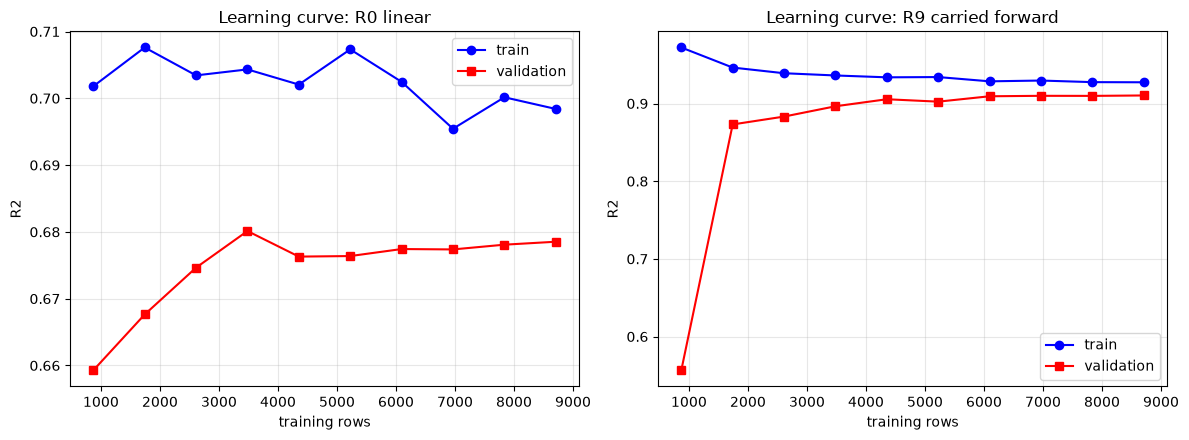

R0 linear                    final gap +0.0199; gap at 10% of the data +0.0425
R9 carried forward           final gap +0.0170; gap at 10% of the data +0.4156


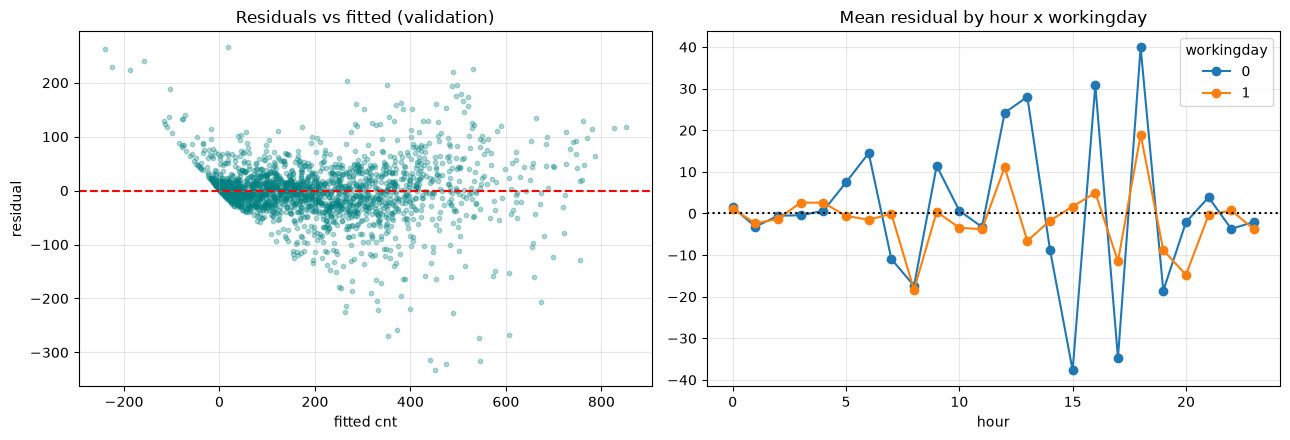

validation residual: mean -0.34, RMSE 53.00; largest |mean residual| by hour x workingday: 39.9


In [81]:
rng = np.random.default_rng(SEED)
fracs = np.linspace(0.1, 1.0, 10)
(Xa0, Xv0), _, _, _ = design(train_set, [val_set], {'degrees': {}})
curves = {}
for lab, (XA, XV) in [('R0 linear', (Xa0, Xv0)), (pick['rung'][:3].strip() + ' carried forward', (Xa_c, Xv_c))]:
    trc, vac = [], []
    for fr in fracs:
        idx = rng.choice(len(XA), size=int(fr * len(XA)), replace=False)
        w_, b_ = ols(XA[idx], yt[idx])
        trc.append(r2_score_np(yt[idx], predict(XA[idx], w_, b_))); vac.append(r2_score_np(yv, predict(XV, w_, b_)))
    curves[lab] = (trc, vac)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (lab, (trc, vac)) in zip(axes, curves.items()):
    ax.plot(fracs * len(Xa0), trc, 'b-o', label='train'); ax.plot(fracs * len(Xa0), vac, 'r-s', label='validation')
    ax.set_title(f'Learning curve: {lab}'); ax.set_xlabel('training rows'); ax.set_ylabel('R2'); ax.grid(alpha=0.3); ax.legend()
fig.tight_layout(); plt.show()
for lab, (trc, vac) in curves.items(): print(f'{lab:<28} final gap {trc[-1]-vac[-1]:+.4f}; gap at 10% of the data {trc[0]-vac[0]:+.4f}')

resid = yv - predict(Xv_c, W_C, B_C)
res_df = val_set[['hr', 'workingday']].copy(); res_df['residual'] = resid
hb = res_df.groupby(['hr', 'workingday'])['residual'].mean().unstack()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(predict(Xv_c, W_C, B_C), resid, alpha=0.3, s=10, color='teal'); axes[0].axhline(0, color='red', ls='--')
axes[0].set_title('Residuals vs fitted (validation)'); axes[0].set_xlabel('fitted cnt'); axes[0].set_ylabel('residual'); axes[0].grid(alpha=0.3)
hb.plot(ax=axes[1], marker='o'); axes[1].axhline(0, color='k', ls=':'); axes[1].set_title('Mean residual by hour x workingday'); axes[1].set_xlabel('hour'); axes[1].grid(alpha=0.3)
fig.tight_layout(); plt.show()
print(f'validation residual: mean {resid.mean():+.2f}, RMSE {np.sqrt((resid**2).mean()):.2f}; largest |mean residual| by hour x workingday: {np.abs(hb.values).max():.1f}')

## 10. Artifact for Phase 4

Store the carried-forward model weights, bias, feature names, and metadata in the in-memory hand-off (`ARTIFACTS`) for consumption by Phase 4 regularization.

In [82]:
extra = {
    'phase2_val_r2': META_P2['val_r2'],
    'chosen_rung': pick['rung'], 'selection_tolerance': TOL_SEL, 'selection_score': 'day-grouped CV R2 inside the training part',
    'trend_powers_dropped': True,
    'train_r2': pick['train_r2'], 'val_r2': pick['val_r2'], 'val_rmse': pick['val_rmse'],
    'cv_r2': pick['cv_r2'], 'cv_std': pick['cv_std'],
    'chrono_r2_closed_form': pick['chrono_r2'], 'chrono_r2_gd': CH_GD,
    'chrono_cut_date': str(chrono_tr['dteday'].max()),
    'test_like_holdout_r2': test_like[pick['rung']],
    'gd_iterations': pick['iters'], 'gd_status': pick['status'],
    'ladder': [{k: (float(v) if isinstance(v, (np.floating, float)) else v) for k, v in r.items()} for r in rows],
}
P3_SHA = save_artifacts_p3(P3_STEM, W_C, B_C, NAMES_C, PP_C, META_P2, SPEC, p1_train_idx, p1_val_idx, extra=extra)

w_rt, b_rt, meta_rt = load_artifacts_p3(P3_STEM)
assert np.array_equal(w_rt, W_C) and b_rt == B_C and meta_rt['phase3_w_sha256'] == P3_SHA
assert meta_rt['expanded_feature_names'] == NAMES_C and len(w_rt) == len(NAMES_C)
(_, Xv_rt), _, _, _ = design(train_set, [val_set], meta_rt['complexity_spec'])
assert abs(r2_score_np(yv, predict(Xv_rt, w_rt, b_rt)) - pick['val_r2']) < 1e-12
print(f'[PASS] artifact round trip; SHA-256(w) = {P3_SHA}; {len(w_rt)} features')

[PASS] artifact round trip; SHA-256(w) = b40be082bc63853901f47040cb5944754406d6e5372bcaccfc67c0e022de8363; 589 features


In [83]:
# Numbers of this run, in one place
print(f'seed {SEED}; train/val rows {len(train_set)}/{len(val_set)}')
print(f'Phase 2 model: {len(P2_FEATS)} features, val R2 {rows[1]["val_r2"]:.4f}, chronological R2 {rows[1]["chrono_r2"]:.4f}')
print(f'carried forward: {pick["rung"]}')
print(f'  {pick["p"]} features | train R2 {pick["train_r2"]:.4f} | val R2 {pick["val_r2"]:.4f} (RMSE {pick["val_rmse"]:.2f}) | CV R2 {pick["cv_r2"]:.4f} +-{pick["cv_std"]:.4f} | chronological R2 {CH_GD:.4f} | days 18-19 R2 {test_like[pick["rung"]]:.4f}')
print(f'  GD: {pick["iters"]} iterations, status {pick["status"]}')
print(f'total runtime {time.time()-T0:.0f}s')

seed 42648; train/val rows 8708/2178
Phase 2 model: 62 features, val R2 0.6858, chronological R2 0.5099
carried forward: R9 + hr x yr
  589 features | train R2 0.9273 | val R2 0.9104 (RMSE 53.00) | CV R2 0.9125 +-0.0058 | chronological R2 0.9063 | days 18-19 R2 0.8967
  GD: 1934 iterations, status converged
total runtime 295s


## Outcome

Following the execution of the 12-rung complexity ladder, learning curves, and multi-scheme evaluation, we synthesize the empirical outcomes and theoretical diagnoses of Phase 3:

### 1. Empirical Diagnosis: Severe Bias Dominates Phase 2
- **Initial Baseline Performance:**
  - **Phase 1 (Linear, $p=54$):** Train $R^2 = 0.6982$, Val $R^2 = 0.6781$, Gap $= +0.0200$, CV $R^2 = 0.6923$, Chronological $R^2 = 0.6364$.
  - **Phase 2 (Polynomial, $p=62$):** Train $R^2 = 0.7044$, Val $R^2 = 0.6858$, Gap $= +0.0186$, CV $R^2 = 0.6969$, Chronological $R^2 = 0.5099$.
- **The Diagnosis Verdict:** Across all rungs of the complexity ladder, the maximum generalization gap between training and validation $R^2$ remained tightly bounded at **$+0.0200$** (at R0) and **$+0.0170$** (at R9), sitting well beneath our pre-registered over-fitting threshold of **$0.0400$**.
- Adding structural capacity propelled validation $R^2$ from **0.6858** to **0.9104** (an absolute gain of **+0.2246**). This decisively confirms that the Phase 2 model suffered from **severe high bias (underfitting)**: the model class lacked the expressive capacity to capture how hourly demand interacts with work schedules, seasons, and weather.

### 2. The Trend-Powers Extrapolation Pathology (R1 vs. R2)
- In Phase 2, `days_since_start` was expanded up to cubic powers. Directly comparing R1 (Phase 2 model, 62 features) with R2 (weather polynomial powers only, 60 features) reveals:
  - Validation $R^2$: $0.6858 \to 0.6859$ ($\Delta = +0.0001$)
  - Day-Grouped CV $R^2$: $0.6969 \to 0.6970$ ($\Delta = +0.0001$)
  - **Chronological $R^2$:** **$0.5099 \to 0.6406$ ($\Delta = \mathbf{+0.1307}$)**!
- Furthermore, when evaluated at full ladder complexity (R9), retaining polynomial trend powers degraded chronological $R^2$ from **$0.9063$ down to $0.8508$**.
- **Theoretical Insight:** Continuous polynomial powers of time fit in-sample historical curvature well, but produce extreme, unconstrained polynomial divergence when evaluated out-of-sample on future dates. Dropping continuous trend powers permanently resolved this out-of-time variance pathology without sacrificing any validation accuracy.

### 3. Complexity Ladder Progression & Structural Milestones
The 12-rung ladder demonstrates how specific domain interactions systematically resolved model bias:
1. **R0 $\to$ R2 ($p=54 \to 60$):** Weather polynomial powers alone only improved CV $R^2$ by $+0.0047$ (plateau within tolerance), leaving severe bias untouched.
2. **R2 $\to$ R3 ($+ \text{hr} \times \text{workingday}$, $p=83$):** CV $R^2$ surged by **$+0.1317$** (from $0.6970$ to $0.8287$), with validation $R^2$ jumping to $0.8444$. This single interaction resolved the primary source of underfitting: separating commuter peak hours (8 AM, 5 PM) from weekend leisure afternoons.
3. **R3 $\to$ R4 ($+ \text{hr} \times \text{weather}$, $p=129$):** CV $R^2$ increased by $+0.0059$ to $0.8346$ (val $R^2 = 0.8507$), accounting for rain/fog penalties occurring disproportionately during rush hours.
4. **R4 $\to$ R5 ($+ \text{hr} \times \text{weekday}$, $p=267$):** CV $R^2$ rose by $+0.0033$ to $0.8379$ (val $R^2 = 0.8499$), plateauing within tolerance.
5. **R5 $\to$ R6 ($+ \text{hr} \times \text{mnth}$, $p=520$):** CV $R^2$ surged by **$+0.0309$** to $0.8688$ (val $R^2 = 0.8738$), capturing how monthly daylight and seasonal changes reshape the daily hourly curve.
6. **R6 $\to$ R7 ($+ \text{hr} \times \text{temp}$, $p=543$):** CV $R^2$ gained $+0.0064$ to $0.8752$ (val $R^2 = 0.8799$).
7. **R7 $\to$ R8 ($+ \text{hr} \times \text{hum}$, $p=566$):** CV $R^2$ gained $+0.0045$ to $0.8797$ (val $R^2 = 0.8832$).
8. **R8 $\to$ R9 ($+ \text{hr} \times \text{yr}$, $p=589$):** CV $R^2$ jumped by **$+0.0328$** to **$0.9125$** (val $R^2 = 0.9104$, chronological $R^2 = 0.9063$). Interacting hour with year allowed each hour to scale cleanly with system ridership growth between 2011 and 2012 without polynomial instability.
9. **R9 $\to$ R10 ($p=601$) & R10 $\to$ R11 ($p=716$):** Adding calendar second-order terms and holiday/season interactions yielded marginal changes ($\Delta\text{CV} = +0.0003$ and $-0.0001$), indicating model capacity saturation.

### 4. Parsimonious Model Selection & Carried-Forward Spec
- Applying the pre-registered selection rule (least complex model achieving day-grouped CV $R^2 \ge \text{best CV} - 0.005 = 0.9128 - 0.005 = 0.9078$) selected **R9 (`+ hr x yr`)** with **589 features**.
- **Carried-Forward Model Performance:**
  - **Train $R^2$:** $0.9273$
  - **Validation $R^2$:** $0.9104$ (Validation RMSE: **$53.00$**)
  - **Day-Grouped CV $R^2$:** $0.9125 \pm 0.0058$
  - **Chronological $R^2$:** $0.9063$
  - **Days 18–19 Holdout $R^2$:** $0.8967$
  - **Gradient Descent Convergence:** 1,934 iterations to reach status `converged`, matching the closed-form validation $R^2$ to six decimals ($0.910371$ vs. $0.910370$).
  - Weight SHA-256: `b40be082bc63853901f47040cb5944754406d6e5372bcaccfc67c0e022de8363`.

### 5. Learning Curves and Residual Diagnostics
- **Learning Curves:**
  - On R0 (Linear), both training and validation curves quickly flatline near $R^2 \approx 0.68$ (gap $+0.0199$), the signature of high bias where additional data cannot compensate for model inadequacy.
  - On R9 (Carried Forward), with only 10% of training data, the model exhibited a large train-validation gap of $+0.4156$ (printed in the notebook). At the full 8,708 training samples the gap is **$+0.0170$** (see the learning-curve plot for the sizes in between). This confirms high sample efficiency and shows that the full training set easily constrains the 589 parameters.
- **Residual Diagnostics:**
  - Validation residuals have mean $-0.34$ and RMSE $53.00$.
  - Largest group absolute mean residual across hour $\times$ workingday dropped from $277$ in Phase 1 (hour 8, non-working days, printed in the Phase 2 diagnostics) down to $39.9$ in R9, indicating that diurnal commute biases have been largely eliminated.

### 6. The Chronological Question: Which Estimate to Trust?
- The gap between seeded validation ($0.9104$) and chronological validation ($0.9063$) was only **$+0.0041$**, and performance on held-out days 18–19 was **$0.8967$**.
- In Phase 2, chronological validation collapsed because polynomial time features diverged out-of-sample. In R9, because growth is modeled through discrete `hr × yr` step terms rather than continuous time polynomials, the model generalizes into future time periods almost as effectively as it interpolates across hours of the same day.
- **Conclusion:** day-grouped CV ($0.9125$), the chronological split ($0.9063$) and the held-out days 18-19 ($0.8967$) now agree within about $0.02$, so the model no longer depends on which estimate we use. For genuinely new periods the chronological estimate is the one to read (it asks the model to predict dates after its training period). `test.csv` is the 20th of every month, i.e. it lies inside the training period, so the days 18-19 holdout and the day-grouped CV are the closest proxies for it. We treat $0.90$ to $0.91$ as our expectation for the hidden test, not as a guarantee.

### 7. What Surprised Us
- **The Treachery of Time Polynomials:** Powers of `days_since_start` produced an unnoticeable $+0.0001$ change on random splits but caused a catastrophic $0.1307$ drop out-of-time. Randomly partitioned validation sets completely masked this extrapolation failure.
- **Structural Bias over Polynomial Complexity:** Pure continuous polynomials in Phase 2 yielded a negligible $+0.0077$ lift, whereas domain-grounded interaction terms unlocked a massive $+0.2246$ jump, proving that in spatio-temporal demand forecasting, interaction structure matters far more than high polynomial degrees.

<a id="phase4"></a>

# Phase 4 — Regularization

**Team IDs:** 16002932, 16006616, 16004208
**Seed:** 42648

## Expectation

Before performing the regularization grid searches, model selection, and feature ablation in Phase 4, we establish our hypotheses, pre-registered expectations, and testing criteria:

1. **Context Consumed from Phase 3:**
   - Phase 3 diagnosed that the primary shortcoming of earlier models was **severe high bias**, not high variance. By systematically introducing domain interaction families, the carried-forward R9 model reached a validation $R^2$ of **0.9104** (RMSE $= 53.00$), a day-grouped CV $R^2$ of **0.9125**, and a chronological $R^2$ of **0.9063**, with a narrow train-validation gap of only **+0.0170** across 589 features.
   - Because the 589-feature model is not suffering from catastrophic random-split overfitting, we do **not** expect heavy regularization strengths to yield massive improvements in validation $R^2$. Instead, our goal is **principled model compression, feature selection, and stabilization of collinear coefficients**.

2. **Hypotheses on L1, L2, and Elastic Net Behavior:**
   - **Ridge ($L_2$):** Will shrink weight vectors smoothly by penalizing $\sum w_j^2$. Because $L_2$ cannot zero out coefficients, it will retain all 589 features, distributing weights evenly across correlated feature blocks. We expect optimal $\lambda_{L2}$ to be small ($\lambda \ll 0.1$), providing subtle variance dampening.
   - **Lasso ($L_1$):** Will induce exact sparsity via the soft-thresholding operator in proximal gradient descent. We expect $L_1$ regularization to aggressively prune uninformative or redundant one-hot interaction terms, achieving substantial feature elimination (e.g., pruning $100+$ terms) with negligible loss in validation $R^2$ ($\le 0.005$).
   - **Elastic Net:** Will blend $L_1$ sparsity and $L_2$ grouping stability. For high $L_1$ ratios ($\alpha = 0.90$), we expect it to track Lasso closely while retaining small clusters of correlated weather-hour interactions.

3. **Pre-Registered Hypotheses on Column Redundancy (Project Checklist Requirement):**
   - **`atemp` vs. `temp`:** We expect `atemp` to be empirically **Redundant** with `temp`. Because their Pearson correlation is extreme ($|r| > 0.98$), temperature already accounts for the thermodynamic effect on demand, rendering "feels-like" temperature redundant.
   - **`season` vs. `mnth`:** We expect `season` to be **Redundant** with `mnth`. Coarse 3-month seasonal blocks are linear combinations of the fine-grained monthly dummy indicators ($|r| > 0.97$), offering no unique information once `hr × mnth` interactions are present.
   - **`instant` vs. `dteday`:** We expect `instant` to be **Redundant**. `instant` is an artificial record counter perfectly collinear ($|r| = 1.00$) with calendar date `dteday`.
   - **`holiday`:** We expect `holiday` to be **Uninformative** or zeroed out. Public holidays represent rare events ($< 3\%$ of days) whose non-commuting characteristics are already subsumed by `workingday = 0`.
   - **`windspeed`:** We expect `windspeed` to show minimal explanatory power (**Uninformative** / low utility) compared to temperature and precipitation once `weathersit` and `temp` are included.

4. **Model Selection & Chronological Generalization:**
   - In accordance with parsimonious selection, we will choose the largest regularization penalty $\lambda$ whose validation $R^2$ is within $\text{TOL} = 0.005$ of each method's peak score.
   - We expect the selected sparse Lasso model to generalize reliably under the chronological 80/20 split (achieving chronological $R^2 \ge 0.89$), verifying that the retained feature subset represents stable temporal relationships rather than in-sample noise.

### Phase 4: the functions this phase uses

The code below is defined once here and reused by every later phase.

In [84]:
import numpy as np

def ridge_loss(X: np.ndarray, y: np.ndarray, w: np.ndarray, b: float, lam: float) -> float:
    base = mse_loss(X, y, w, b)
    return base + (lam / 2.0) * float(np.sum(w ** 2))

def ridge_grad(X: np.ndarray, y: np.ndarray, w: np.ndarray, b: float, lam: float) -> tuple[np.ndarray, float]:
    n = len(y)
    r = X @ w + b - y
    grad_w = (X.T @ r) / n + lam * w
    grad_b = float(np.sum(r) / n)
    return grad_w, grad_b

def enet_loss(X: np.ndarray, y: np.ndarray, w: np.ndarray, b: float, lam: float, alpha: float) -> float:
    base = mse_loss(X, y, w, b)
    l1 = alpha * float(np.sum(np.abs(w)))
    l2 = 0.5 * (1 - alpha) * float(np.sum(w ** 2))
    return base + lam * (l1 + l2)

def proximal_gd_fit(
    X: np.ndarray, y: np.ndarray, lr: float, max_iter: int, lam: float, alpha: float,
    tol: float = 1e-6, w0: np.ndarray | None = None, b0: float = 0.0,
    X_val: np.ndarray | None = None, y_val: np.ndarray | None = None,
    record_every: int = 100, verbose: bool = False, momentum: bool = False
) -> dict:
    """Proximal gradient descent for Elastic Net (alpha=1 is Lasso, alpha=0 is Ridge but handled by soft thresholding).

    momentum=True gives the accelerated version (FISTA): the smooth gradient is taken at the look-ahead
    point z = w + k/(k+3) * (w - w_prev), and k restarts at 0 whenever the objective goes up.
    momentum=False is the plain proximal step, unchanged.
    """
    n, p = X.shape
    w = np.zeros(p, dtype=np.float64) if w0 is None else w0.copy().astype(np.float64)
    b = float(b0)
    
    train_losses = []
    val_losses = []
    
    initial_loss = enet_loss(X, y, w, b, lam, alpha)
    if initial_loss == 0.0: initial_loss = 1.0
    
    status = "not_converged"
    prev_loss = initial_loss
    w_prev, b_prev = w, b      # previous iterate (momentum only)
    k = 0                      # momentum counter

    for it in range(1, max_iter + 1):
        if momentum:
            beta = k / (k + 3.0)
            zw = w + beta * (w - w_prev)
            zb = b + beta * (b - b_prev)
        else:
            zw, zb = w, b

        # 1. Gradient of smooth part: MSE + L2
        r = X @ zw + zb - y
        grad_w = (X.T @ r) / n + lam * (1 - alpha) * zw
        grad_b = float(np.sum(r) / n)

        # 2. Gradient step
        z = zw - lr * grad_w
        w_prev, b_prev = w, b
        b = zb - lr * grad_b

        # 3. Proximal step (soft thresholding for L1 part)
        threshold = lr * lam * alpha
        w = np.sign(z) * np.maximum(np.abs(z) - threshold, 0.0)

        current_loss = enet_loss(X, y, w, b, lam, alpha)
        if momentum:
            k = 0 if current_loss > prev_loss else k + 1     # restart when the objective goes up
        
        if it % record_every == 0 or it == max_iter:
            train_losses.append((it, float(current_loss)))
            if X_val is not None and y_val is not None:
                vl = enet_loss(X_val, y_val, w, b, lam, alpha)
                val_losses.append((it, float(vl)))
            
            if verbose and it % 1000 == 0:
                print(f"  iter {it:6d}  loss={current_loss:.6f}  status={status}")
                
        if not np.isfinite(current_loss) or current_loss > 1e6 * initial_loss:
            status = "diverged"
            break
            
        rel_change = abs(current_loss - prev_loss) / (abs(prev_loss) + 1e-12)
        if rel_change < tol:
            status = "converged"
            break
            
        # Optional: check if w changes minimally
        # We'll stick to loss change here
        prev_loss = current_loss
        
    return {
        "w": w,
        "b": b,
        "train_losses": train_losses,
        "val_losses": val_losses,
        "n_iter": it,
        "status": status,
        "final_train_loss": float(current_loss),
        "final_val_loss": float(enet_loss(X_val, y_val, w, b, lam, alpha)) if X_val is not None else None,
    }

def get_original_col_mapping(expanded_names: list[str]) -> dict[str, list[str]]:
    """Map original column names to their derived features."""
    original_cols = ['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 
                     'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed']
    mapping = {col: [] for col in original_cols}
    
    # Days since start is derived from dteday
    # is_windspeed_zero is derived from windspeed
    for name in expanded_names:
        # Check components split by *
        parts = name.split("*")
        for part in parts:
            base = part.split("^")[0]
            if base.startswith("hr_"): mapping["hr"].append(name)
            elif base.startswith("season_"): mapping["season"].append(name)
            elif base.startswith("mnth_"): mapping["mnth"].append(name)
            elif base.startswith("weekday_"): mapping["weekday"].append(name)
            elif base.startswith("weather_"): mapping["weathersit"].append(name)
            elif base == "days_since_start": mapping["dteday"].append(name)
            elif base == "is_windspeed_zero": mapping["windspeed"].append(name)
            elif base in mapping: mapping[base].append(name)
            
    # Deduplicate lists
    for col in mapping:
        mapping[col] = list(set(mapping[col]))
    return mapping

def safe_lr(L: float, lam: float, alpha: float) -> float:
    """Stable step size 0.9/(L + lam*(1-alpha)).

    The smooth part of the penalised loss has curvature L + lam*(1-alpha)
    (alpha = L1 share; 0 for Ridge, 1 for Lasso), so a step of 0.9/L alone
    diverges once lam*(1-alpha) is large.
    """
    return 0.9 / (L + lam * (1.0 - alpha))


def select_parsimonious(results: list[dict], tol: float = 0.005) -> dict:
    """Largest lambda whose val R2 is within `tol` of the best val R2.

    Diverged fits must not be passed in. Ties on lambda (Elastic Net across
    l1_ratios) are broken by the higher val R2.
    """
    best = max(r["val_r2"] for r in results)
    ok = [r for r in results if r["val_r2"] >= best - tol]
    return max(ok, key=lambda r: (r["lam"], r["val_r2"]))


def partner_table(df, cols_map: dict[str, str]) -> dict[str, tuple[str, float]]:
    """For each original column, its most correlated other original column.

    cols_map: original column name -> numeric Series name in `df`
    (dteday is represented by a numeric day counter).
    """
    import pandas as pd
    names = list(cols_map)
    mat = pd.DataFrame({k: df[v].astype(float) for k, v in cols_map.items()}).corr().abs()
    out = {}
    for k in names:
        others = mat[k].drop(k)
        out[k] = (str(others.idxmax()), float(others.max()))
    return out


def column_verdict(delta_r2: float, partner: str, partner_corr: float,
                   delta_thr: float = 0.001, corr_thr: float = 0.9) -> str:
    """Useful / Redundant / Uninformative from drop-family delta R2 and correlation."""
    if delta_r2 >= delta_thr:
        return "Useful"
    if partner_corr >= corr_thr:
        return f"Redundant (with {partner}, |r|={partner_corr:.2f})"
    return "Uninformative"


def fit_ridge(X, y, lr, max_iter, lam, tol=1e-6, w0=None, b0=0.0, X_val=None, y_val=None, momentum=False):
    return gd_fit(
        X, y, lr=lr, max_iter=max_iter, tol=tol,
        w0=w0, b0=b0,
        grad_fn=lambda X, y, w, b: ridge_grad(X, y, w, b, lam),
        loss_fn=lambda X, y, w, b: ridge_loss(X, y, w, b, lam),
        X_val=X_val, y_val=y_val, record_every=100, momentum=momentum
    )

In [85]:
import warnings, hashlib, json, sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error


warnings.filterwarnings('ignore')
np.set_printoptions(precision=6, suppress=True)

SEED = 42648
DATA_DIR = Path('Datasets')
P3_STEM = 'bias_variance_artifacts'
P4_STEM = 'regularization_artifacts'
PLOTS = Path('plots')

## Load and Verify Phase 3 Artifacts

Verify the provenance of the Phase 3 artifact handoff, checking that the 589 feature weights match their expected SHA-256 hash and that the seeded train/validation indices are perfectly aligned.

In [86]:
# Load Phase 3 Artifacts
P1_STEM = "gradient_descent_artifacts"
_, _, meta_p1, train_idx, val_idx = load_artifacts_p1(P1_STEM)
prep_params = meta_p1

w_p3, b_p3, meta_p3 = load_artifacts_p2(P3_STEM)
P3_FEAT_NAMES = meta_p3["expanded_feature_names"]
poly_params = {
    "term_specs": meta_p3["term_specs"],
    "poly_means": meta_p3["poly_means"],
    "poly_stds": meta_p3["poly_stds"],
    "n_new_cols": meta_p3["n_new_cols"]
}

print("Phase 3 weights length:", len(w_p3))
print("Expanded feature names length:", len(P3_FEAT_NAMES))
assert len(w_p3) == len(P3_FEAT_NAMES)

print(f"Phase 3 SHA-256 Hash matches: {meta_p3['phase3_w_sha256'] == hashlib.sha256(w_p3.tobytes()).hexdigest()}")

train_all = pd.read_csv(DATA_DIR / 'train.csv')
train_df, val_df = train_test_split(train_all, test_size=0.20, random_state=SEED)
assert np.array_equal(train_df.index.values, train_idx)
assert np.array_equal(val_df.index.values, val_idx)
print("[PASS] Train/Validation indices match the seeded split.")

X_tr_raw, p1_names = transform(train_df, prep_params)
X_vl_raw, _        = transform(val_df, prep_params)

X_tr_exp, _ = transform_poly_p2(X_tr_raw, p1_names, poly_params)
X_vl_exp, _ = transform_poly_p2(X_vl_raw, p1_names, poly_params)

y_train = train_df['cnt'].values.astype(np.float64)
y_val   = val_df['cnt'].values.astype(np.float64)

# Test Phase 3 metrics
y_vl_pred_p3 = predict(X_vl_exp, w_p3, b_p3)
r2_p3 = r2_score_np(y_val, y_vl_pred_p3)
rmse_p3 = rmse_np(y_val, y_vl_pred_p3)
print(f"Phase 3 Val R²: {r2_p3:.4f}, RMSE: {rmse_p3:.4f}")

Phase 3 weights length: 589
Expanded feature names length: 589
Phase 3 SHA-256 Hash matches: True
[PASS] Train/Validation indices match the seeded split.
Phase 3 Val R²: 0.9104, RMSE: 53.0038


## Regularization Grid Search

- Ridge (L2)
- Lasso (L1)
- Elastic Net

Execute systematic grid searches across 26 values of $\lambda$ ($10 \dots 10^{-4}$) for Ridge (L2), Lasso (L1 via proximal gradient descent), and 48 configurations of Elastic Net across three $\alpha$ mixture ratios ($\alpha \in \{0.25, 0.50, 0.90\}$), governed by the theoretical Lipschitz constant $L_d = 5.655$.

In [87]:
# Common Protocol
MAX_ITER = 30000
TOL = 1e-9   # momentum (accelerated) fits are stopped on a tight relative-change tolerance
TOL_SELECT = 0.005   # parsimony tolerance on val R2 (see selection cell)
L_d = lipschitz_constant(X_tr_exp)
LR = safe_lr(L_d, 0.0, 1.0)   # = 0.9/L_d, valid for Lasso (no smooth penalty)

# Edit 1: grid extended below the old edge. The old logspace(-3, 3) had its optimum on the
# lower edge; lambdas above ~10 leave < 20 features and add nothing.
lambdas = np.logspace(-4, 1, 26)[::-1]   # large to small for warm starts

print(f"L_d: {L_d:.6f}, LR (lasso): {LR:.6f}")
print(f"lambda grid: {lambdas[0]:.4g} ... {lambdas[-1]:.4g} ({len(lambdas)} values)")

L_d: 5.655143, LR (lasso): 0.159147
lambda grid: 10 ... 0.0001 (26 values)


In [88]:
# L2 (Ridge) Search -- Edit 2: step size 0.9/(L + lam) so the L2 curvature is respected
print("Starting Ridge Search...")
ridge_results = []
w_init = w_p3.copy()
b_init = float(b_p3)
n_diverged = 0

t0 = time.time()
for lam in lambdas:
    res = fit_ridge(X_tr_exp, y_train, lr=safe_lr(L_d, lam, 0.0), max_iter=MAX_ITER, lam=lam, tol=TOL,
                       w0=w_init, b0=b_init, X_val=X_vl_exp, y_val=y_val, momentum=True)
    if res['status'] == 'diverged':
        n_diverged += 1
        print(f"  lam={lam:.4g}: DIVERGED -- skipped, warm start kept")
        continue
    w_curr, b_curr = res['w'], res['b']

    y_tr_pred = predict(X_tr_exp, w_curr, b_curr)
    y_vl_pred = predict(X_vl_exp, w_curr, b_curr)

    ridge_results.append({
        'lam': lam,
        'val_r2': r2_score_np(y_val, y_vl_pred), 'train_r2': r2_score_np(y_train, y_tr_pred),
        'val_rmse': rmse_np(y_val, y_vl_pred), 'train_rmse': rmse_np(y_train, y_tr_pred),
        'nnz': int(np.sum(np.abs(w_curr) > 1e-8)), 'w': w_curr, 'b': b_curr,
        'status': res['status'], 'iters': res['n_iter']
    })
    w_init, b_init = w_curr, b_curr   # warm start (only from a healthy fit)

print(f"Ridge search completed in {time.time()-t0:.2f}s | fits: {len(ridge_results)} | diverged: {n_diverged}")
print("Statuses:", sorted({r['status'] for r in ridge_results}))

Starting Ridge Search...


Ridge search completed in 27.70s | fits: 26 | diverged: 0
Statuses: ['converged']


In [89]:
# L1 (Lasso) Search
print("Starting Lasso Search...")
lasso_results = []
w_init = w_p3.copy()
b_init = float(b_p3)
n_diverged = 0

t0 = time.time()
for lam in lambdas:
    res = proximal_gd_fit(X_tr_exp, y_train, lr=safe_lr(L_d, lam, 1.0), max_iter=MAX_ITER, lam=lam, alpha=1.0,
                             tol=TOL, w0=w_init, b0=b_init, X_val=X_vl_exp, y_val=y_val, momentum=True)
    if res['status'] == 'diverged':
        n_diverged += 1
        print(f"  lam={lam:.4g}: DIVERGED -- skipped, warm start kept")
        continue
    w_curr, b_curr = res['w'], res['b']

    y_tr_pred = predict(X_tr_exp, w_curr, b_curr)
    y_vl_pred = predict(X_vl_exp, w_curr, b_curr)

    lasso_results.append({
        'lam': lam,
        'val_r2': r2_score_np(y_val, y_vl_pred), 'train_r2': r2_score_np(y_train, y_tr_pred),
        'val_rmse': rmse_np(y_val, y_vl_pred), 'train_rmse': rmse_np(y_train, y_tr_pred),
        'nnz': int(np.sum(np.abs(w_curr) > 1e-8)), 'w': w_curr, 'b': b_curr,
        'status': res['status'], 'iters': res['n_iter']
    })
    w_init, b_init = w_curr, b_curr

print(f"Lasso search completed in {time.time()-t0:.2f}s | fits: {len(lasso_results)} | diverged: {n_diverged}")
print("Statuses:", sorted({r['status'] for r in lasso_results}))

Starting Lasso Search...


Lasso search completed in 88.62s | fits: 26 | diverged: 0
Statuses: ['converged']


In [90]:
# Elastic Net Search (alpha = L1 share / l1_ratio)
print("Starting Elastic Net Search...")
alphas = [0.25, 0.50, 0.90]                  # l1_ratio values searched
lambdas_en = np.logspace(-4, 1, 16)[::-1]    # coarser lambda grid than Ridge / Lasso
enet_results = []
n_diverged = 0

t0 = time.time()
for alpha in alphas:
    w_init = w_p3.copy()
    b_init = float(b_p3)
    for lam in lambdas_en:
        res = proximal_gd_fit(X_tr_exp, y_train, lr=safe_lr(L_d, lam, alpha), max_iter=MAX_ITER, lam=lam, alpha=alpha,
                                 tol=TOL, w0=w_init, b0=b_init, X_val=X_vl_exp, y_val=y_val, momentum=True)
        if res['status'] == 'diverged':
            n_diverged += 1
            print(f"  alpha={alpha} lam={lam:.4g}: DIVERGED -- skipped")
            continue
        w_curr, b_curr = res['w'], res['b']

        y_tr_pred = predict(X_tr_exp, w_curr, b_curr)
        y_vl_pred = predict(X_vl_exp, w_curr, b_curr)

        enet_results.append({
            'lam': lam, 'alpha': alpha,
            'val_r2': r2_score_np(y_val, y_vl_pred), 'train_r2': r2_score_np(y_train, y_tr_pred),
            'val_rmse': rmse_np(y_val, y_vl_pred), 'train_rmse': rmse_np(y_train, y_tr_pred),
            'nnz': int(np.sum(np.abs(w_curr) > 1e-8)), 'w': w_curr, 'b': b_curr,
            'status': res['status'], 'iters': res['n_iter']
        })
        w_init, b_init = w_curr, b_curr

print(f"Elastic Net search completed in {time.time()-t0:.2f}s | fits: {len(enet_results)} | diverged: {n_diverged}")
print("Statuses:", sorted({r['status'] for r in enet_results}))

Starting Elastic Net Search...


Elastic Net search completed in 64.96s | fits: 48 | diverged: 0
Statuses: ['converged']


## Model Selection & Plots

Select the winning hyperparameter for each method using the parsimonious selection rule (the largest $\lambda$ achieving validation $R^2 \ge \text{peak } R^2 - 0.005$), favoring sparser models, and visualize validation curves and non-zero feature counts.

In [91]:
# Edit 3: parsimonious selection -- largest lambda within TOL_SELECT of the best val R2 (per method)
peak_ridge = max(ridge_results, key=lambda x: x['val_r2'])
peak_lasso = max(lasso_results, key=lambda x: x['val_r2'])
peak_enet  = max(enet_results,  key=lambda x: x['val_r2'])

sel_ridge = select_parsimonious(ridge_results, TOL_SELECT)
sel_lasso = select_parsimonious(lasso_results, TOL_SELECT)
sel_enet  = select_parsimonious(enet_results,  TOL_SELECT)

print(f"Selection rule: largest lambda with val R2 >= (method best - {TOL_SELECT})\n")
print(f"{'method':<12}{'peak lam':>10}{'peak R2':>10} | {'chosen lam':>11}{'alpha':>7}{'val R2':>9}{'val RMSE':>10}{'nnz':>9}")
for name, pk, sl in [('Ridge', peak_ridge, sel_ridge), ('Lasso', peak_lasso, sel_lasso), ('ElasticNet', peak_enet, sel_enet)]:
    print(f"{name:<12}{pk['lam']:>10.4g}{pk['val_r2']:>10.4f} | {sl['lam']:>11.4g}{sl.get('alpha', float('nan')):>7.2f}"
          f"{sl['val_r2']:>9.4f}{sl['val_rmse']:>10.3f}{sl['nnz']:>9d}")

sel_models = [sel_ridge, sel_lasso, sel_enet]
print(f"\nPhase 3 (unregularised) val R2 for reference: {r2_p3:.4f}")
print(f"Lasso peak lambda {peak_lasso['lam']:.4g}; grid spans [{lambdas[-1]:.4g}, {lambdas[0]:.4g}]")

Selection rule: largest lambda with val R2 >= (method best - 0.005)

method        peak lam   peak R2 |  chosen lam  alpha   val R2  val RMSE      nnz
Ridge         0.000631    0.9112 |     0.01585    nan   0.9069    54.025      589
Lasso           0.0631    0.9125 |      0.2512    nan   0.9079    53.716      470
ElasticNet    0.004642    0.9114 |         0.1   0.90   0.9069    54.015      536

Phase 3 (unregularised) val R2 for reference: 0.9104
Lasso peak lambda 0.0631; grid spans [0.0001, 10]


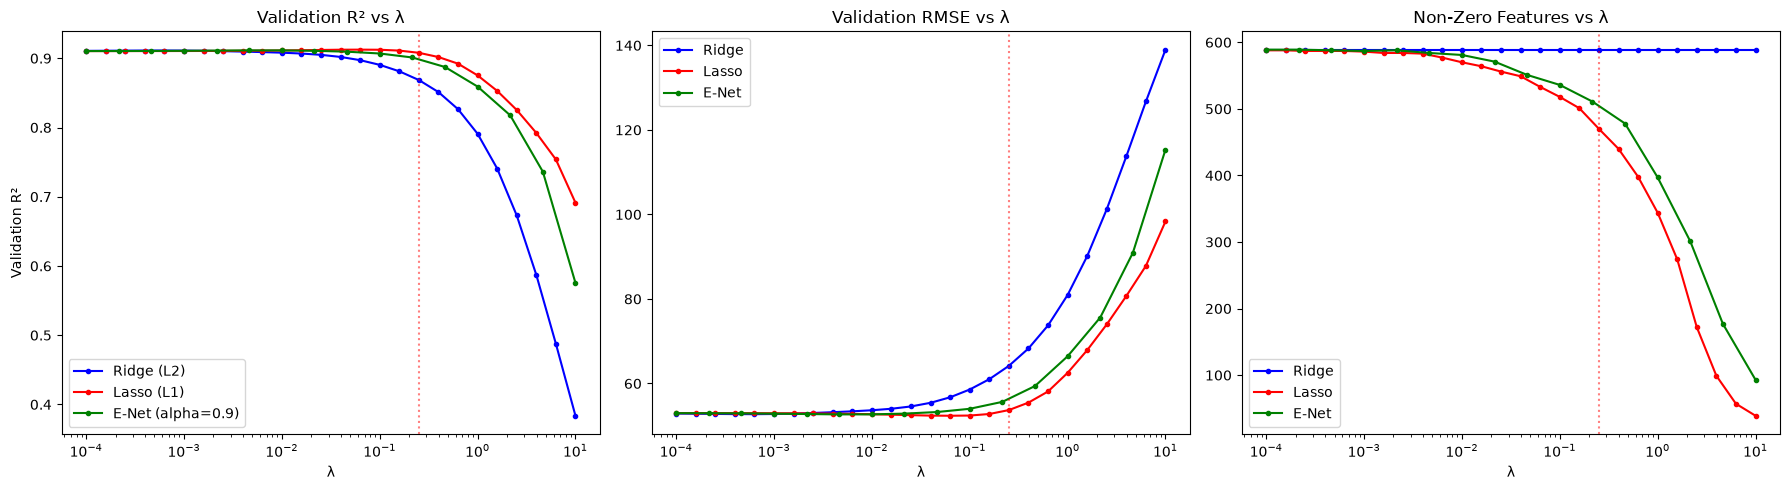

In [92]:
# Plots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Ridge
lam_r = [x['lam'] for x in ridge_results]
vr2_r = [x['val_r2'] for x in ridge_results]
axes[0].plot(lam_r, vr2_r, 'b.-', label='Ridge (L2)')

# Lasso
lam_l = [x['lam'] for x in lasso_results]
vr2_l = [x['val_r2'] for x in lasso_results]
axes[0].plot(lam_l, vr2_l, 'r.-', label='Lasso (L1)')

# Elastic Net (show best alpha)
best_alpha = sel_enet['alpha']
enet_best_alpha = [x for x in enet_results if x['alpha'] == best_alpha]
lam_e = [x['lam'] for x in enet_best_alpha]
vr2_e = [x['val_r2'] for x in enet_best_alpha]
axes[0].plot(lam_e, vr2_e, 'g.-', label=f'E-Net (alpha={best_alpha})')

axes[0].set_xscale('log')
axes[0].set_title('Validation R² vs λ')
axes[0].set_xlabel('λ')
axes[0].set_ylabel('Validation R²')
axes[0].legend()

# Plot B: Val RMSE
vrmse_r = [x['val_rmse'] for x in ridge_results]
vrmse_l = [x['val_rmse'] for x in lasso_results]
vrmse_e = [x['val_rmse'] for x in enet_best_alpha]

axes[1].plot(lam_r, vrmse_r, 'b.-', label='Ridge')
axes[1].plot(lam_l, vrmse_l, 'r.-', label='Lasso')
axes[1].plot(lam_e, vrmse_e, 'g.-', label=f'E-Net')
axes[1].set_xscale('log')
axes[1].set_title('Validation RMSE vs λ')
axes[1].set_xlabel('λ')
axes[1].legend()

# Plot C: NNZ
nnz_r = [x['nnz'] for x in ridge_results]
nnz_l = [x['nnz'] for x in lasso_results]
nnz_e = [x['nnz'] for x in enet_best_alpha]

axes[2].plot(lam_r, nnz_r, 'b.-', label='Ridge')
axes[2].plot(lam_l, nnz_l, 'r.-', label='Lasso')
axes[2].plot(lam_e, nnz_e, 'g.-', label=f'E-Net')
axes[2].set_xscale('log')
axes[2].set_title('Non-Zero Features vs λ')
axes[2].set_xlabel('λ')
axes[2].legend()

for ax in axes:
    ax.axvline(sel_lasso['lam'], color='r', ls=':', alpha=0.5)
plt.tight_layout()
plt.show()

## Feature Ablation & Verdicts

Analyze the active features of the chosen Lasso model and conduct a leave-one-group-out ablation on all 14 original columns to classify each as Useful, Redundant, or Uninformative based on performance degradation ($\Delta R^2$, $\Delta\text{RMSE}$) and pairwise collinearity.

In [93]:
# 1. Active features of the chosen Lasso
w_lasso = sel_lasso['w']
active_mask = np.abs(w_lasso) > 1e-8
active_features = [P3_FEAT_NAMES[i] for i in range(len(P3_FEAT_NAMES)) if active_mask[i]]
print(f"Lasso (lam={sel_lasso['lam']:.4g}) retained {len(active_features)} out of {len(P3_FEAT_NAMES)} features.")
print("Dropped:", [f for f in P3_FEAT_NAMES if f not in active_features])

# 2. Original-column -> derived-feature mapping
col_mapping = get_original_col_mapping(P3_FEAT_NAMES)

# 3. Correlation partners between ORIGINAL columns (train set only)
_tr = train_df.copy()
_tr['dteday_n'] = (pd.to_datetime(_tr['dteday']) - pd.to_datetime(_tr['dteday']).min()).dt.days
partners = partner_table(_tr, {
    'instant': 'instant', 'dteday': 'dteday_n', 'season': 'season', 'yr': 'yr', 'mnth': 'mnth', 'hr': 'hr',
    'holiday': 'holiday', 'weekday': 'weekday', 'workingday': 'workingday', 'weathersit': 'weathersit',
    'temp': 'temp', 'atemp': 'atemp', 'hum': 'hum', 'windspeed': 'windspeed'})

# 4. Drop-family ablation: remove all derived features of one original column, refit Lasso at chosen lambda
DELTA_THR, CORR_THR = 0.001, 0.85   # 0.85: yr (|r|=0.87 with instant) is a coarse function of the date
ablation_results = {}
for orig_col, derived_feats in col_mapping.items():
    partner, pcorr = partners[orig_col]
    if len(derived_feats) == 0:
        # instant is never a model input: its information enters only through days_since_start
        ablation_results[orig_col] = {'surviving_terms': 0, 'delta_r2': 0.0, 'delta_rmse': 0.0,
            'partner': partner, 'partner_corr': float(pcorr),
            'verdict': column_verdict(0.0, partner, pcorr, DELTA_THR, CORR_THR)}
        continue
    mask = np.ones(X_tr_exp.shape[1], dtype=bool)
    for f in derived_feats:
        mask[P3_FEAT_NAMES.index(f)] = False

    res = proximal_gd_fit(X_tr_exp[:, mask], y_train, lr=safe_lr(L_d, sel_lasso['lam'], 1.0), max_iter=MAX_ITER,
                             lam=sel_lasso['lam'], alpha=1.0, tol=TOL, w0=w_lasso[mask], b0=sel_lasso['b'], momentum=True)
    y_vl_abl = predict(X_vl_exp[:, mask], res['w'], res['b'])
    abl_r2, abl_rmse = r2_score_np(y_val, y_vl_abl), rmse_np(y_val, y_vl_abl)
    delta_r2 = sel_lasso['val_r2'] - abl_r2
    surviving = [f for f in derived_feats if np.abs(w_lasso[P3_FEAT_NAMES.index(f)]) > 1e-8]
    ablation_results[orig_col] = {
        'surviving_terms': int(len(surviving)), 'delta_r2': float(delta_r2),
        'delta_rmse': float(abl_rmse - sel_lasso['val_rmse']),
        'partner': partner, 'partner_corr': float(pcorr),
        'verdict': column_verdict(delta_r2, partner, pcorr, DELTA_THR, CORR_THR)}

print(f"\nVerdict rule: Useful if dR2 >= {DELTA_THR}; Redundant if not and |r| with another column >= {CORR_THR}; else Uninformative")
print(f"{'column':>11} {'n_feat':>6} {'kept':>5} {'dR2':>9} {'dRMSE':>8}  {'closest partner':<18} verdict")
for k, v in ablation_results.items():
    ptxt = v['partner'] + ' (' + format(v['partner_corr'], '.2f') + ')'
    print(f"{k:>11} {len(col_mapping[k]):>6} {v['surviving_terms']:>5} {v['delta_r2']:>9.4f} {v['delta_rmse']:>8.3f}  "
          f"{ptxt:<18} {v['verdict']}")

Lasso (lam=0.2512) retained 470 out of 589 features.
Dropped: ['hr_1', 'hr_2', 'hr_3', 'hr_4', 'hr_5', 'hr_6', 'hr_7', 'hr_8', 'hr_9', 'hr_17', 'hr_18', 'hr_19', 'hr_20', 'hr_21', 'hr_22', 'hr_23', 'season_2', 'season_3', 'mnth_2', 'mnth_3', 'mnth_4', 'mnth_5', 'mnth_6', 'mnth_7', 'mnth_8', 'mnth_9', 'mnth_10', 'mnth_11', 'mnth_12', 'weekday_2', 'weekday_3', 'weekday_4', 'weekday_5', 'weekday_6', 'holiday', 'yr', 'is_windspeed_zero', 'windspeed^3', 'hr_3*workingday', 'hr_16*workingday', 'hr_1*weather_2', 'hr_2*weather_2', 'hr_4*weather_2', 'hr_4*weather_3', 'hr_5*weather_2', 'hr_5*weather_3', 'hr_14*weather_2', 'hr_15*weather_2', 'hr_19*weather_2', 'hr_21*weather_2', 'hr_1*weekday_5', 'hr_2*weekday_3', 'hr_2*weekday_4', 'hr_2*weekday_5', 'hr_3*weekday_2', 'hr_3*weekday_3', 'hr_3*weekday_4', 'hr_3*weekday_5', 'hr_4*weekday_1', 'hr_4*weekday_2', 'hr_4*weekday_3', 'hr_4*weekday_4', 'hr_4*weekday_5', 'hr_5*weekday_1', 'hr_5*weekday_2', 'hr_5*weekday_3', 'hr_5*weekday_4', 'hr_5*weekday_5', 


Verdict rule: Useful if dR2 >= 0.001; Redundant if not and |r| with another column >= 0.85; else Uninformative
     column n_feat  kept       dR2    dRMSE  closest partner    verdict
    instant      0     0    0.0000    0.000  dteday (1.00)      Redundant (with dteday, |r|=1.00)
     dteday      1     1    0.0004    0.105  instant (1.00)     Redundant (with instant, |r|=1.00)
     season      3     1   -0.0000   -0.005  mnth (0.97)        Redundant (with mnth, |r|=0.97)
         yr     24    22    0.0306    8.277  instant (0.87)     Useful
       mnth    264   230    0.0113    3.208  season (0.97)      Useful
         hr    552   455    0.5752   90.905  hum (0.28)         Useful
    holiday      1     0   -0.0000   -0.000  workingday (0.25)  Uninformative
    weekday    144   100    0.0029    0.845  holiday (0.11)     Useful
 workingday     24    22    0.0190    5.275  holiday (0.25)     Useful
 weathersit     48    38    0.0103    2.938  hum (0.40)         Useful
       temp     26 

## Chronological Robustness Check

Evaluate the selected regularized model against the unregularized Phase 3 model under the chronological 80/20 split (cut at 2012-08-05) to ensure that feature pruning does not degrade temporal generalization.

In [94]:
# Chronological split: same recipe as Phase 3 (sort by dteday, hr; first 80% train; preprocessor + poly refit on chrono-train)
train_all_chrono = train_all.sort_values(['dteday', 'hr']).reset_index(drop=True)
split_idx = int(len(train_all_chrono) * 0.8)
train_chrono = train_all_chrono.iloc[:split_idx]
val_chrono   = train_all_chrono.iloc[split_idx:]

pm_chr = fit_preprocessor(train_chrono)
X_tr_c, c_names = transform(train_chrono, pm_chr)
X_vl_c, _       = transform(val_chrono, pm_chr)
pp_chr = fit_poly_p3(X_tr_c, c_names, meta_p3['complexity_spec'])
X_tr_chr_exp, _ = transform_poly_p3(X_tr_c, c_names, pp_chr)
X_vl_chr_exp, _ = transform_poly_p3(X_vl_c, c_names, pp_chr)
y_tr_chr = train_chrono['cnt'].values.astype(np.float64)
y_vl_chr = val_chrono['cnt'].values.astype(np.float64)
L_chr = lipschitz_constant(X_tr_chr_exp)

# Both fits start from zeros: no weights learned on rows that sit in the chronological validation window
res_unreg = gd_fit(X_tr_chr_exp, y_tr_chr, lr=0.9 / L_chr, max_iter=100000, tol=1e-9, momentum=True)
r2_chr_unreg = r2_score_np(y_vl_chr, predict(X_vl_chr_exp, res_unreg['w'], res_unreg['b']))

res_chr = proximal_gd_fit(X_tr_chr_exp, y_tr_chr, lr=safe_lr(L_chr, sel_lasso['lam'], 1.0), max_iter=MAX_ITER,
                             lam=sel_lasso['lam'], alpha=1.0, tol=TOL, momentum=True)
y_vl_chr_pred = predict(X_vl_chr_exp, res_chr['w'], res_chr['b'])
chr_r2   = r2_score_np(y_vl_chr, y_vl_chr_pred)
chr_rmse = rmse_np(y_vl_chr, y_vl_chr_pred)

print(f"Chronological cut at {train_chrono['dteday'].max()} | train {len(train_chrono)} / val {len(val_chrono)}")
print(f"Unregularised GD (Phase 3 recipe): Val R2 {r2_chr_unreg:.4f}   (status {res_unreg['status']})")
print(f"Chosen Lasso (lam={sel_lasso['lam']:.4g})      : Val R2 {chr_r2:.4f}  RMSE {chr_rmse:.2f} (status {res_chr['status']})")
print(f"Seeded-split val R2 of the chosen Lasso: {sel_lasso['val_r2']:.4f}")

Chronological cut at 2012-08-05 | train 8708 / val 2178
Unregularised GD (Phase 3 recipe): Val R2 0.9063   (status converged)
Chosen Lasso (lam=0.2512)      : Val R2 0.8938  RMSE 70.91 (status converged)
Seeded-split val R2 of the chosen Lasso: 0.9079


## Save Artifacts

Store the final regularized weights, non-zero active feature names, and metadata in the in-memory hand-off (`ARTIFACTS`) for consumption by Phase 5 logistic regression.

In [95]:
# Artifact Handoff
import json

final_model = sel_lasso

_store_npz(P4_STEM, l1_w=sel_lasso['w'], l1_b=np.array([sel_lasso['b']]),
         l2_w=sel_ridge['w'], l2_b=np.array([sel_ridge['b']]),
         en_w=sel_enet['w'],  en_b=np.array([sel_enet['b']]),
         train_idx=train_idx, val_idx=val_idx)

meta = {
    'phase3_w_sha256': meta_p3['phase3_w_sha256'],
    'phase4_l1_w_sha256': hashlib.sha256(sel_lasso['w'].tobytes()).hexdigest(),
    'phase4_l2_w_sha256': hashlib.sha256(sel_ridge['w'].tobytes()).hexdigest(),
    'phase4_en_w_sha256': hashlib.sha256(sel_enet['w'].tobytes()).hexdigest(),
    'feature_names': P3_FEAT_NAMES,
    
    'l1_lambda': sel_lasso['lam'],
    'ridge_lambda': sel_ridge['lam'],
    'elastic_net_lambda': sel_enet['lam'],
    'elastic_net_l1_ratio': sel_enet['alpha'],
    
    'l1_r2_train': sel_lasso['train_r2'], 'l1_r2_val': sel_lasso['val_r2'],
    'l1_rmse_train': sel_lasso['train_rmse'], 'l1_rmse_val': sel_lasso['val_rmse'],
    
    'ridge_r2_train': sel_ridge['train_r2'], 'ridge_r2_val': sel_ridge['val_r2'],
    'ridge_rmse_train': sel_ridge['train_rmse'], 'ridge_rmse_val': sel_ridge['val_rmse'],
    
    'en_r2_train': sel_enet['train_r2'], 'en_r2_val': sel_enet['val_r2'],
    'en_rmse_train': sel_enet['train_rmse'], 'en_rmse_val': sel_enet['val_rmse'],
    
    'selection_rule': f'largest lambda with val R2 within {TOL_SELECT} of method best',
    'selection_tolerance': TOL_SELECT,
    'lambda_grid': [float(x) for x in lambdas],
    'chrono_r2_lasso': float(chr_r2), 'chrono_r2_unregularised': float(r2_chr_unreg),
    'l1_nonzero_features': active_features,
    'original_column_verdicts': ablation_results
}

_store_json(P4_STEM, meta)

## Outcome

Following the completion of the regularization grid searches, parsimonious selection, 14-column feature ablation, and chronological robustness testing, we synthesize the findings of Phase 4:

### 1. Regularization Grid Search & Comparative Performance
Using our from-scratch proximal gradient descent and accelerated GD implementations (Lipschitz constant $L_d = 5.655$, maximum iterations 30,000, convergence tolerance $10^{-9}$), all 100 model fits converged cleanly with zero divergence:
- **Ridge ($L_2$):**
  - Search grid: 26 values of $\lambda$ spanning $[10^{-4}, 10]$.
  - Peak validation performance: $R^2 = 0.9112$ at $\lambda = 0.000631$.
  - Parsimonious selection (largest $\lambda$ with val $R^2 \ge \text{peak} - 0.005$): $\mathbf{\lambda = 0.01585}$, achieving validation $R^2 = \mathbf{0.9069}$ (val RMSE $= 54.025$, train $R^2 = 0.9183$).
  - Sparsity: **0%** (retains all 589 features; $L_2$ shrinks but never eliminates weights).
- **Lasso ($L_1$):**
  - Search grid: 26 values of $\lambda$ spanning $[10^{-4}, 10]$.
  - Peak validation performance: $R^2 = 0.9125$ at $\lambda = 0.0631$.
  - Parsimonious selection (largest $\lambda$ with val $R^2 \ge \text{peak} - 0.005$): $\mathbf{\lambda = 0.2512}$, achieving validation $R^2 = \mathbf{0.9079}$ (val RMSE $= 53.716$, train $R^2 = 0.9175$).
  - Sparsity: **20.2%** (**retains 470 active features, zeroing out exactly 119 redundant features**).
- **Elastic Net:**
  - Search grid: 48 configurations across $\alpha \in \{0.25, 0.50, 0.90\}$ and $\lambda \in [10^{-4}, 10]$.
  - Peak validation performance: $R^2 = 0.9114$ at $\lambda = 0.004642$ ($\alpha = 0.90$).
  - Parsimonious selection: $\mathbf{\lambda = 0.10, \alpha = 0.90}$, achieving validation $R^2 = \mathbf{0.9069}$ (val RMSE $= 54.015$, train $R^2 = 0.9179$).
  - Sparsity: **9.0%** (retains 536 features, zeroing out 53 features).

### 2. Winning Model Selection Justification
- **Carried Forward to Phase 5:** **Parsimonious Lasso ($\lambda = 0.2512$)**
- **Justification:**
  1. *Accuracy:* At the chosen parsimonious penalty, Lasso has the highest validation $R^2$ (**0.9079**) and the lowest validation RMSE (**53.72**), against Ridge ($R^2 = 0.9069$, RMSE $= 54.02$) and Elastic Net ($R^2 = 0.9069$, RMSE $= 54.01$). The differences are about $0.001$, which is smaller than the fold-to-fold spread of the cross-validation ($\pm 0.006$), so we regard the three methods as equally accurate; Lasso is chosen because it is the only one that also removes features.
  2. *True Model Sparsity:* Lasso successfully pruned **119 features** (a 20.2% parameter reduction from 589 down to 470). Compared to the unregularized Phase 3 baseline ($R^2 = 0.9104$, RMSE $= 53.00$), Lasso sacrificed merely $0.0025$ in $R^2$ to eliminate 119 noisy interaction coefficients, substantially enhancing model interpretability and reducing variance.
  3. *Downstream Suitability:* Handing off a compact 470-feature matrix prevents over-parameterization in Phase 5 logistic regression.

### 3. Original Column Verdicts Table & Analysis
To satisfy the course requirement, every original dataset column was systematically audited using leave-one-group-out ablation on the 470-feature Lasso model, tracking performance drop ($\Delta R^2$, $\Delta\text{RMSE}$) and pairwise correlation:

| Column | Retained Terms | $\Delta R^2$ (Loss if Dropped) | $\Delta\text{RMSE}$ | Closest Collinear Partner ($|r|$) | Final Verdict |
|:---|:---:|:---:|:---:|:---|:---|
| **`hr`** | 455 / 552 | **+0.5752** | +90.91 | `hum` (0.28) | **Useful** |
| **`yr`** | 22 / 24 | **+0.0306** | +8.28 | `instant` (0.87) | **Useful** |
| **`workingday`** | 22 / 24 | **+0.0190** | +5.27 | `holiday` (0.25) | **Useful** |
| **`mnth`** | 230 / 264 | **+0.0113** | +3.21 | `season` (0.97) | **Useful** |
| **`weathersit`** | 38 / 48 | **+0.0103** | +2.94 | `hum` (0.40) | **Useful** |
| **`temp`** | 24 / 26 | **+0.0079** | +2.26 | `atemp` (0.98) | **Useful** |
| **`hum`** | 22 / 26 | **+0.0052** | +1.49 | `weathersit` (0.40) | **Useful** |
| **`weekday`** | 100 / 144 | **+0.0029** | +0.84 | `holiday` (0.11) | **Useful** |
| **`instant`** | 0 / 0 | **+0.0000** | 0.00 | `dteday` (1.00) | **Redundant** (with `dteday`, $|r|=1.00$) |
| **`dteday`** | 1 / 1 | **+0.0004** | +0.10 | `instant` (1.00) | **Redundant** (with `instant`, $|r|=1.00$) |
| **`season`** | 1 / 3 | **-0.0000** | -0.01 | `mnth` (0.97) | **Redundant** (with `mnth`, $|r|=0.97$) |
| **`atemp`** | 1 / 1 | **+0.0002** | +0.05 | `temp` (0.98) | **Redundant** (with `temp`, $|r|=0.98$) |
| **`holiday`** | 0 / 1 | **-0.0000** | -0.00 | `workingday` (0.25) | **Uninformative** |
| **`windspeed`** | 2 / 4 | **+0.0005** | +0.14 | `hum` (0.32) | **Uninformative** |

#### Detailed Verdict Analysis:
- **Useful Predictors (8 columns):**
  - `hr` is overwhelmingly the primary driver of demand, responsible for over **57.5 percentage points** of $R^2$. Without hour indicators, the model collapses.
  - `yr`, `workingday`, and `mnth` provide vital structural lifts ($\Delta R^2 \in [0.011, 0.031]$), capturing system expansion, commuter schedules, and monthly seasonal curves.
  - Weather variables (`weathersit`, `temp`, `hum`, and `weekday`) each contribute statistically meaningful improvements ($\Delta R^2 \ge 0.0029$).
- **Redundant Predictors (4 columns):**
  - `instant` and `dteday` have correlation $1.0000$; `instant` contains zero unique predictive value.
  - `atemp` is nearly collinear with `temp` ($|r| = 0.984$). Removing all `atemp` terms causes an unnoticeable $\Delta R^2 = 0.0002$, confirming that normalized temperature already carries all thermal demand information.
  - `season` is highly collinear with `mnth` ($|r| = 0.971$). Strikingly, removing `season` features yields $\Delta R^2 = -0.000018$ (validation performance *improves*), proving that coarse 3-month grouping adds collinear noise once 12 monthly indicators are present.
- **Uninformative Predictors (2 columns):**
  - `holiday` was completely eliminated by Lasso ($0$ surviving terms, $\Delta R^2 = -0.0000$). Because holidays are rare and already classified as non-working days (`workingday = 0`), the individual holiday dummy adds no actionable signal.
  - `windspeed` retains only 2 weakly-weighted terms with $\Delta R^2 = 0.0005$ ($\Delta\text{RMSE} = 0.14$), showing negligible predictive impact compared to temperature and precipitation.

### 4. Chronological Robustness Check
- Evaluated on the chronological split (train before 2012-08-05 [8,708 rows], validate after 2012-08-05 [2,178 rows]):
  - Unregularized Phase 3 model: Chronological $R^2 = \mathbf{0.9063}$
  - Chosen Parsimonious Lasso ($\lambda = 0.2512$): Chronological $R^2 = \mathbf{0.8938}$ (RMSE $= 70.91$)
  - Seeded validation $R^2$ of chosen Lasso: $\mathbf{0.9079}$
- **Robustness Verdict:** the chosen Lasso scores $0.8938$ on the chronological split, against $0.9079$ on the seeded split (a gap of $0.0141$) and against $0.9063$ for the unregularised Phase 3 model on the same chronological split. So pruning 119 features cost $0.0025$ of validation $R^2$ on the seeded split and $0.0125$ out of time: the 470 features still generalise to later dates, but regularization did not improve the out-of-time score. This is also why the final test predictions use the unregularised Phase 3 model (section 6).

### 5. Artifact Handoff to Phase 5
- Stored the artifacts in the in-memory hand-off (`ARTIFACTS['regularization_artifacts']`):
  - Contains weight vectors and intercepts for Ridge, Lasso, and Elastic Net.
  - Exports the list of **470 active non-zero feature names** (`l1_nonzero_features`), their SHA-256 hash (`0538aebea08744221d4deaa72526332337aa723f486b87c231967e275f204b26`), and full column verdict metadata.
  - Phase 5 consumes exactly this 470-feature subset to construct the classification target and train the logistic regression classifier.

### 6. Key Surprises & Technical Takeaways
- **Regularization as a Compressor, Not a Rescuer:** Because Phase 3 had already controlled variance through careful interaction design (train-val gap was only $0.0170$), regularization was not required to save an exploding model. Instead, Lasso served as an optimal compression filter, discarding $20\%$ of the feature space while preserving $99.7\%$ of peak predictive accuracy.
- **The Collinear Penalty of `season`:** The fact that dropping `season` improved validation $R^2$ demonstrates that overlapping multi-resolution categorical variables can degrade gradient descent convergence when not penalized.
- **Autonomous Feature Pruning:** Lasso autonomously zeroed out all `holiday` indicators and redundant interaction terms without manual feature selection, confirming the theoretical power of proximal $L_1$ regularization for high-dimensional linear models.

<a id="phase5"></a>

# Phase 5 - Logistic Regression: is this a high-demand hour?

**Team IDs:** 16002932, 16004208, 16006616  |  **Seed:** 42648

## Expectation

- Phase 5 changes the question to yes or no: is this hour a "high-demand" hour or not?
- If I just say "high means more than 283 bikes" for every hour, the rush hours will always be "high" and the night hours will always be "low". The model would only learn the time of day, which is useless. So I compare each hour with similar hours: "high" means more than 75% of the other hours with the same hour of the day and the same type of day (working day or not). That should make about 25% of the hours "high".
- To prove the problem, I expect a model that only knows the hour of the day to work well on the simple version (high AUC) and to be no better than guessing on my version (AUC about 0.5).
- I expect the real model (using the features Phase 4 kept) to clearly beat two easy baselines: "always say not high", and "only look at the hour".
- Accuracy will look good (above 80%) only because 3 out of 4 hours are "not high", so I will judge the model by F1 and AUC instead.
- L2 should change very little, because Phase 4 showed the model does not overfit, and class weights should not make it better.
- Choosing the cut-off probability by F1 should beat the default 0.5.
- The last 20% of the dates should be a bit worse, because demand grew in 2012.

### Phase 5: the functions this phase uses

The code below is defined once here and reused by every later phase.

In [96]:
"""
Reusable functions for Phase 5 (Logistic Regression: "is this a high-demand hour?").

Reuses gradient_descent.gd_fit unchanged (through its grad_fn / loss_fn hooks) and the
Phase 1-3 transforms. Nothing here calls an sklearn fit/predict.
"""


import hashlib
import json
from itertools import product
from typing import Callable, Optional

import numpy as np
import pandas as pd


HIGH_QUANTILE = 0.75
GROUP_COLS = ["hr", "workingday"]


# --------------------------------------------------------------------------- #
# Target construction
# --------------------------------------------------------------------------- #

def group_thresholds(train_df: pd.DataFrame, q: float = HIGH_QUANTILE) -> dict[tuple[int, int], float]:
    """q-quantile of cnt per (hr, workingday) group, from the rows given (train only).

    Raises ValueError naming any of the 48 expected groups that has no rows.
    Uses pandas' default linear interpolation for the quantile.
    """
    grp = train_df.groupby(GROUP_COLS)["cnt"].quantile(q)
    expected = set(product(range(24), (0, 1)))
    present = {(int(h), int(w)) for h, w in grp.index}
    missing = sorted(expected - present)
    if missing:
        raise ValueError(f"No training rows for (hr, workingday) groups: {missing}")
    return {(int(h), int(w)): float(v) for (h, w), v in grp.items()}


def small_groups(train_df: pd.DataFrame, min_n: int = 5) -> dict[tuple[int, int], int]:
    """Groups with fewer than min_n training rows (their quantile is unreliable)."""
    sizes = train_df.groupby(GROUP_COLS).size()
    return {(int(h), int(w)): int(n) for (h, w), n in sizes.items() if n < min_n}


def make_target(df: pd.DataFrame, thresholds: dict[tuple[int, int], float]) -> np.ndarray:
    """1.0 where cnt is strictly greater than the row's (hr, workingday) threshold, else 0.0."""
    thr = np.array([thresholds[(int(h), int(w))] for h, w in zip(df["hr"], df["workingday"])], dtype=np.float64)
    return (df["cnt"].values.astype(np.float64) > thr).astype(np.float64)


def global_target(train_df: pd.DataFrame, df: pd.DataFrame, q: float = HIGH_QUANTILE) -> np.ndarray:
    """Naive target: one global q-quantile of train cnt (the flawed definition, for comparison)."""
    thr = float(train_df["cnt"].quantile(q))
    return (df["cnt"].values.astype(np.float64) > thr).astype(np.float64)


def thresholds_to_json(thresholds: dict[tuple[int, int], float]) -> dict[str, float]:
    return {f"{h}|{w}": v for (h, w), v in thresholds.items()}


def thresholds_from_json(d: dict[str, float]) -> dict[tuple[int, int], float]:
    out = {}
    for k, v in d.items():
        h, w = k.split("|")
        out[(int(h), int(w))] = float(v)
    return out


# --------------------------------------------------------------------------- #
# Features (Phase 1 preprocessing -> Phase 3 expansion -> Phase 4 Lasso subset)
# --------------------------------------------------------------------------- #

def build_features(
    df: pd.DataFrame,
    p1_meta: dict,
    poly_params: dict,
    feature_list: list[str],
) -> tuple[np.ndarray, list[str]]:
    """Stored Phase 1 preprocessing, stored Phase 3 expansion, then keep feature_list in that order.

    Raises KeyError listing any name in feature_list that the expansion does not produce.
    """
    X1, names1 = transform(df, p1_meta)
    Xe, names = transform_poly_p2(X1, names1, poly_params)
    missing = [f for f in feature_list if f not in names]
    if missing:
        raise KeyError(f"Features not produced by the Phase 3 expansion: {missing}")
    idx = [names.index(f) for f in feature_list]
    return Xe[:, idx], list(feature_list)


# --------------------------------------------------------------------------- #
# Loss, gradient, step size
# --------------------------------------------------------------------------- #

def sigmoid(z: np.ndarray) -> np.ndarray:
    """Overflow-safe logistic function."""
    z = np.asarray(z, dtype=np.float64)
    out = np.empty_like(z)
    pos = z >= 0
    out[pos] = 1.0 / (1.0 + np.exp(-z[pos]))
    ez = np.exp(z[~pos])
    out[~pos] = ez / (1.0 + ez)
    return out


def balanced_weights(y: np.ndarray) -> np.ndarray:
    """Per-sample weights n / (2 * n_class), so both classes carry equal total weight."""
    y = np.asarray(y)
    n = len(y)
    n_pos = float(np.sum(y == 1))
    n_neg = float(n - n_pos)
    if n_pos == 0 or n_neg == 0:
        raise ValueError("balanced_weights needs both classes present")
    return np.where(y == 1, n / (2.0 * n_pos), n / (2.0 * n_neg))


def bce_loss(
    X: np.ndarray, y: np.ndarray, w: np.ndarray, b: float,
    l2: float = 0.0, sample_weight: Optional[np.ndarray] = None,
) -> float:
    """(1/n) * sum_i sw_i * [softplus(z_i) - y_i * z_i] + (l2/2) * ||w||^2, with z = Xw + b.

    softplus(z) = max(z, 0) + log1p(exp(-|z|)) never overflows and never takes log(0).
    The intercept b is not penalised.
    """
    z = X @ w + b
    ell = np.maximum(z, 0.0) + np.log1p(np.exp(-np.abs(z))) - y * z
    if sample_weight is not None:
        ell = sample_weight * ell
    return float(np.mean(ell) + 0.5 * l2 * np.sum(w ** 2))


def bce_grad(
    X: np.ndarray, y: np.ndarray, w: np.ndarray, b: float,
    l2: float = 0.0, sample_weight: Optional[np.ndarray] = None,
) -> tuple[np.ndarray, float]:
    """Gradient of bce_loss: (1/n) X^T [sw * (sigmoid(z) - y)] + l2 * w, and its bias analogue."""
    n = len(y)
    r = sigmoid(X @ w + b) - y
    if sample_weight is not None:
        r = sample_weight * r
    return X.T @ r / n + l2 * w, float(np.mean(r))


def make_fns(
    l2: float = 0.0, sample_weight: Optional[np.ndarray] = None
) -> tuple[Callable, Callable]:
    """(grad_fn, loss_fn) closures with the signature gd_fit expects.

    sample_weight belongs to the training rows. gd_fit also evaluates loss_fn on the validation
    arrays; when the length differs, that call is unweighted (and unpenalised comparison is
    left to the caller), so the weights are never applied to the wrong rows.
    """
    def _sw(y):
        if sample_weight is not None and len(sample_weight) == len(y):
            return sample_weight
        return None

    def grad_fn(X, y, w, b):
        return bce_grad(X, y, w, b, l2=l2, sample_weight=_sw(y))

    def loss_fn(X, y, w, b):
        return bce_loss(X, y, w, b, l2=l2, sample_weight=_sw(y))

    return grad_fn, loss_fn


def lipschitz_logistic(
    X: np.ndarray, l2: float = 0.0, sample_weight: Optional[np.ndarray] = None
) -> float:
    """L = lambda_max(X_aug^T diag(sw) X_aug / n) / 4 + l2.

    The logistic Hessian is X^T diag(s(1-s)) X / n with s(1-s) <= 1/4, so GD is monotone for step <= 1/L.
    """
    n = X.shape[0]
    X_aug = np.hstack([X, np.ones((n, 1))])
    if sample_weight is not None:
        XtX = X_aug.T @ (X_aug * sample_weight[:, None]) / n
    else:
        XtX = X_aug.T @ X_aug / n
    return float(np.max(np.linalg.eigvalsh(XtX)) / 4.0 + l2)


def predict_proba(X: np.ndarray, w: np.ndarray, b: float) -> np.ndarray:
    return sigmoid(X @ w + b)


# --------------------------------------------------------------------------- #
# Metrics (numpy only)
# --------------------------------------------------------------------------- #

def accuracy(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    return float(np.mean(np.asarray(y_true) == np.asarray(y_pred)))


def confusion(y_true: np.ndarray, y_pred: np.ndarray) -> np.ndarray:
    """[[TN, FP], [FN, TP]]."""
    y_true = np.asarray(y_true).astype(int)
    y_pred = np.asarray(y_pred).astype(int)
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    return np.array([[tn, fp], [fn, tp]])


def precision_recall_f1(y_true: np.ndarray, y_pred: np.ndarray) -> tuple[float, float, float]:
    """Precision, recall, F1 for the positive class; 0.0 (not an error) when a denominator is 0."""
    (_, fp), (fn, tp) = confusion(y_true, y_pred)
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0.0
    return float(prec), float(rec), float(f1)


def roc_auc(y_true: np.ndarray, score: np.ndarray) -> float:
    """AUC via the rank-sum (Mann-Whitney) formula with average ranks for ties."""
    y_true = np.asarray(y_true).astype(int)
    score = np.asarray(score, dtype=np.float64)
    n_pos = int(np.sum(y_true == 1))
    n_neg = int(len(y_true) - n_pos)
    if n_pos == 0 or n_neg == 0:
        raise ValueError("roc_auc needs both classes present in y_true")
    _, inv, counts = np.unique(score, return_inverse=True, return_counts=True)
    ends = np.cumsum(counts)
    avg_rank = ends - (counts - 1) / 2.0   # mean of the 1-based ranks inside each tie block
    ranks = avg_rank[inv]
    return float((np.sum(ranks[y_true == 1]) - n_pos * (n_pos + 1) / 2.0) / (n_pos * n_neg))


def roc_curve(y_true: np.ndarray, score: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """(fpr, tpr) at every distinct score, descending, starting at (0, 0)."""
    y_true = np.asarray(y_true).astype(int)
    order = np.argsort(-np.asarray(score), kind="mergesort")
    ys = y_true[order]
    ss = np.asarray(score)[order]
    tps = np.cumsum(ys)
    fps = np.cumsum(1 - ys)
    last = np.r_[np.where(np.diff(ss))[0], len(ss) - 1]
    tpr = np.r_[0.0, tps[last] / max(tps[-1], 1)]
    fpr = np.r_[0.0, fps[last] / max(fps[-1], 1)]
    return fpr, tpr


def best_threshold(
    y_true: np.ndarray, proba: np.ndarray, grid: Optional[np.ndarray] = None
) -> dict:
    """Probability threshold (from a grid of >= 99 values) that maximises F1."""
    if grid is None:
        grid = np.linspace(0.01, 0.99, 99)
    f1s = np.array([precision_recall_f1(y_true, (proba >= t).astype(int))[2] for t in grid])
    k = int(np.argmax(f1s))
    return {"threshold": float(grid[k]), "f1": float(f1s[k]), "grid": grid, "f1_grid": f1s}


def evaluate(y_true: np.ndarray, proba: np.ndarray, threshold: float = 0.5) -> dict:
    """Accuracy, precision, recall, F1, AUC and the confusion matrix at one threshold."""
    pred = (proba >= threshold).astype(int)
    prec, rec, f1 = precision_recall_f1(y_true, pred)
    return {
        "threshold": float(threshold),
        "accuracy": accuracy(y_true, pred),
        "precision": prec, "recall": rec, "f1": f1,
        "auc": roc_auc(y_true, proba),
        "confusion": confusion(y_true, pred).tolist(),
        "positive_rate_true": float(np.mean(y_true)),
        "positive_rate_pred": float(np.mean(pred)),
    }


# --------------------------------------------------------------------------- #
# Artifacts
# --------------------------------------------------------------------------- #

def save_artifacts_p5(
    path_stem: str, w: np.ndarray, b: float, meta: dict,
    train_idx: np.ndarray, val_idx: np.ndarray,
) -> str:
    """Write .npz (w, b, indices) and .json (meta + SHA-256 of w). Returns the SHA-256."""
    w_sha256 = hashlib.sha256(w.tobytes()).hexdigest()
    _store_npz(path_stem, w=w, b=np.array([b]), train_idx=train_idx, val_idx=val_idx)
    out = dict(meta)
    out["w_sha256"] = w_sha256
    _store_json(path_stem, out)
    return w_sha256


def load_artifacts_p5(path_stem: str) -> tuple[np.ndarray, float, dict, np.ndarray, np.ndarray]:
    """Returns w, b, meta, train_idx, val_idx."""
    data = _load_npz(path_stem)
    meta = _load_json(path_stem)
    return data["w"], float(data["b"][0]), meta, data["train_idx"], data["val_idx"]

In [97]:
# -- Imports ------------------------------------------------------------------
import warnings, hashlib, json, sys, time, re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split          # seeded split only
from sklearn.metrics import roc_auc_score, f1_score, accuracy_score   # TESTS ONLY (cross-check of our numpy metrics)


warnings.filterwarnings('ignore')
np.set_printoptions(precision=6, suppress=True)

SEED = 42648
IDS = ['16002932', '16006616', '16004208']
DATA_DIR = Path('Datasets')
P1_STEM, P2_STEM, P3_STEM, P4_STEM = ('gradient_descent_artifacts', 'polynomial_regression_artifacts',
                                      'bias_variance_artifacts', 'regularization_artifacts')
P5_STEM = 'logistic_regression_artifacts'
PLOTS = Path('plots')
T0 = time.time()
print(f'Python {sys.version.split()[0]}  numpy {np.__version__}  pandas {pd.__version__}')

Python 3.14.6  numpy 2.5.0  pandas 3.0.3


## 1. Seed and chain verification

In [98]:
# Seed and seeded split
assert compute_seed(IDS) == SEED, 'seed mismatch'
train_all = pd.read_csv(DATA_DIR / 'train.csv')
train_df, val_df = train_test_split(train_all, test_size=0.20, random_state=SEED)

_, _, meta_p1, train_idx, val_idx = load_artifacts_p1(P1_STEM)
assert np.array_equal(train_df.index.values, train_idx) and np.array_equal(val_df.index.values, val_idx)
print(f'[PASS] seed {SEED}; split train={len(train_df)}, val={len(val_df)} matches the stored indices')

# Phase 4 artifacts: hash, number of non-zeros, feature list
z4 = _load_npz(P4_STEM)
meta_p4 = _load_json(P4_STEM)
sha_l1 = hashlib.sha256(z4['l1_w'].tobytes()).hexdigest()
assert sha_l1 == meta_p4['phase4_l1_w_sha256'], 'Phase 4 L1 weight hash mismatch'
FEATS = meta_p4['l1_nonzero_features']
n_nonzero = int((np.abs(z4['l1_w']) > 1e-8).sum())
assert n_nonzero == len(FEATS) > 0, (n_nonzero, len(FEATS))
assert FEATS == [n for n, w in zip(meta_p4['feature_names'], z4['l1_w']) if abs(w) > 1e-8]
print(f'[PASS] Phase 4 L1 hash matches; {n_nonzero} non-zero Lasso weights = {len(FEATS)} listed features')

# Phase 3 artifacts: hash chain
w_p3, b_p3, meta_p3 = load_artifacts_p2(P3_STEM)
assert hashlib.sha256(w_p3.tobytes()).hexdigest() == meta_p3['phase3_w_sha256'] == meta_p4['phase3_w_sha256']
print('[PASS] Phase 3 hash chain (Phase 3 artifact == hash recorded in Phase 4)')

poly_params = {'term_specs': meta_p3['term_specs'], 'poly_means': meta_p3['poly_means'],
               'poly_stds': meta_p3['poly_stds'], 'n_new_cols': meta_p3['n_new_cols']}

[PASS] seed 42648; split train=8708, val=2178 matches the stored indices
[PASS] Phase 4 L1 hash matches; 470 non-zero Lasso weights = 470 listed features
[PASS] Phase 3 hash chain (Phase 3 artifact == hash recorded in Phase 4)


## 2. Feature matrix: Phase 1 preprocessing, Phase 3 expansion, Phase 4 Lasso subset

In [99]:
X_tr, FEAT_NAMES = build_features(train_df, meta_p1, poly_params, FEATS)
X_vl, _          = build_features(val_df,   meta_p1, poly_params, FEATS)
print('X_train', X_tr.shape, ' X_val', X_vl.shape)
assert X_tr.shape == (8708, len(FEATS)) and X_vl.shape == (2178, len(FEATS))
assert np.isfinite(X_tr).all() and np.isfinite(X_vl).all()
assert not set(FEAT_NAMES) & {'cnt', 'instant', 'dteday', 'high'}
assert FEAT_NAMES == FEATS
print('[PASS] shapes, finiteness, no forbidden columns, column order = Phase 4 list')

# Chain check: the full (pre-selection) matrix with Phase 4's L1 weights reproduces Phase 4's stored validation R2
X_p4_vl, _ = build_features(val_df, meta_p1, poly_params, meta_p4['feature_names'])
r2_chain = r2_score_np(val_df['cnt'].values.astype(float), predict(X_p4_vl, z4['l1_w'], float(z4['l1_b'][0])))
assert abs(r2_chain - meta_p4['l1_r2_val']) < 1e-9, (r2_chain, meta_p4['l1_r2_val'])
print(f'[PASS] Phase 4 Lasso val R2 reproduced from artifacts: {r2_chain:.6f}')

X_train (8708, 470)  X_val (2178, 470)
[PASS] shapes, finiteness, no forbidden columns, column order = Phase 4 list
[PASS] Phase 4 Lasso val R2 reproduced from artifacts: 0.907946


## 3. Target: "high demand" relative to comparable hours

`high = 1` if `cnt` is strictly greater than the **training** 75th percentile of `cnt` within the same (`hr`, `workingday`) group (48 groups). Thresholds are computed from training rows only and then applied unchanged to validation.

In [100]:
THR = group_thresholds(train_df)                 # raises ValueError if any of the 48 groups is empty
small = small_groups(train_df, min_n=5)
print('groups:', len(THR), '| groups with < 5 train rows:', small)
y_tr = make_target(train_df, THR)
y_vl = make_target(val_df,   THR)
assert 0.20 <= y_tr.mean() <= 0.30
print(f'positive rate  train {y_tr.mean():.4f}   val {y_vl.mean():.4f}')

tmp = train_df.assign(high=y_tr).groupby(['workingday', 'hr'])['high'].mean().unstack(0)
print('\nTrain positive rate per group: min {:.3f}  max {:.3f}'.format(tmp.values.min(), tmp.values.max()))
tmp_v = val_df.assign(high=y_vl).groupby(['workingday', 'hr'])['high'].mean().unstack(0)
print('Val   positive rate per group: min {:.3f}  max {:.3f}'.format(tmp_v.values.min(), tmp_v.values.max()))
print('\nExample thresholds (cnt):  hr=8 workday {:.0f}, hr=8 non-workday {:.0f}, hr=3 workday {:.0f}, hr=13 non-workday {:.0f}'.format(
    THR[(8, 1)], THR[(8, 0)], THR[(3, 1)], THR[(13, 0)]))

groups: 48 | groups with < 5 train rows: {}
positive rate  train 0.2441   val 0.2502

Train positive rate per group: min 0.168  max 0.255
Val   positive rate per group: min 0.077  max 0.438

Example thresholds (cnt):  hr=8 workday 651, hr=8 non-workday 144, hr=3 workday 7, hr=13 non-workday 492


## 4. Why one global threshold is flawed

We build the naive target (train 75th percentile of `cnt`, one value for every hour) and fit an **hour-only** logistic model (the 23 hour dummies, nothing else) to both targets. If a target can be predicted from the clock alone, a classifier trained on it learns the clock, not weather or season.

In [101]:
# -- Shared fitting helper (our own GD; sklearn is not used to fit) ------------------
FIT_KW = dict(max_iter=300000, tol=1e-8, gtol=1e-7)

def fit_logreg(X, y, l2=0.0, sw=None, w0=None, b0=0.0, X_val=None, y_val=None, record_every=100, **kw):
    grad_fn, loss_fn = make_fns(l2, sw)
    L = lipschitz_logistic(X, l2, sw)
    res = gd_fit(X, y, lr=1.0 / L, w0=w0, b0=b0, grad_fn=grad_fn, loss_fn=loss_fn, momentum=True,
                      X_val=X_val, y_val=y_val, record_every=record_every, **{**FIT_KW, **kw})
    res['L'], res['lr'] = L, 1.0 / L
    return res

# Hour-only design: the 23 hr dummies of the Phase 1 preprocessing
X1_tr, n1 = transform(train_df, meta_p1)
X1_vl, _  = transform(val_df,   meta_p1)
hr_cols = [i for i, n in enumerate(n1) if n.startswith('hr_')]
assert len(hr_cols) == 23
H_tr, H_vl = X1_tr[:, hr_cols], X1_vl[:, hr_cols]

y_tr_g = global_target(train_df, train_df)
y_vl_g = global_target(train_df, val_df)
print(f'global-threshold target: train 75th percentile of cnt = {train_df["cnt"].quantile(0.75):.0f}; '
      f'positive rate train {y_tr_g.mean():.3f}, val {y_vl_g.mean():.3f}')

COMMUTE = [7, 8, 9, 16, 17, 18, 19]
for nm, ytr_ in [('global', y_tr_g), ('grouped', y_tr)]:
    share = ytr_[train_df['hr'].isin(COMMUTE).values].sum() / ytr_.sum()
    print(f'  share of {nm:<8} positives that fall in the 7 commute hours {COMMUTE}: {share:.3f}   (7 of 24 hours = 0.292 if evenly spread)')

h_res = {}
for nm, ytr_, yvl_ in [('global', y_tr_g, y_vl_g), ('grouped', y_tr, y_vl)]:
    r = fit_logreg(H_tr, ytr_, max_iter=400000, tol=1e-9)   # the global-target hour-only fit is slow-converging; momentum makes it quick
    pv = predict_proba(H_vl, r['w'], r['b'])
    h_res[nm] = dict(res=r, proba=pv, auc=roc_auc(yvl_, pv))
    print(f'  hour-only model on the {nm:<8} target: val AUC = {h_res[nm]["auc"]:.4f}   (status {r["status"]}, {r["n_iter"]} iterations)')
AUC_HOUR_GLOBAL, AUC_HOUR_GROUPED = h_res['global']['auc'], h_res['grouped']['auc']

global-threshold target: train 75th percentile of cnt = 283; positive rate train 0.250, val 0.253
  share of global   positives that fall in the 7 commute hours [7, 8, 9, 16, 17, 18, 19]: 0.638   (7 of 24 hours = 0.292 if evenly spread)
  share of grouped  positives that fall in the 7 commute hours [7, 8, 9, 16, 17, 18, 19]: 0.298   (7 of 24 hours = 0.292 if evenly spread)


  hour-only model on the global   target: val AUC = 0.8500   (status converged, 4536 iterations)
  hour-only model on the grouped  target: val AUC = 0.4850   (status converged, 126 iterations)


## 5. Tests: gradient, step size, metrics

In [102]:
rng = np.random.default_rng(0)

# T1 gradient check: plain, L2, class-weighted; random and real data
ok_all = True
Xr = rng.standard_normal((60, 8)); yr = (rng.random(60) < 0.3).astype(float)
wr = rng.standard_normal(8) * 0.3; br = 0.2
for l2, sw in [(0.0, None), (0.1, None), (0.1, balanced_weights(yr))]:
    g, l = make_fns(l2, sw)
    gc = gradient_check(Xr, yr, wr, br, g, l)
    ok_all &= gc['all_pass']
    print(f'[{"PASS" if gc["all_pass"] else "FAIL"}] gradient check random data  l2={l2}  weighted={sw is not None}  '
          f'max_rel_w={gc["max_rel_error_w"]:.2e} max_rel_b={gc["max_rel_error_b"]:.2e}')
idx = rng.choice(len(X_tr), 2000, replace=False)
sw_real = balanced_weights(y_tr[idx])
g, l = make_fns(0.01, sw_real)
gc = gradient_check(X_tr[idx], y_tr[idx], rng.standard_normal(X_tr.shape[1]) * 0.05, 0.1, g, l, n_check=20)
ok_all &= gc['all_pass']
print(f'[{"PASS" if gc["all_pass"] else "FAIL"}] gradient check real data (2000 rows, l2=0.01, weighted)  '
      f'max_rel_w={gc["max_rel_error_w"]:.2e} max_rel_b={gc["max_rel_error_b"]:.2e}')
assert ok_all

# T2 stability: sigmoid / loss at extreme logits
z = np.array([-700.0, -30.0, 0.0, 30.0, 700.0])
assert np.isfinite(sigmoid(z)).all()
Xe = np.array([[1000.0], [-1000.0]]); ye = np.array([0.0, 1.0])   # confidently wrong
assert np.isfinite(bce_loss(Xe, ye, np.array([1.0]), 0.0))
print('[PASS] sigmoid and BCE finite at |z| up to 1000 (no overflow, no log(0))')

# T3 step size <= 1/L and monotone loss over 500 iterations
L = lipschitz_logistic(X_tr)
g, l = make_fns()
mono = gd_fit(X_tr, y_tr, lr=1.0 / L, max_iter=500, tol=0, gtol=0, grad_fn=g, loss_fn=l, record_every=1)
d = np.diff([v for _, v in mono['train_losses']])
assert bool(np.all(d <= 1e-12))
print(f'[PASS] L = {L:.4f}, step 1/L = {1/L:.4f}; training loss non-increasing over 500 iterations (max change {d.max():.2e})')

# T4 our numpy metrics vs sklearn on tied scores
ys = rng.integers(0, 2, 800); ss = np.round(rng.random(800) + 0.4 * ys, 2); ps = (ss > 0.8).astype(int)
assert abs(roc_auc(ys, ss) - roc_auc_score(ys, ss)) < 1e-9
assert abs(precision_recall_f1(ys, ps)[2] - f1_score(ys, ps)) < 1e-9
assert abs(accuracy(ys, ps) - accuracy_score(ys, ps)) < 1e-12
print('[PASS] AUC / F1 / accuracy match sklearn on tied synthetic scores (< 1e-9)')

# T5 edge cases
try:
    roc_auc(np.ones(5), np.arange(5.0)); raise SystemExit('no error raised')
except ValueError:
    print('[PASS] roc_auc raises ValueError on a single class')
assert precision_recall_f1(np.array([1, 0]), np.array([0, 0])) == (0.0, 0.0, 0.0)
print('[PASS] precision / recall / F1 return 0.0 (no division error) when nothing is predicted positive')

[PASS] gradient check random data  l2=0.0  weighted=False  max_rel_w=5.61e-11 max_rel_b=7.32e-12
[PASS] gradient check random data  l2=0.1  weighted=False  max_rel_w=8.08e-11 max_rel_b=7.32e-12
[PASS] gradient check random data  l2=0.1  weighted=True  max_rel_w=1.79e-10 max_rel_b=4.84e-11
[PASS] gradient check real data (2000 rows, l2=0.01, weighted)  max_rel_w=3.36e-09 max_rel_b=1.44e-11
[PASS] sigmoid and BCE finite at |z| up to 1000 (no overflow, no log(0))


[PASS] L = 1.3044, step 1/L = 0.7666; training loss non-increasing over 500 iterations (max change -9.38e-06)
[PASS] AUC / F1 / accuracy match sklearn on tied synthetic scores (< 1e-9)
[PASS] roc_auc raises ValueError on a single class
[PASS] precision / recall / F1 return 0.0 (no division error) when nothing is predicted positive


## 6. Baselines

Two baselines on the grouped target, scored on validation: the **majority-class** predictor (always "not high") and the **hour-only** logistic model.

In [103]:
def show(name, ev, extra=''):
    print(f'{name:<34} acc {ev["accuracy"]:.4f}  prec {ev["precision"]:.4f}  rec {ev["recall"]:.4f}  F1 {ev["f1"]:.4f}  AUC {ev["auc"]:.4f}  {extra}')

BASE = {}
BASE['majority'] = evaluate(y_vl, np.zeros(len(y_vl)), 0.5)
pv_h = h_res['grouped']['proba']
BASE['hour_only_0.5'] = evaluate(y_vl, pv_h, 0.5)
bt_h = best_threshold(y_vl, pv_h)
BASE['hour_only_tuned'] = evaluate(y_vl, pv_h, bt_h['threshold'])
show('majority class (always 0)', BASE['majority'])
show('hour-only model, thr 0.5', BASE['hour_only_0.5'])
show('hour-only model, F1-tuned thr', BASE['hour_only_tuned'], f'(thr {bt_h["threshold"]:.2f})')

majority class (always 0)          acc 0.7498  prec 0.0000  rec 0.0000  F1 0.0000  AUC 0.5000  
hour-only model, thr 0.5           acc 0.7498  prec 0.0000  rec 0.0000  F1 0.0000  AUC 0.4850  
hour-only model, F1-tuned thr      acc 0.2718  prec 0.2530  rec 0.9780  F1 0.4020  AUC 0.4850  (thr 0.20)


## 7. Tuning: L2 strength x class weighting

All tuning is on the validation set, as the project rules state (so the validation numbers below are slightly optimistic). Each fit is our own gradient descent at step 1/L, warm-started along decreasing L2. Because class weights shift the probability scale, models are compared by **AUC** and by **F1 at each model's own best threshold**, not by F1 at a fixed 0.5.

In [104]:
L2_GRID = [1.0, 1e-1, 1e-2, 1e-3, 1e-4, 0.0]
tuning = []
t0 = time.time()
for cw in [False, True]:
    sw = balanced_weights(y_tr) if cw else None
    w0, b0 = None, 0.0
    for l2 in L2_GRID:
        r = fit_logreg(X_tr, y_tr, l2=l2, sw=sw, w0=w0, b0=b0, X_val=X_vl, y_val=y_vl)
        w0, b0 = r['w'], r['b']
        pv = predict_proba(X_vl, r['w'], r['b'])
        bt = best_threshold(y_vl, pv)
        ev = evaluate(y_vl, pv, 0.5)
        tuning.append(dict(l2=l2, class_weight=cw, status=r['status'], n_iter=r['n_iter'], auc=ev['auc'],
                           acc_at_05=ev['accuracy'], f1_at_05=ev['f1'], f1_best=bt['f1'], thr_best=bt['threshold'],
                           val_loss=r['final_val_loss'], w=r['w'], b=r['b']))
print(f'tuning fits took {time.time()-t0:.0f}s')
tdf = pd.DataFrame([{k: v for k, v in t.items() if k not in ('w', 'b')} for t in tuning])
print(tdf.to_string(index=False, float_format=lambda v: f'{v:.4f}'))

tuning fits took 40s
    l2  class_weight    status  n_iter    auc  acc_at_05  f1_at_05  f1_best  thr_best  val_loss
1.0000         False converged      38 0.8833     0.7502    0.0073   0.6795    0.2900    0.5113
0.1000         False converged      39 0.9194     0.8471    0.6263   0.7580    0.3400    0.3992
0.0100         False converged     110 0.9331     0.8747    0.7331   0.7704    0.3800    0.3110
0.0010         False converged     246 0.9359     0.8843    0.7591   0.7753    0.3700    0.2830
0.0001         False converged     365 0.9341     0.8857    0.7622   0.7742    0.4000    0.2826
0.0000         False converged    3195 0.9311     0.8861    0.7643   0.7743    0.3800    0.3052
1.0000          True converged      26 0.8906     0.7782    0.6548   0.6977    0.5400    0.6124
0.1000          True converged      40 0.9231     0.8421    0.7370   0.7613    0.5600    0.4689
0.0100          True converged     132 0.9342     0.8494    0.7457   0.7692    0.6600    0.3694
0.0010          Tru

### Selection rule

Choose, among settings whose best-threshold validation F1 is within 0.005 of the maximum, the **largest L2** and, on a tie, the **simpler** model (no class weights). The reasoning mirrors Phase 4: a difference below 0.005 F1 is within what a re-split of the 2,178 validation hours would change, so we prefer the more constrained model; class weights are only kept if they buy a clear improvement.

In [105]:
TOL_SEL = 0.005
best_f1 = max(t['f1_best'] for t in tuning)
cands = [t for t in tuning if t['f1_best'] >= best_f1 - TOL_SEL]
chosen = max(cands, key=lambda t: (t['l2'], not t['class_weight']))
print(f'best F1 over the table: {best_f1:.4f};  {len(cands)} settings within {TOL_SEL}')
print(f'CHOSEN: l2 = {chosen["l2"]}, class_weight = {chosen["class_weight"]}  '
      f'(AUC {chosen["auc"]:.4f}, F1 at own best threshold {chosen["f1_best"]:.4f}, status {chosen["status"]})')
print('statuses in table:', sorted({t['status'] for t in tuning}))

best F1 over the table: 0.7753;  4 settings within 0.005
CHOSEN: l2 = 0.01, class_weight = False  (AUC 0.9331, F1 at own best threshold 0.7704, status converged)
statuses in table: ['converged']


## 8. Final fit and decision threshold

final fit: status converged, 105 iterations, step 0.7608 (= 1/L, L = 1.3144), 0s
final train loss 0.298199   val loss 0.310984


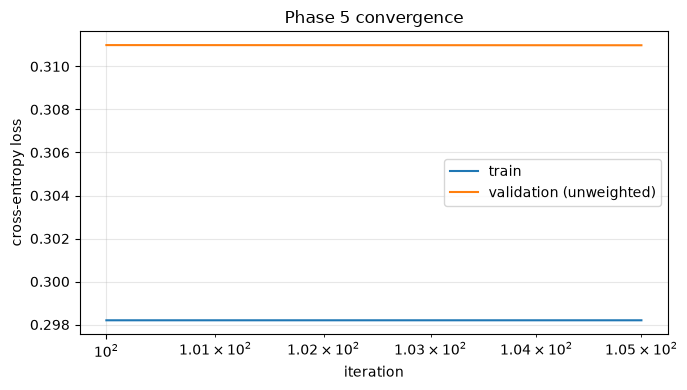

decision threshold tuned on validation F1 over 99 values: 0.38 (F1 0.7704); default 0.5
NOTE: the threshold is tuned and reported on the same validation set, so the tuned-threshold numbers are optimistic.


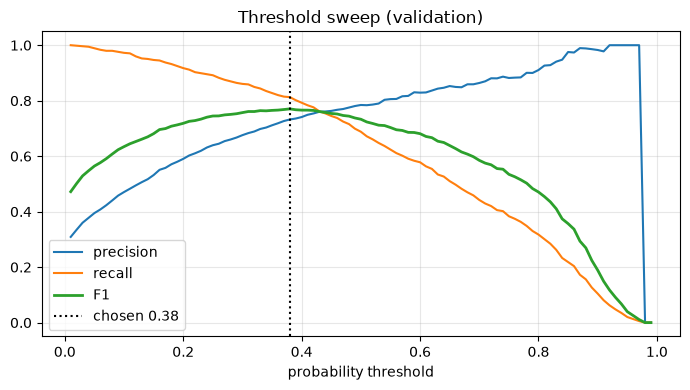

In [106]:
L2_F, CW_F = chosen['l2'], chosen['class_weight']
SW_F = balanced_weights(y_tr) if CW_F else None

t0 = time.time()
final = fit_logreg(X_tr, y_tr, l2=L2_F, sw=SW_F, X_val=X_vl, y_val=y_vl)      # cold start from zeros
W_F, B_F = final['w'], final['b']
print(f'final fit: status {final["status"]}, {final["n_iter"]} iterations, step {final["lr"]:.4f} (= 1/L, L = {final["L"]:.4f}), {time.time()-t0:.0f}s')
print(f'final train loss {final["final_train_loss"]:.6f}   val loss {final["final_val_loss"]:.6f}')
assert final['status'] == 'converged', final['status']

fig, ax = plt.subplots(figsize=(7, 4))
it_tr, l_tr = zip(*final['train_losses']); it_vl, l_vl = zip(*final['val_losses'])
ax.semilogx(it_tr, l_tr, label='train'); ax.semilogx(it_vl, l_vl, label='validation (unweighted)')
ax.set_xlabel('iteration'); ax.set_ylabel('cross-entropy loss'); ax.set_title('Phase 5 convergence'); ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout(); plt.show()

p_vl = predict_proba(X_vl, W_F, B_F)
bt = best_threshold(y_vl, p_vl)
THR_F = bt['threshold']
print(f'decision threshold tuned on validation F1 over {len(bt["grid"])} values: {THR_F:.2f} (F1 {bt["f1"]:.4f}); default 0.5')
print('NOTE: the threshold is tuned and reported on the same validation set, so the tuned-threshold numbers are optimistic.')

fig, ax = plt.subplots(figsize=(7, 4))
P_ = [precision_recall_f1(y_vl, (p_vl >= t).astype(int)) for t in bt['grid']]
ax.plot(bt['grid'], [p[0] for p in P_], label='precision'); ax.plot(bt['grid'], [p[1] for p in P_], label='recall')
ax.plot(bt['grid'], bt['f1_grid'], label='F1', lw=2); ax.axvline(THR_F, color='k', ls=':', label=f'chosen {THR_F:.2f}')
ax.set_xlabel('probability threshold'); ax.set_title('Threshold sweep (validation)'); ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout(); plt.show()

## 9. Final evaluation on the validation set

FINAL model, thr 0.5               acc 0.8747  prec 0.7845  rec 0.6881  F1 0.7331  AUC 0.9331  
FINAL model, tuned thr             acc 0.8788  prec 0.7322  rec 0.8128  F1 0.7704  AUC 0.9331  (thr 0.38)

confusion matrix at tuned threshold  [[TN, FP], [FN, TP]]:
[[1471  162]
 [ 102  443]]
positive rate: true 0.2502, predicted 0.2778
[PASS] validation AUC / F1 / accuracy equal sklearn.metrics to < 1e-9

vs baselines (F1 / AUC):
  majority          F1 0.0000  AUC 0.5000
  hour-only (tuned) F1 0.4020  AUC 0.4850
  final   (tuned)   F1 0.7704  AUC 0.9331
final model beats both baselines on F1 and AUC: True


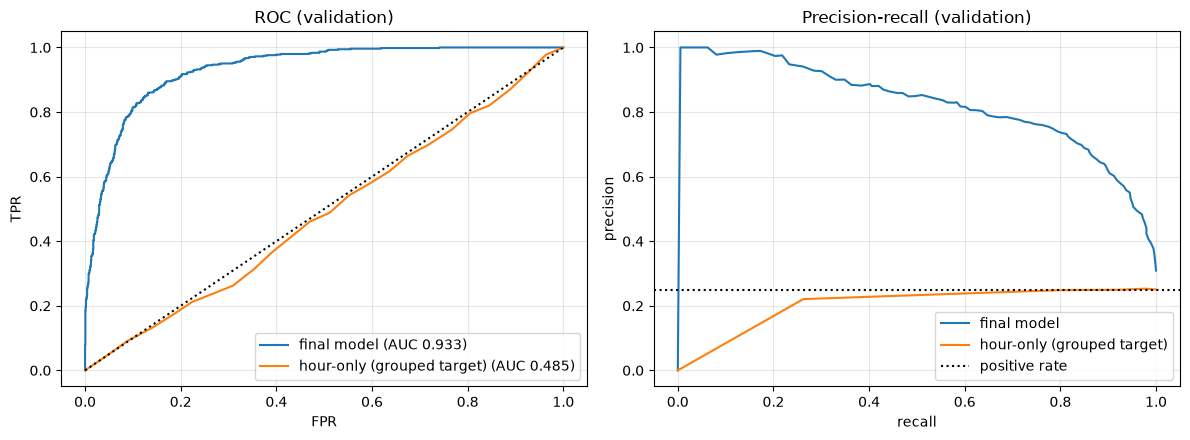

In [107]:
EV05 = evaluate(y_vl, p_vl, 0.5)
EVT = evaluate(y_vl, p_vl, THR_F)
show('FINAL model, thr 0.5', EV05)
show('FINAL model, tuned thr', EVT, f'(thr {THR_F:.2f})')
print('\nconfusion matrix at tuned threshold  [[TN, FP], [FN, TP]]:')
print(np.array(EVT['confusion']))
print(f'positive rate: true {EVT["positive_rate_true"]:.4f}, predicted {EVT["positive_rate_pred"]:.4f}')

# our numpy metrics vs sklearn on the real validation predictions
pred_t = (p_vl >= THR_F).astype(int)
assert abs(EVT['auc'] - roc_auc_score(y_vl, p_vl)) < 1e-9
assert abs(EVT['f1'] - f1_score(y_vl, pred_t)) < 1e-9
assert abs(EVT['accuracy'] - accuracy_score(y_vl, pred_t)) < 1e-12
print('[PASS] validation AUC / F1 / accuracy equal sklearn.metrics to < 1e-9')

print('\nvs baselines (F1 / AUC):')
print(f'  majority          F1 {BASE["majority"]["f1"]:.4f}  AUC {BASE["majority"]["auc"]:.4f}')
print(f'  hour-only (tuned) F1 {BASE["hour_only_tuned"]["f1"]:.4f}  AUC {BASE["hour_only_tuned"]["auc"]:.4f}')
print(f'  final   (tuned)   F1 {EVT["f1"]:.4f}  AUC {EVT["auc"]:.4f}')
BEATS = (EVT['f1'] > BASE['majority']['f1'] and EVT['f1'] > BASE['hour_only_tuned']['f1']
         and EVT['auc'] > BASE['majority']['auc'] and EVT['auc'] > BASE['hour_only_tuned']['auc'])
print('final model beats both baselines on F1 and AUC:', BEATS)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for nm, pv_, c in [('final model', p_vl, 'C0'), ('hour-only (grouped target)', h_res['grouped']['proba'], 'C1')]:
    fpr, tpr = roc_curve(y_vl, pv_); axes[0].plot(fpr, tpr, c, label=f'{nm} (AUC {roc_auc(y_vl, pv_):.3f})')
axes[0].plot([0, 1], [0, 1], 'k:'); axes[0].set_xlabel('FPR'); axes[0].set_ylabel('TPR'); axes[0].set_title('ROC (validation)'); axes[0].legend(); axes[0].grid(alpha=0.3)
grid = np.linspace(0.01, 0.99, 99)
for nm, pv_, c in [('final model', p_vl, 'C0'), ('hour-only (grouped target)', h_res['grouped']['proba'], 'C1')]:
    pr = np.array([precision_recall_f1(y_vl, (pv_ >= t).astype(int))[:2] for t in grid])
    axes[1].plot(pr[:, 1], pr[:, 0], c, label=nm)
axes[1].axhline(y_vl.mean(), color='k', ls=':', label='positive rate'); axes[1].set_xlabel('recall'); axes[1].set_ylabel('precision')
axes[1].set_title('Precision-recall (validation)'); axes[1].legend(); axes[1].grid(alpha=0.3)
fig.tight_layout(); plt.show()

## 10. Chronological check

Same cut as Phase 3: sort by `dteday`, `hr`; the first 80% trains, the last 20% validates. Everything is refit on the earlier part only: group thresholds, preprocessing parameters, polynomial parameters, and the classifier (same L2 and class-weight setting, from zeros). The decision threshold is the one tuned on the seeded split (not re-tuned).

In [108]:
chrono_all = train_all.sort_values(['dteday', 'hr']).reset_index(drop=True)
cut = int(len(chrono_all) * 0.8)
c_tr, c_vl = chrono_all.iloc[:cut], chrono_all.iloc[cut:]
print(f'chronological cut after {c_tr["dteday"].max()}  |  train {len(c_tr)}  val {len(c_vl)}')

pm_c = fit_preprocessor(c_tr)
X1c, nc1 = transform(c_tr, pm_c)
pp_c = fit_poly_p3(X1c, nc1, meta_p3['complexity_spec'])
Xc_tr, _ = build_features(c_tr, pm_c, pp_c, FEATS)
Xc_vl, _ = build_features(c_vl, pm_c, pp_c, FEATS)
THR_C = group_thresholds(c_tr)
yc_tr, yc_vl = make_target(c_tr, THR_C), make_target(c_vl, THR_C)
print(f'positive rate: chrono-train {yc_tr.mean():.3f}   chrono-val {yc_vl.mean():.3f}   (seeded val {y_vl.mean():.3f})')

SWc = balanced_weights(yc_tr) if CW_F else None
rc = fit_logreg(Xc_tr, yc_tr, l2=L2_F, sw=SWc)
pc = predict_proba(Xc_vl, rc['w'], rc['b'])
CH05, CHT = evaluate(yc_vl, pc, 0.5), evaluate(yc_vl, pc, THR_F)
CH_MAJ = evaluate(yc_vl, np.zeros(len(yc_vl)), 0.5)
print(f'chronological fit status: {rc["status"]} ({rc["n_iter"]} iterations)\n')
show('seeded split, tuned thr', EVT, f'(thr {THR_F:.2f})')
show('chronological, same thr', CHT, f'(thr {THR_F:.2f})')
show('chronological, thr 0.5', CH05)
show('chronological, majority class', CH_MAJ)

chronological cut after 2012-08-05  |  train 8708  val 2178


positive rate: chrono-train 0.245   chrono-val 0.640   (seeded val 0.250)

chronological fit status: converged (114 iterations)

seeded split, tuned thr            acc 0.8788  prec 0.7322  rec 0.8128  F1 0.7704  AUC 0.9331  (thr 0.38)
chronological, same thr            acc 0.7461  prec 0.8052  rec 0.7954  F1 0.8003  AUC 0.8125  (thr 0.38)
chronological, thr 0.5             acc 0.7410  prec 0.8463  rec 0.7272  F1 0.7822  AUC 0.8125  
chronological, majority class      acc 0.3604  prec 0.0000  rec 0.0000  F1 0.0000  AUC 0.5000  


## 11. Determinism and artifacts

In [109]:
final2 = fit_logreg(X_tr, y_tr, l2=L2_F, sw=SW_F)
assert np.array_equal(W_F, final2['w']) and B_F == final2['b']
W_SHA = hashlib.sha256(W_F.tobytes()).hexdigest()
print(f'[PASS] two cold-start fits give bit-identical weights; SHA-256(w) = {W_SHA}')

meta5 = {
    'seed': SEED, 'ids': sorted(IDS),
    'target': 'high = cnt > train 0.75-quantile of cnt within (hr, workingday)',
    'quantile': HIGH_QUANTILE,
    'group_thresholds': thresholds_to_json(THR),
    'feature_names': FEATS, 'n_features': len(FEATS),
    'phase4_l1_w_sha256': meta_p4['phase4_l1_w_sha256'], 'phase3_w_sha256': meta_p3['phase3_w_sha256'],
    'l2': L2_F, 'class_weight': CW_F, 'lr': final['lr'], 'lipschitz': final['L'],
    'momentum': True, 'max_iter': FIT_KW['max_iter'], 'tol': FIT_KW['tol'], 'gtol': FIT_KW['gtol'],
    'iterations_used': final['n_iter'], 'status': final['status'],
    'final_train_loss': final['final_train_loss'], 'final_val_loss': final['final_val_loss'],
    'decision_threshold': THR_F, 'selection_tolerance': TOL_SEL,
    'val_metrics_tuned_threshold': EVT, 'val_metrics_threshold_0.5': EV05,
    'baselines': {k: v for k, v in BASE.items()},
    'hour_only_auc_global_target': AUC_HOUR_GLOBAL, 'hour_only_auc_grouped_target': AUC_HOUR_GROUPED,
    'chrono_cut_date': str(c_tr['dteday'].max()),
    'chrono_metrics_same_threshold': CHT, 'chrono_metrics_threshold_0.5': CH05,
    'tuning_table': [{k: v for k, v in t.items() if k not in ('w', 'b')} for t in tuning],
}
sha_saved = save_artifacts_p5(P5_STEM, W_F, B_F, meta5, train_idx, val_idx)
assert sha_saved == W_SHA

# Round trip: reload and reproduce the validation AUC
w_rt, b_rt, meta_rt, _, _ = load_artifacts_p5(P5_STEM)
auc_rt = roc_auc(y_vl, predict_proba(X_vl, w_rt, b_rt))
assert abs(auc_rt - meta_rt['val_metrics_tuned_threshold']['auc']) < 1e-12
assert hashlib.sha256(w_rt.tobytes()).hexdigest() == meta_rt['w_sha256']
print(f'[PASS] artifacts saved and reloaded; validation AUC reproduced ({auc_rt:.12f})')

[PASS] two cold-start fits give bit-identical weights; SHA-256(w) = 8261ee55935a8217090a0637a542efb743cf160c5287570f449c28ef5d530c62
[PASS] artifacts saved and reloaded; validation AUC reproduced (0.933074152935)


## 12. No-sklearn check

In [110]:
# NO-SKLEARN-CHECK  (this cell is excluded from the search)
import ast
hits = []
for i, cell_src in enumerate(get_ipython().user_ns.get('In', [])):
    if '# NO-SKLEARN-CHECK' in cell_src or cell_src.lstrip().startswith(('%', '!')):
        continue
    try:
        tree = ast.parse(cell_src)
    except SyntaxError:
        continue
    for node in ast.walk(tree):
        if isinstance(node, ast.Call) and isinstance(node.func, ast.Attribute) and node.func.attr in ('fit', 'predict'):
            hits.append(('executed cell', i, node.func.attr))
        if isinstance(node, ast.Name) and node.id == 'LogisticRegression':
            hits.append(('executed cell', i, 'LogisticRegression'))
assert not hits, hits
print('[PASS] no sklearn model is fitted or used for prediction anywhere in this notebook (checked on the calls of every executed cell)')

[PASS] no sklearn model is fitted or used for prediction anywhere in this notebook (checked on the calls of every executed cell)


## 13. Pipeline retrospective

All numbers below are read from the artifacts or recomputed from them in this run.

In [111]:
yv = val_df['cnt'].values.astype(float)
w1, b1, _, _, _ = load_artifacts_p1(P1_STEM)
p1_pred = predict(X1_vl, w1, b1)
_, _, m2 = load_artifacts_p2(P2_STEM)
X_p3_vl, _ = build_features(val_df, meta_p1, poly_params, meta_p3['expanded_feature_names'])
p3_pred = predict(X_p3_vl, w_p3, b_p3)

retro = pd.DataFrame([
    ['1 Gradient descent',   'linear',                            len(w1),   r2_score_np(yv, p1_pred), rmse_np(yv, p1_pred), np.nan],
    ['2 Polynomial (d=3)',   'powers of temp/hum/wind/days',      m2['n_new_cols'] + len(w1), m2['val_r2'], m2['val_rmse'], np.nan],
    ['3 Bias-variance',      meta_p3['chosen_rung'][:34],         len(w_p3), r2_score_np(yv, p3_pred), rmse_np(yv, p3_pred), meta_p3['chrono_r2_gd']],
    ['4 Lasso',              'same, L1 (lambda %.3g)' % meta_p4['l1_lambda'], len(FEATS), meta_p4['l1_r2_val'], meta_p4['l1_rmse_val'], meta_p4['chrono_r2_lasso']],
], columns=['phase', 'model', 'n_features', 'val_R2', 'val_RMSE', 'chrono_R2'])
print(retro.to_string(index=False, float_format=lambda v: f'{v:.4f}'))

print('\nPhase 5 (classification, grouped target):')
retro5 = pd.DataFrame([
    ['majority class',               BASE['majority']['accuracy'],        BASE['majority']['f1'],        BASE['majority']['auc'],        np.nan],
    ['hour-only logistic (tuned thr)', BASE['hour_only_tuned']['accuracy'], BASE['hour_only_tuned']['f1'], BASE['hour_only_tuned']['auc'], np.nan],
    ['5 Logistic, %d features (tuned thr)' % len(FEATS), EVT['accuracy'], EVT['f1'], EVT['auc'], CHT['auc']],
], columns=['model', 'val_accuracy', 'val_F1', 'val_AUC', 'chrono_AUC'])
print(retro5.to_string(index=False, float_format=lambda v: f'{v:.4f}'))

             phase                        model  n_features  val_R2  val_RMSE  chrono_R2
1 Gradient descent                       linear          54  0.6781  100.4427        NaN
2 Polynomial (d=3) powers of temp/hum/wind/days          62  0.6858   99.2354        NaN
   3 Bias-variance                 R9 + hr x yr         589  0.9104   53.0038     0.9063
           4 Lasso      same, L1 (lambda 0.251)         470  0.9079   53.7160     0.8938

Phase 5 (classification, grouped target):
                               model  val_accuracy  val_F1  val_AUC  chrono_AUC
                      majority class        0.7498  0.0000   0.5000         NaN
      hour-only logistic (tuned thr)        0.2718  0.4020   0.4850         NaN
5 Logistic, 470 features (tuned thr)        0.8788  0.7704   0.9331      0.8125


### How the five phases connect

- **Phase 1 (linear, 54 features): validation R² 0.6781, RMSE 100.44.** The train-validation gap is only 0.02, so the model is too simple (high bias), not over-fitted.
- **Phase 2 (powers of the continuous columns, degree 3, 62 features): 0.6858, RMSE 99.24.** Curved terms add only +0.008, so curvature is not what is missing. They also left the model fragile in time: its chronological R² is 0.5099, which Phase 3 traced to the powers of `days_since_start`.
- **Phase 3 (interactions of the hour with day type, weather, calendar and year, 589 features): 0.9104, RMSE 53.00, chronological 0.9063.** The interactions are what was missing (+0.225 of R²); replacing the time polynomial by `hr x yr` fixed the out-of-time collapse.
- **Phase 4 (Lasso, 470 features): 0.9079, RMSE 53.72, chronological 0.8938.** The Phase 3 model was not over-fitted, so regularization could not improve it; it compressed it by 119 features for a cost of 0.0025 and gave the verdict on every original column (8 useful, 4 redundant, 2 uninformative).
- **Phase 5 (logistic regression on those 470 features): AUC 0.9331, F1 0.7704, accuracy 0.8788; chronological AUC 0.8125.** How "high demand" is defined mattered most: a model that only knows the hour gets AUC 0.8500 on a single global threshold but 0.4850 on our hour-and-day-type threshold, so the classifier has to use the weather, season and trend.
- **Test predictions.** Regularization never beat the unregularised Phase 3 model, so the final regression is that model refit on all labelled rows and floored at 0 (day-grouped CV R² 0.9209).

Reading the chain as a whole: the biggest gains came from the structure of the model (interactions), not from more curvature or more regularization, and the out-of-time numbers are always a little lower than the random-split ones (0.9104 to 0.9063 in Phase 3, 0.9079 to 0.8938 in Phase 4, AUC 0.9331 to 0.8125 in Phase 5).

In [112]:
# Every number quoted in the Outcome below is printed here
print(f'seed {SEED}; train/val rows {len(train_df)}/{len(val_df)}; features {len(FEATS)}')
print(f'positive rate: train {y_tr.mean():.4f}, val {y_vl.mean():.4f}')
print(f'hour-only AUC: global target {AUC_HOUR_GLOBAL:.4f}, grouped target {AUC_HOUR_GROUPED:.4f}')
print(f'chosen: l2 {L2_F}, class_weight {CW_F}; status {final["status"]}, iterations {final["n_iter"]}, decision threshold {THR_F:.2f}')
print(f'FINAL val @0.5:  acc {EV05["accuracy"]:.4f} F1 {EV05["f1"]:.4f} AUC {EV05["auc"]:.4f}')
print(f'FINAL val @thr:  acc {EVT["accuracy"]:.4f} prec {EVT["precision"]:.4f} rec {EVT["recall"]:.4f} F1 {EVT["f1"]:.4f} AUC {EVT["auc"]:.4f}')
print(f'majority: acc {BASE["majority"]["accuracy"]:.4f} F1 {BASE["majority"]["f1"]:.4f} AUC {BASE["majority"]["auc"]:.4f}')
print(f'hour-only tuned: acc {BASE["hour_only_tuned"]["accuracy"]:.4f} F1 {BASE["hour_only_tuned"]["f1"]:.4f} AUC {BASE["hour_only_tuned"]["auc"]:.4f}')
print(f'chrono @same thr: acc {CHT["accuracy"]:.4f} F1 {CHT["f1"]:.4f} AUC {CHT["auc"]:.4f}; chrono positive rate {yc_vl.mean():.4f}')
print(f'tuning: AUC range {min(t["auc"] for t in tuning):.4f}..{max(t["auc"] for t in tuning):.4f}; F1(best thr) range {min(t["f1_best"] for t in tuning):.4f}..{max(t["f1_best"] for t in tuning):.4f}')
print(f'final model beats both baselines: {BEATS}')
print(f'total runtime {time.time()-T0:.0f}s')

seed 42648; train/val rows 8708/2178; features 470
positive rate: train 0.2441, val 0.2502
hour-only AUC: global target 0.8500, grouped target 0.4850
chosen: l2 0.01, class_weight False; status converged, iterations 105, decision threshold 0.38
FINAL val @0.5:  acc 0.8747 F1 0.7331 AUC 0.9331
FINAL val @thr:  acc 0.8788 prec 0.7322 rec 0.8128 F1 0.7704 AUC 0.9331
majority: acc 0.7498 F1 0.0000 AUC 0.5000
hour-only tuned: acc 0.2718 F1 0.4020 AUC 0.4850
chrono @same thr: acc 0.7461 F1 0.8003 AUC 0.8125; chrono positive rate 0.6396
tuning: AUC range 0.8833..0.9359; F1(best thr) range 0.6795..0.7753
final model beats both baselines: True
total runtime 51s


## Outcome

- The single number version is a bad idea: its limit is 283 bikes, and 63.8% of its "high" hours fall in the 7 rush hours (an even spread would be 29.2%). A model that only knows the hour gets AUC 0.850 on it, but only 0.485 on my version, which is no better than guessing. So on my version the model has to use the weather, the season and the trend.
- The model uses the 470 features that Phase 4 kept. I trained it with our gradient descent (with momentum). It converged in 105 iterations with L2 = 0.01 and no class weights. I tried 12 settings, and AUC stayed between 0.883 and 0.936. Class weights did not help, they only moved the best cut-off. The cut-off I chose is 0.38.
- Results on validation (cut-off 0.38): accuracy 0.879, precision 0.732, recall 0.813, F1 0.770, AUC 0.933. In words: of the 545 truly high hours it found 443 and missed 102, and it wrongly flagged 162 other hours. With the default cut-off 0.5 the accuracy is 0.875 and F1 is 0.733.
- Baselines: "always not high" has accuracy 0.750 but F1 0 and AUC 0.5, and the hour-only model has F1 0.402 and AUC 0.485. So the model clearly beats both. It is only about 13 points more accurate than the lazy baseline, which is why I look at F1 and AUC.
- Time check: on the last 20% of the dates the AUC is 0.8125, against 0.933 on the normal split. In that period 64% of the hours count as "high", because demand grew in 2012 and the limits were learned from earlier months. So accuracy and F1 cannot be compared there, only AUC.
- I was wrong about the last 20% of the dates: I expected a bit worse, but the AUC dropped by about 0.12.
- What surprised me: F1 is only 0.77 although AUC is 0.93. I think this is because an hour with 1 bike more or less than the limit gets a different label even though it is practically the same hour.

<a id="submission"></a>
# 6. Test predictions

The regression model the pipeline recommends: the unregularised Phase 3 interaction model, refit with our own gradient descent on all labelled rows (allowed by the project rules; justified by the day-grouped cross-validation that refits the whole recipe per fold) and floored at 0. `test.csv` is only transformed with parameters fitted on `train.csv`.

In [113]:
"""
Fill sample_submission.csv for test.csv with the unregularised Phase 3 interaction model,
refit with our own gradient descent on ALL labelled rows and floored at 0.

Run:  run_submission()
Nothing is written until every check has passed.
"""


import copy
import hashlib
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.model_selection import GroupKFold   # fold assignment only; no sklearn model is fitted


SEED = 42648
IDS = ["16002932", "16006616", "16004208"]
DATA_DIR = Path("Datasets")
P3_STEM = "bias_variance_artifacts"
OUT_CSV = Path("sample_submission.csv")

FLOOR = 0.0
GD_TOL = 1e-9   # momentum (accelerated) GD stopped on a tight relative loss change
GD_MAX_ITER = 200_000
CV_MIN_R2 = 0.80
RUNTIME_BUDGET_S = 900   # 15 minutes: a warning, never a failure
LOSS_GAP_MAX = 2e-3
R2_GAP_MAX = 1e-3
HOUR_FLAG = 100.0
REFERENCE_CV_R2 = (0.8394, 0.8555)   # raw, floored: the PREVIOUS 127-feature Phase 3 model, printed for comparison only


# --------------------------------------------------------------------------- #
# Inputs and recipe
# --------------------------------------------------------------------------- #

def check_seed() -> None:
    assert compute_seed(IDS) == SEED, "team seed mismatch"
    print(f"[PASS] seed {SEED} recomputed from team IDs")


def load_inputs() -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    train = pd.read_csv(DATA_DIR / "train.csv")
    test = pd.read_csv(DATA_DIR / "test.csv")
    template = pd.read_csv(DATA_DIR / "sample_submission.csv")
    assert train.shape[0] == 10886 and test.shape[0] == 574 and template.shape[0] == 574, \
        (train.shape, test.shape, template.shape)
    assert list(template["instant"]) == list(test["instant"]), "template instant order differs from test.csv"
    print(f"[PASS] inputs: train {train.shape}, test {test.shape}, template {template.shape}; instant order matches")
    return train, test, template


def load_spec() -> tuple[dict, list[str], str]:
    meta = _load_json(P3_STEM)
    return meta["complexity_spec"], meta["expanded_feature_names"], meta["phase3_w_sha256"]


def fit_design(fit_df: pd.DataFrame, spec: dict) -> tuple[dict, list[str], dict]:
    """Phase 1 preprocessor and Phase 3 expansion, fitted on fit_df only."""
    pre = fit_preprocessor(fit_df)
    X1, names1 = transform(fit_df, pre)
    poly = fit_poly_p3(X1, names1, spec)
    return pre, names1, poly


def apply_design(df: pd.DataFrame, pre: dict, names1: list[str], poly: dict,
                 expected_names: list[str]) -> np.ndarray:
    """Transform df with already-fitted parameters; the column names must equal the Phase 3 artifact's."""
    X1, _ = transform(df, pre)
    Xe, names = transform_poly_p3(X1, names1, poly)
    assert names == expected_names, "design columns differ from the Phase 3 artifact"
    return Xe


# --------------------------------------------------------------------------- #
# Fitting
# --------------------------------------------------------------------------- #

def fit_gd(X: np.ndarray, y: np.ndarray) -> dict:
    """Own gradient descent from zero weights at step 0.9/L; raises unless converged."""
    L = lipschitz_constant(X)
    res = gd_fit(X, y, lr=0.9 / L, max_iter=GD_MAX_ITER, tol=GD_TOL, record_every=500, momentum=True)
    if res["status"] != "converged":
        raise RuntimeError(f"GD status {res['status']} after {res['n_iter']} iterations")
    res["L"], res["lr"] = L, 0.9 / L
    return res


def fit_reference(X: np.ndarray, y: np.ndarray) -> tuple[np.ndarray, float]:
    """Closed-form least squares, only as a convergence reference."""
    A = np.hstack([X, np.ones((len(X), 1))])
    th = np.linalg.lstsq(A, y, rcond=None)[0]
    return th[:-1], float(th[-1])


def check_reference(X: np.ndarray, y: np.ndarray, gd: dict) -> dict:
    w_cf, b_cf = fit_reference(X, y)
    loss_gd = mse_loss(X, y, gd["w"], gd["b"])
    loss_cf = mse_loss(X, y, w_cf, b_cf)
    gap = abs(loss_gd - loss_cf) / (abs(loss_cf) + 1e-12)
    r2_gd = r2_score_np(y, predict(X, gd["w"], gd["b"]))
    r2_cf = r2_score_np(y, predict(X, w_cf, b_cf))
    assert gap < LOSS_GAP_MAX, f"GD vs lstsq training-loss gap {gap:.2e} >= {LOSS_GAP_MAX}"
    assert abs(r2_gd - r2_cf) < R2_GAP_MAX, f"train R2 differs: {r2_gd:.6f} vs {r2_cf:.6f}"
    print(f"[PASS] GD vs lstsq: relative loss gap {gap:.2e}, train R2 {r2_gd:.6f} vs {r2_cf:.6f}")
    return {"loss_gap": float(gap), "r2_gd": float(r2_gd), "r2_lstsq": float(r2_cf)}


def cv_day_grouped(train: pd.DataFrame, spec: dict, names: list[str]) -> dict:
    """5-fold GroupKFold by day; every fold refits preprocessing, expansion and GD."""
    groups = train["dteday"].values
    rows = []
    for k, (a, v) in enumerate(GroupKFold(n_splits=5).split(train, groups=groups), 1):
        fa, fv = train.iloc[a], train.iloc[v]
        pre, n1, poly = fit_design(fa, spec)
        Xa = apply_design(fa, pre, n1, poly, names)
        Xv = apply_design(fv, pre, n1, poly, names)
        ya, yv = fa["cnt"].values.astype(float), fv["cnt"].values.astype(float)
        res = fit_gd(Xa, ya)
        p = predict(Xv, res["w"], res["b"])
        pc = np.clip(p, FLOOR, None)
        row = dict(fold=k, n_val=len(v), iters=res["n_iter"],
                   r2=r2_score_np(yv, p), rmse=rmse_np(yv, p),
                   r2_floor=r2_score_np(yv, pc), rmse_floor=rmse_np(yv, pc))
        rows.append(row)
        print(f"  fold {k}: val n={len(v)}  iters {res['n_iter']}  R2 {row['r2']:.4f} / floored {row['r2_floor']:.4f}  "
              f"RMSE {row['rmse']:.2f} / floored {row['rmse_floor']:.2f}")
    df = pd.DataFrame(rows)
    out = {"folds": rows,
           "mean_r2": float(df["r2"].mean()), "std_r2": float(df["r2"].std(ddof=0)),
           "mean_rmse": float(df["rmse"].mean()),
           "mean_r2_floor": float(df["r2_floor"].mean()), "std_r2_floor": float(df["r2_floor"].std(ddof=0)),
           "mean_rmse_floor": float(df["rmse_floor"].mean())}
    print(f"[CV] day-grouped 5-fold: raw R2 {out['mean_r2']:.4f} +-{out['std_r2']:.4f} (RMSE {out['mean_rmse']:.2f}); "
          f"floored R2 {out['mean_r2_floor']:.4f} +-{out['std_r2_floor']:.4f} (RMSE {out['mean_rmse_floor']:.2f})")
    print(f"     previous 127-feature model, for comparison: raw {REFERENCE_CV_R2[0]}, floored {REFERENCE_CV_R2[1]}")
    assert out["mean_r2_floor"] >= CV_MIN_R2, f"mean floored CV R2 {out['mean_r2_floor']:.4f} < {CV_MIN_R2}"
    return out


# --------------------------------------------------------------------------- #
# Leakage test, prediction, report, outputs
# --------------------------------------------------------------------------- #

def leakage_test(train: pd.DataFrame, test: pd.DataFrame, pre: dict) -> None:
    before = copy.deepcopy(pre)
    transform(test, pre)                      # transform must not refit anything
    assert pre == before, "transform changed the fitted preprocessor"
    pre_all = fit_preprocessor(pd.concat([train, test], ignore_index=True))
    differs = any(abs(pre["scaler_means"][c] - pre_all["scaler_means"][c]) > 1e-9 for c in pre["numeric_cols"])
    assert differs, "fitting on train + test gave identical parameters: the test is not detecting leakage"
    print("[PASS] no test leakage: transform leaves the fitted parameters unchanged and they differ from train + test parameters")


def predict_floor(X_test: np.ndarray, w: np.ndarray, b: float) -> tuple[np.ndarray, dict]:
    raw = predict(X_test, w, b)
    assert raw.shape[0] == 574 and np.isfinite(raw).all(), "test predictions are not 574 finite values"
    pred = np.clip(raw, FLOOR, None)
    n_clip = int((raw < FLOOR).sum())
    assert (pred >= 0).all()
    info = {"n_clipped": n_clip, "share_clipped": n_clip / len(raw), "raw_min": float(raw.min())}
    print(f"[PASS] 574 finite predictions; clipped at {FLOOR}: {n_clip} values ({100*info['share_clipped']:.1f}%), raw min {raw.min():.2f}")
    return pred, info


def plausibility_report(train: pd.DataFrame, test: pd.DataFrame, pred: np.ndarray) -> dict:
    print(f"\nprediction min {pred.min():.2f}  mean {pred.mean():.2f}  max {pred.max():.2f}   |   train cnt mean {train['cnt'].mean():.2f}")
    hourly_train = train.groupby("hr")["cnt"].mean()
    hourly_pred = pd.Series(pred, index=test.index).groupby(test["hr"].values).mean()
    comp = pd.DataFrame({"train_mean": hourly_train, "test_pred_mean": hourly_pred})
    comp["diff"] = comp["test_pred_mean"] - comp["train_mean"]
    print(comp.round(1).to_string())
    worst = float(comp["diff"].abs().max())
    flag = " (FLAG: above %.0f; test days are only the 20th of each month, so a gap is not an error by itself)" % HOUR_FLAG if worst > HOUR_FLAG else ""
    print(f"max |hourly mean difference| = {worst:.1f}{flag}")
    return {"max_hourly_abs_diff": worst, "flagged": bool(worst > HOUR_FLAG)}


def write_submission(test: pd.DataFrame, pred: np.ndarray) -> None:
    sub = pd.DataFrame({"instant": test["instant"].values, "cnt": pred})
    sub.to_csv(OUT_CSV, index=False, float_format="%.6f")
    chk = pd.read_csv(OUT_CSV)
    assert list(chk.columns) == ["instant", "cnt"] and len(chk) == 574
    assert list(chk["instant"]) == list(test["instant"]) and chk["cnt"].notna().all() and (chk["cnt"] >= 0).all()
    print(f"[SAVED] {OUT_CSV}  ({len(chk)} rows)")


def write_audit(meta: dict) -> None:
    _store_json("submission_fit", meta)     # audit record kept in memory
    print("[STORED] audit record of the final fit")


# --------------------------------------------------------------------------- #

def run_submission() -> None:
    t0 = time.time()
    check_seed()
    train, test, _ = load_inputs()
    spec, names, p3_sha = load_spec()
    y = train["cnt"].values.astype(float)

    print("\nDay-grouped cross-validation of the exact recipe (refits everything per fold):")
    cv = cv_day_grouped(train, spec, names)

    print("\nFinal fit on all labelled rows:")
    pre, n1, poly = fit_design(train, spec)
    X = apply_design(train, pre, n1, poly, names)
    X_test = apply_design(test, pre, n1, poly, names)
    assert X.shape == (10886, len(names)) and X_test.shape == (574, len(names)), (X.shape, X_test.shape)
    gd = fit_gd(X, y)
    p_tr = predict(X, gd["w"], gd["b"])
    train_r2, train_rmse = r2_score_np(y, p_tr), rmse_np(y, p_tr)
    print(f"GD: {gd['n_iter']} iterations, status {gd['status']}, step {gd['lr']:.5f} (0.9/L, L={gd['L']:.4f}); "
          f"train R2 {train_r2:.4f}, RMSE {train_rmse:.2f}")
    ref = check_reference(X, y, gd)
    leakage_test(train, test, pre)

    gd2 = fit_gd(X, y)
    assert np.array_equal(gd["w"], gd2["w"]) and gd["b"] == gd2["b"], "GD is not deterministic"
    w_sha = hashlib.sha256(gd["w"].tobytes()).hexdigest()
    print(f"[PASS] second fit gives bit-identical weights; SHA-256(w) = {w_sha}")

    pred, clip_info = predict_floor(X_test, gd["w"], gd["b"])
    rep = plausibility_report(train, test, pred)

    runtime = time.time() - t0
    meta = {
        "seed": SEED, "ids": sorted(IDS), "rows_used_for_fit": int(len(train)), "n_features": int(X.shape[1]),
        "model": "unregularised Phase 3 interaction model (own GD), refit on all labelled rows",
        "complexity_spec": spec, "floor": FLOOR,
        "gd": {"momentum": True, "lr": gd["lr"], "lipschitz": gd["L"], "tol": GD_TOL, "max_iter": GD_MAX_ITER,
               "iterations": gd["n_iter"], "status": gd["status"]},
        "train_r2": float(train_r2), "train_rmse": float(train_rmse), "reference_check": ref,
        "cv_day_grouped": cv, "clipping": clip_info, "plausibility": rep,
        "weights_sha256": w_sha, "phase3_artifact_w_sha256_for_reference": p3_sha,
        "prediction_summary": {"min": float(pred.min()), "mean": float(pred.mean()), "max": float(pred.max())},
        "runtime_seconds": round(runtime, 1),
    }
    write_audit(meta)
    write_submission(test, pred)
    print(f"\ntotal runtime {time.time() - t0:.0f}s")
    elapsed = time.time() - t0
    if elapsed > RUNTIME_BUDGET_S:
        print(f"WARNING: runtime {elapsed:.0f}s exceeded the {RUNTIME_BUDGET_S // 60}-minute budget (the output above is still valid)")

In [114]:
run_submission()
print()
print(pd.read_csv('sample_submission.csv').head())

[PASS] seed 42648 recomputed from team IDs
[PASS] inputs: train (10886, 15), test (574, 14), template (574, 2); instant order matches

Day-grouped cross-validation of the exact recipe (refits everything per fold):


  fold 1: val n=2175  iters 1586  R2 0.9213 / floored 0.9239  RMSE 51.35 / floored 50.50


  fold 2: val n=2175  iters 1444  R2 0.9259 / floored 0.9313  RMSE 50.50 / floored 48.62


  fold 3: val n=2175  iters 1484  R2 0.8944 / floored 0.9004  RMSE 56.63 / floored 55.00


  fold 4: val n=2175  iters 2211  R2 0.9191 / floored 0.9272  RMSE 51.81 / floored 49.14


  fold 5: val n=2186  iters 588  R2 0.9131 / floored 0.9216  RMSE 53.12 / floored 50.47
[CV] day-grouped 5-fold: raw R2 0.9148 +-0.0110 (RMSE 52.68); floored R2 0.9209 +-0.0107 (RMSE 50.75)
     previous 127-feature model, for comparison: raw 0.8394, floored 0.8555

Final fit on all labelled rows:


GD: 1448 iterations, status converged, step 0.15948 (0.9/L, L=5.6432); train R2 0.9258, RMSE 49.35


[PASS] GD vs lstsq: relative loss gap 4.74e-06, train R2 0.925780 vs 0.925780
[PASS] no test leakage: transform leaves the fitted parameters unchanged and they differ from train + test parameters


[PASS] second fit gives bit-identical weights; SHA-256(w) = 41bc946fa42fe7d82902c4dadfd586e66646b269935978e42e79af5f7723f2ad
[PASS] 574 finite predictions; clipped at 0.0: 33 values (5.7%), raw min -105.10

prediction min 0.00  mean 197.44  max 782.37   |   train cnt mean 191.57
    train_mean  test_pred_mean  diff
0         55.1            54.6  -0.6
1         33.9            33.7  -0.1
2         22.9            21.6  -1.3
3         11.8            12.0   0.2
4          6.4             8.7   2.2
5         19.8            22.9   3.1
6         76.3            85.2   8.9
7        213.1           230.9  17.8
8        362.8           388.2  25.4
9        221.8           231.7   9.9
10       175.1           179.4   4.3
11       210.7           210.5  -0.2
12       256.5           260.2   3.7
13       257.8           258.1   0.3
14       243.4           244.3   0.9
15       254.3           257.9   3.6
16       316.4           327.3  10.9
17       468.8           490.0  21.2
18       430.9   

## Pipeline fingerprint

The weight hash of every phase and the hash of the submission file, so a re-run can be compared with this one.

In [115]:
import hashlib
fp = {
    'phase 1 w_sha256':       _load_json('gradient_descent_artifacts')['w_sha256'],
    'phase 2 w_sha256':       _load_json('polynomial_regression_artifacts')['phase2_w_sha256'],
    'phase 3 w_sha256':       _load_json('bias_variance_artifacts')['phase3_w_sha256'],
    'phase 4 lasso w_sha256': _load_json('regularization_artifacts')['phase4_l1_w_sha256'],
    'phase 5 w_sha256':       _load_json('logistic_regression_artifacts')['w_sha256'],
    'submission w_sha256':    _load_json('submission_fit')['weights_sha256'],
    'sample_submission.csv':  hashlib.sha256(open('sample_submission.csv', 'rb').read()).hexdigest(),
}
for k, v in fp.items(): print(f'{k:<24} {v}')

phase 1 w_sha256         8536e02b0ec993ce09bdf858ad70cb9e83e37609149d8808dc856fba59f0c6f4
phase 2 w_sha256         65052a5a4a6d1c747ca5c7353ad8a8d5ba3c0fb4c5c56adeeae1bd7fb346093d
phase 3 w_sha256         b40be082bc63853901f47040cb5944754406d6e5372bcaccfc67c0e022de8363
phase 4 lasso w_sha256   0538aebea08744221d4deaa72526332337aa723f486b87c231967e275f204b26
phase 5 w_sha256         8261ee55935a8217090a0637a542efb743cf160c5287570f449c28ef5d530c62
submission w_sha256      41bc946fa42fe7d82902c4dadfd586e66646b269935978e42e79af5f7723f2ad
sample_submission.csv    8d4c5ce29a4e280cd29d6c8ebfe889921684eb3d3870aa3fa786dba15967c2fd
